# FPA Project — Exploratory Data Analysis (full version)

**Dataset:** Walmart Recruiting – Store Sales Forecasting (Kaggle, 2014)
**Builds on:** `FPA_Project_EDA_ part_dataset_creation.ipynb` (teammate). Same methodology, same variable names (`stores`, `train`, `features`, `test`, `calendar`, `pairs`, `panel`, `holiday`, `split_date`, `subset`, `cols`), same subset (departments 1–3).
**Produces:** `Data/depts_1_to_3_stat.csv` and `Data/week_calendar.csv`, read by the modelling notebook `FPA_Project_Statistical_Models.ipynb`.

### How to read this notebook

Every output (tables and charts) is already saved inside the notebook, so it can be **read without running anything**. Each step follows the same pattern:

1. **Question**: what I want to know, in plain words.
2. **Code**: with comments on almost every line. Where a pandas trick is not obvious, a short *"Code explained"* box comes before or after it.
3. **Output.**
4. **What I see / Why it matters**: the interpretation, and what it changes for the models.

The notebook starts slowly on purpose: first I look at every file with `head()`, `tail()`, `info()` and `describe()`, and only then I draw conclusions.

**Amounts** (sales, errors) are weekly **US dollars**. In the text I write them without the dollar sign (e.g. 57.6k = 57,600 dollars): Jupyter reads text between two `$` signs as a maths formula, so two dollar amounts in the same sentence would be displayed as garbled maths.

## Map of the notebook

| Part | Content | Main question |
|---|---|---|
| **0** | Setup | — |
| **A** | Meet the data: `stores`, `train`, `features`, `test`, `sampleSubmission` | What is in each file? Is it clean? How do the files connect? |
| **B** | The whole dataset as time series | How do Walmart's sales behave overall (trend, seasonality, stores, departments, holidays)? |
| **C** | Data processing (teammate's pipeline, explained) | How do we turn raw rows into clean weekly series? |
| **D** | Why departments 1–3 | Which series can a statistical model use, and why these? |
| **E** | Deep dive into departments 1–3 | What do our 135 series look like? |
| **F** | Calendar and holidays | Which weeks are special, and do they stay in the same week each year? |
| **G** | Statistical prerequisites for ARIMA / SARIMA / SARIMAX | Seasonality, trend, variance, stationarity, ACF / PACF, data budget, baselines |
| **H** | Summary and export | What did we learn, and what file do the models read? |

### Small glossary (used everywhere below)

| Word | Meaning |
|---|---|
| **series** | the weekly sales of one `(Store, Dept)` pair over time, e.g. *Store 1 – Dept 1* |
| **panel** | many series stacked in one long table (one row = one series × one week) |
| **train part / holdout part** | the teammate's split of `train.csv`: first 104 weeks to fit, last 39 weeks to score (`split == "train"` / `split == "test"`) |
| **forecast set** | `test.csv`: 39 future weeks with **no** sales; Kaggle's exam sheet |
| **holiday week** | a week with `IsHoliday == True` (Super Bowl, Labor Day, Thanksgiving, Christmas). Counts 5× in the metric |
| **WMAE** | Weighted Mean Absolute Error, the competition metric (average error in dollars, holiday weeks × 5) |
| **lag k** | the value k weeks earlier; *lag 52* = same week last year |

# 0. Setup

In [1]:
# --- libraries ---
import pandas as pd                    # tables (DataFrames)
import numpy as np                     # numbers and arrays
import matplotlib.pyplot as plt        # plots
import seaborn as sns                  # nicer statistical plots, built on top of matplotlib
import warnings

from dateutil.easter import easter     # gives the date of Easter Sunday for a given year
from scipy import stats                # Box-Cox transformation (section G.3)
from statsmodels.tsa.stattools import adfuller, kpss, acf          # stationarity tests, autocorrelation
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf      # ACF / PACF plots
warnings.filterwarnings("ignore")      # hide library warnings (after the imports, because statsmodels re-enables some on import)

# if something is missing:  pip install seaborn statsmodels

# --- settings ---
DATA_DIR = "Data/"        # the teammate used "/content/" on Colab -> change this line if needed
DEPTS = [1, 2, 3]         # departments used for the statistical models (teammate's choice)
FOCUS_STORE = 1           # store studied in detail (teammate's choice)

pd.set_option("display.max_columns", 30)      # print all columns of a table
pd.set_option("display.width", 160)           # wider printed tables
sns.set_theme(style="whitegrid")              # light grid background for every plot

# Part A — Meet the data

Five csv files. Before any analysis I look at each one the same way:

| Check | pandas | Why |
|---|---|---|
| first rows | `.head()` | see the columns and what one row means |
| last rows | `.tail()` | check the end of the file (dates, sorting) |
| size | `.shape` | number of rows and columns |
| types and missing values | `.info()` | numbers stored as text? empty cells? |
| summary statistics | `.describe()` | ranges, strange values (negatives, outliers) |
| distinct values | `.nunique()` / `.value_counts()` | how many stores, departments, dates… |

## A.1 `stores.csv` — one row per store

**Question:** what do we know about the 45 stores?

In [2]:
stores = pd.read_csv(DATA_DIR + "stores.csv")      # same as the teammate, only the folder changes
stores.head()

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


In [3]:
stores.tail()

,Store,Type,Size
40,41,A,196321
41,42,C,39690
42,43,C,41062
43,44,C,39910
44,45,B,118221


In [4]:
print("shape:", stores.shape)       # (number of rows, number of columns)
stores.info()                       # column types and number of non-empty values

shape: (45, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Store   45 non-null     int64 
 1   Type    45 non-null     object
 2   Size    45 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 1.2+ KB


In [5]:
# describe(include="all") summarises numbers (mean, min, max...) AND text columns (count, unique, most frequent)
stores.describe(include="all")

,Store,Type,Size
count,45.000000,45,45.000000
unique,NaN,3,NaN
top,NaN,A,NaN
freq,NaN,22,NaN
mean,23.000000,NaN,130287.600000
std,13.133926,NaN,63825.271991
min,1.000000,NaN,34875.000000
25%,12.000000,NaN,70713.000000
50%,23.000000,NaN,126512.000000
75%,34.000000,NaN,202307.000000


In [6]:
stores["Type"].value_counts()       # how many stores of each type (teammate's cell)

Type
A    22
B    17
C     6
Name: count, dtype: int64

In [7]:
# store size per type: one row per type, the usual statistics as columns
stores.groupby("Type")["Size"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
Type,,,,,,,,
A,22.0,177248.0,49393.0,39690.0,155841.0,202406.0,203819.0,219622.0
B,17.0,101191.0,32371.0,34875.0,93188.0,114533.0,123737.0,140167.0
C,6.0,40542.0,1304.0,39690.0,39745.0,39910.0,40774.0,42988.0


> **Code explained — `groupby(...)[...].describe()`**
> `groupby("Type")` cuts the table into 3 groups (A, B, C). `["Size"]` keeps only the column I care about, and `.describe()` computes count, mean, std, min, quartiles and max **inside each group**.

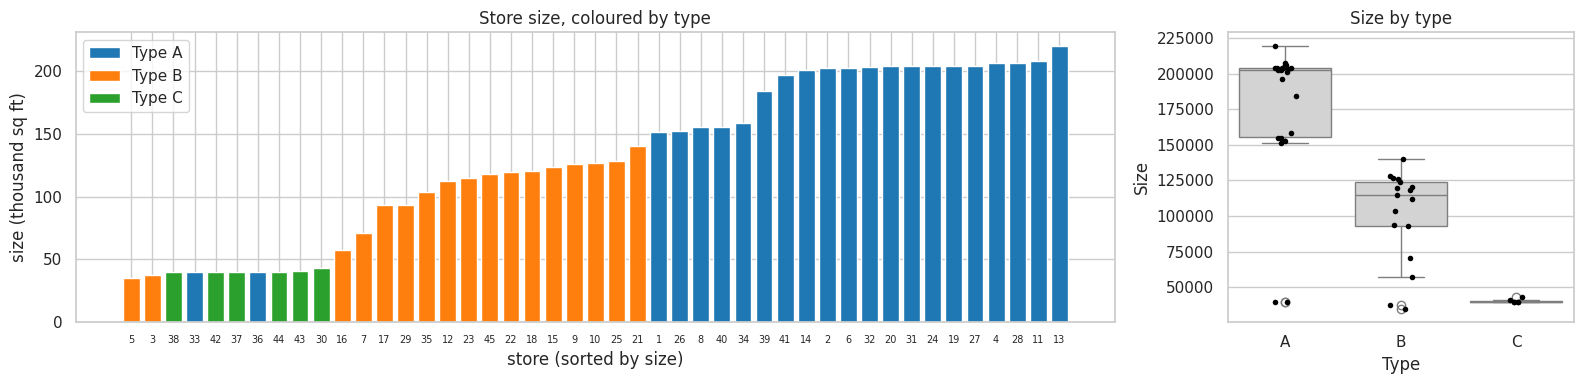

In [8]:
# picture: the 45 stores sorted by size, coloured by type
stores_sorted = stores.sort_values("Size").reset_index(drop=True)      # smallest store first
type_colors = {"A": "tab:blue", "B": "tab:orange", "C": "tab:green"}

fig, axes = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [3, 1]})

# left: one bar per store
axes[0].bar(stores_sorted.index, stores_sorted["Size"] / 1000, color=stores_sorted["Type"].map(type_colors))
axes[0].set_xticks(stores_sorted.index)
axes[0].set_xticklabels(stores_sorted["Store"], fontsize=7)       # label = store number
axes[0].set_xlabel("store (sorted by size)")
axes[0].set_ylabel("size (thousand sq ft)")
axes[0].set_title("Store size, coloured by type")
for t, c in type_colors.items():                                   # manual legend
    axes[0].bar(0, 0, color=c, label=f"Type {t}")
axes[0].legend()

# right: distribution of size per type
sns.boxplot(data=stores, x="Type", y="Size", order=["A", "B", "C"], color="lightgrey", ax=axes[1])
sns.stripplot(data=stores, x="Type", y="Size", order=["A", "B", "C"], color="black", size=4, ax=axes[1])
axes[1].set_title("Size by type")
plt.tight_layout()
plt.show()

**What I see**

- 45 stores, no missing values: **22 type A, 17 type B, 6 type C**.
- The type is mostly a **size class**: A ≈ 200k sq ft (median), B ≈ 115k, C ≈ 40k.
- But not perfectly: stores **33 and 36 are type A** with only ~40k sq ft (as small as type C), and stores **3 and 5 (type B) are the two smallest stores** of the whole chain. Since the data is anonymised, `Size` is the more reliable number and `Type` a rough label.

**Why it matters:** size and type are **constant for a store**, so they can't explain the ups and downs **inside** one series. That's what a time-series model forecasts. They only explain why some series are bigger than others (section B.3).

## A.2 `train.csv` — the sales history (our target)

**Question:** what does one row mean, what period is covered, and is the target clean?

In [9]:
train = pd.read_csv(DATA_DIR + "train.csv")
train["Date"] = pd.to_datetime(train["Date"])      # text "2010-02-05" -> real date, so we can sort and compute with it
train.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [10]:
train.tail()

,Store,Dept,Date,Weekly_Sales,IsHoliday
421565,45,98,2012-09-28,508.37,False
421566,45,98,2012-10-05,628.10,False
421567,45,98,2012-10-12,1061.02,False
421568,45,98,2012-10-19,760.01,False
421569,45,98,2012-10-26,1076.80,False


In [11]:
print("shape:", train.shape)
train.info()

shape: (421570, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[ns]
 3   Weekly_Sales  421570 non-null  float64       
 4   IsHoliday     421570 non-null  bool          
dtypes: bool(1), datetime64[ns](1), float64(1), int64(2)
memory usage: 13.3 MB


In [12]:
train.describe().round(2)          # only numeric columns: Store, Dept, Weekly_Sales

,Store,Dept,Date,Weekly_Sales
count,421570.00,421570.00,421570,421570.00
mean,22.20,44.26,2011-06-18 08:30:31.963375104,15981.26
min,1.00,1.00,2010-02-05 00:00:00,-4988.94
25%,11.00,18.00,2010-10-08 00:00:00,2079.65
50%,22.00,37.00,2011-06-17 00:00:00,7612.03
75%,33.00,74.00,2012-02-24 00:00:00,20205.85
max,45.00,99.00,2012-10-26 00:00:00,693099.36
std,12.79,30.49,NaN,22711.18


In [13]:
train.nunique()                    # number of distinct values per column

Store               45
Dept                81
Date               143
Weekly_Sales    359464
IsHoliday            2
dtype: int64

**Is `(Store, Dept, Date)` really a unique key?** If two rows had the same store, department and week, we wouldn't know which sales number is right.

In [14]:
n_dup = train.duplicated(subset=["Store", "Dept", "Date"]).sum()     # rows that repeat an earlier key
print("duplicated (Store, Dept, Date) rows:", n_dup)
print("number of series (Store, Dept):", train.groupby(["Store", "Dept"]).ngroups)

duplicated (Store, Dept, Date) rows: 0
number of series (Store, Dept): 3331


**Are the dates a clean weekly calendar?** I check three things: the first and last date, that every date is a Friday, and that consecutive dates are exactly 7 days apart (no missing week in the calendar itself).

In [15]:
all_dates = pd.Series(sorted(train["Date"].unique()))       # the distinct dates, sorted

print("first date :", all_dates.min().date())
print("last date  :", all_dates.max().date())
print("number of weeks:", len(all_dates))
print("weekdays found :", all_dates.dt.day_name().unique())             # should be only 'Friday'
print("gaps between consecutive dates (days):", all_dates.diff().dt.days.dropna().unique())   # should be only 7

first date : 2010-02-05
last date  : 2012-10-26
number of weeks: 143
weekdays found : ['Friday']
gaps between consecutive dates (days): [7.]


In [16]:
# the holiday weeks of the train file (teammate's cell)
train[train["IsHoliday"]]["Date"].unique()

<DatetimeArray>
['2010-02-12 00:00:00', '2010-09-10 00:00:00', '2010-11-26 00:00:00', '2010-12-31 00:00:00', '2011-02-11 00:00:00', '2011-09-09 00:00:00',
 '2011-11-25 00:00:00', '2011-12-30 00:00:00', '2012-02-10 00:00:00', '2012-09-07 00:00:00']
Length: 10, dtype: datetime64[ns]

**The target `Weekly_Sales`.** The teammate noted it can be 0 or negative (returns). How often, and how big are the values?

In [17]:
sales = train["Weekly_Sales"]

summary_sign = pd.DataFrame({
    "rows": [(sales < 0).sum(), (sales == 0).sum(), (sales > 0).sum()],
}, index=["negative", "zero", "positive"])
summary_sign["% of rows"] = (summary_sign["rows"] / len(sales) * 100).round(2)
print(summary_sign, "\n")

# quantiles: the value below which x% of rows fall
print(sales.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1.0]).round(0))

            rows  % of rows
negative    1285       0.30
zero          73       0.02
positive  420212      99.68 

0.01         5.0
0.05        60.0
0.25      2080.0
0.50      7612.0
0.75     20206.0
0.95     61202.0
0.99    106480.0
1.00    693099.0
Name: Weekly_Sales, dtype: float64


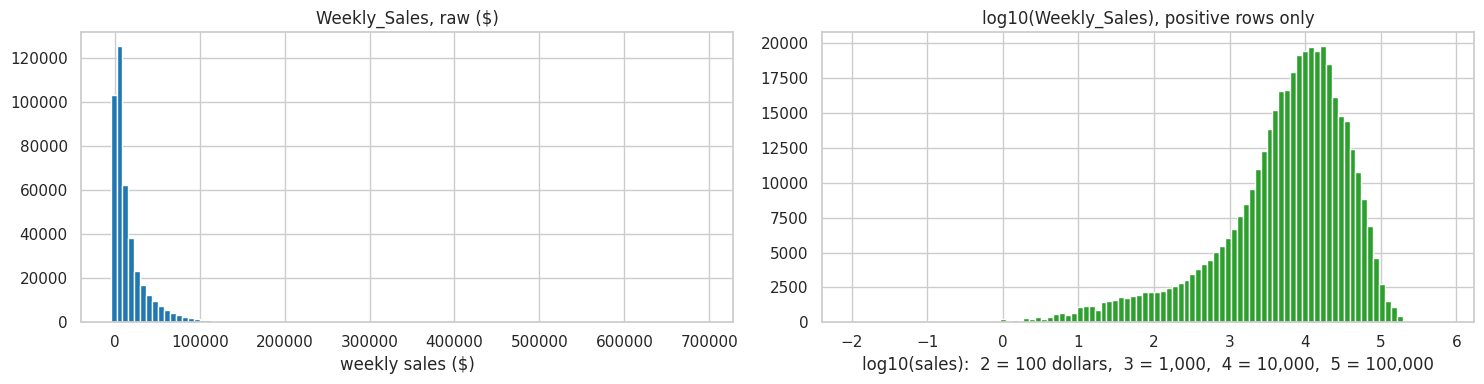

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# left: raw values. Very skewed: most rows are small, a few are huge
axes[0].hist(sales, bins=100, color="tab:blue")
axes[0].set_title("Weekly_Sales, raw ($)")
axes[0].set_xlabel("weekly sales ($)")

# right: log10 of the positive values -> the shape becomes readable
axes[1].hist(np.log10(sales[sales > 0]), bins=100, color="tab:green")
axes[1].set_title("log10(Weekly_Sales), positive rows only")
axes[1].set_xlabel("log10(sales):  2 = 100 dollars,  3 = 1,000,  4 = 10,000,  5 = 100,000")
plt.tight_layout()
plt.show()

In [19]:
# how many rows does each store / department have?
rows_per_store = train.groupby("Store").size()
rows_per_dept = train.groupby("Dept").size()
print("rows per store:", rows_per_store.describe().round(0).to_dict())
print("rows per dept :", rows_per_dept.describe().round(0).to_dict())
print("departments with the fewest rows:", rows_per_dept.sort_values().head(5).to_dict())

rows per store: {'count': 45.0, 'mean': 9368.0, 'std': 1215.0, 'min': 6222.0, '25%': 9443.0, '50%': 9864.0, '75%': 10148.0, 'max': 10474.0}
rows per dept : {'count': 81.0, 'mean': 5205.0, 'std': 1896.0, 'min': 12.0, '25%': 5297.0, '50%': 5956.0, '75%': 6435.0, 'max': 6435.0}
departments with the fewest rows: {43: 12, 39: 16, 65: 143, 77: 150, 78: 235}


**What I see**

- **421,570 rows, 5 columns, no missing value.** One row = one store × one department × one week.
- `(Store, Dept, Date)` is a **unique key** → **3,331 series**.
- **143 weekly dates** from 2010-02-05 to 2012-10-26, all **Fridays**, exactly 7 days apart: the calendar itself has no hole. (Individual series can still miss weeks, see Part C.)
- **10 holiday weeks** in the period (Super Bowl, Labor Day, Thanksgiving, Christmas; 3, 3, 2, 2 times).
- **The target is very skewed:** median 7.6k, 75% of rows below 20k, max 693k. On a log scale it becomes a readable bell shape centred around 10k, with a long tail of tiny departments on the left.
- **1,285 negative rows (0.30%)** and 73 zeros: returns or adjustments.
- Stores have 6,222–10,474 rows (not every store has every department). A few departments almost don't exist: Dept 43 has 12 rows, Dept 39 has 16.

**Why it matters:** the skew is the first hint that we'll model **log(sales)** (confirmed in G.3), and the negative values explain the teammate's clipping step (C.3).

## A.3 `features.csv` — external information per store and week

**Question:** what extra information do we have, is it complete, and could a model really use it?

In [20]:
features = pd.read_csv(DATA_DIR + "features.csv")
features["Date"] = pd.to_datetime(features["Date"])
features.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [21]:
features.tail()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
8185,45,2013-06-28,76.05,3.639,4842.29,975.03,3.00,2449.97,3169.69,NaN,NaN,False
8186,45,2013-07-05,77.50,3.614,9090.48,2268.58,582.74,5797.47,1514.93,NaN,NaN,False
8187,45,2013-07-12,79.37,3.614,3789.94,1827.31,85.72,744.84,2150.36,NaN,NaN,False
8188,45,2013-07-19,82.84,3.737,2961.49,1047.07,204.19,363.00,1059.46,NaN,NaN,False
8189,45,2013-07-26,76.06,3.804,212.02,851.73,2.06,10.88,1864.57,NaN,NaN,False


In [22]:
print("shape:", features.shape, " = 45 stores x", features["Date"].nunique(), "weeks")
features.info()

shape: (8190, 12)  = 45 stores x 182 weeks
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8190 entries, 0 to 8189
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         8190 non-null   int64         
 1   Date          8190 non-null   datetime64[ns]
 2   Temperature   8190 non-null   float64       
 3   Fuel_Price    8190 non-null   float64       
 4   MarkDown1     4032 non-null   float64       
 5   MarkDown2     2921 non-null   float64       
 6   MarkDown3     3613 non-null   float64       
 7   MarkDown4     3464 non-null   float64       
 8   MarkDown5     4050 non-null   float64       
 9   CPI           7605 non-null   float64       
 10  Unemployment  7605 non-null   float64       
 11  IsHoliday     8190 non-null   bool          
dtypes: bool(1), datetime64[ns](1), float64(9), int64(1)
memory usage: 712.0 KB


In [23]:
features.describe().round(2)

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
count,8190.00,8190,8190.00,8190.00,4032.00,2921.00,3613.00,3464.00,4050.00,7605.00,7605.00
mean,23.00,2011-10-31 12:00:00,59.36,3.41,7032.37,3384.18,1760.10,3292.94,4132.22,172.46,7.83
min,1.00,2010-02-05 00:00:00,-7.29,2.47,-2781.45,-265.76,-179.26,0.22,-185.17,126.06,3.68
25%,12.00,2010-12-17 00:00:00,45.90,3.04,1577.53,68.88,6.60,304.69,1440.83,132.36,6.63
50%,23.00,2011-10-31 12:00:00,60.71,3.51,4743.58,364.57,36.26,1176.42,2727.14,182.76,7.81
75%,34.00,2012-09-14 00:00:00,73.88,3.74,8923.31,2153.35,163.15,3310.01,4832.56,213.93,8.57
max,45.00,2013-07-26 00:00:00,101.95,4.47,103184.98,104519.54,149483.31,67474.85,771448.10,228.98,14.31
std,12.99,NaN,18.68,0.43,9262.75,8793.58,11276.46,6792.33,13086.69,39.74,1.88


In [24]:
# missing values: how many, and between which dates the column is filled
feature_cols = ["Temperature", "Fuel_Price", "MarkDown1", "MarkDown2", "MarkDown3",
                "MarkDown4", "MarkDown5", "CPI", "Unemployment"]

missing_table = pd.DataFrame({
    "missing": features[feature_cols].isna().sum(),
    "% missing": (features[feature_cols].isna().mean() * 100).round(1),
    "first filled date": [features.loc[features[c].notna(), "Date"].min().date() for c in feature_cols],
    "last filled date": [features.loc[features[c].notna(), "Date"].max().date() for c in feature_cols],
})
missing_table

,missing,% missing,first filled date,last filled date
Temperature,0,0.0,2010-02-05,2013-07-26
Fuel_Price,0,0.0,2010-02-05,2013-07-26
MarkDown1,4158,50.8,2011-11-11,2013-07-26
MarkDown2,5269,64.3,2011-11-11,2013-07-26
MarkDown3,4577,55.9,2011-11-11,2013-07-26
MarkDown4,4726,57.7,2011-11-11,2013-07-26
MarkDown5,4140,50.5,2011-11-11,2013-07-26
CPI,585,7.1,2010-02-05,2013-04-26
Unemployment,585,7.1,2010-02-05,2013-04-26


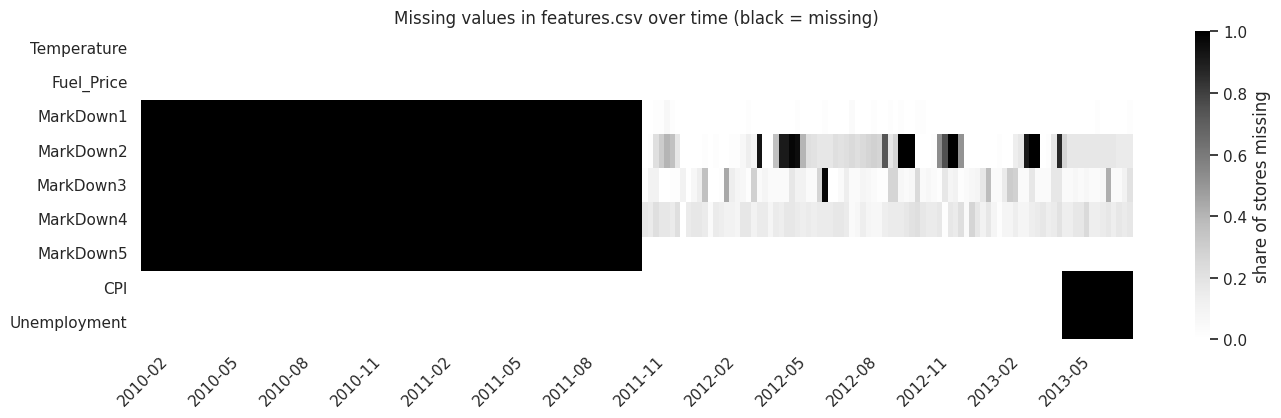

In [25]:
# share of stores with a missing value, for each week and each column
# rows = columns of features.csv, columns = weeks, colour = share missing (0 = complete, 1 = all missing)
missing_by_week = features[feature_cols].isna().groupby(features["Date"]).mean()

plt.figure(figsize=(16, 4))
ax = sns.heatmap(missing_by_week.T, cmap="Greys", cbar_kws={"label": "share of stores missing"})
# show one date label every 13 weeks (~ every quarter)
tick_pos = range(0, len(missing_by_week), 13)
ax.set_xticks([p + 0.5 for p in tick_pos])
ax.set_xticklabels([missing_by_week.index[p].strftime("%Y-%m") for p in tick_pos], rotation=45)
ax.set_xlabel("")
ax.set_title("Missing values in features.csv over time (black = missing)")
plt.show()

> **Code explained — `isna().groupby(features["Date"]).mean()`**
> `isna()` turns every cell into True / False (missing or not). Grouping by date and taking the **mean** of True/False gives the **share** of stores with a missing value that week (True counts as 1, False as 0).

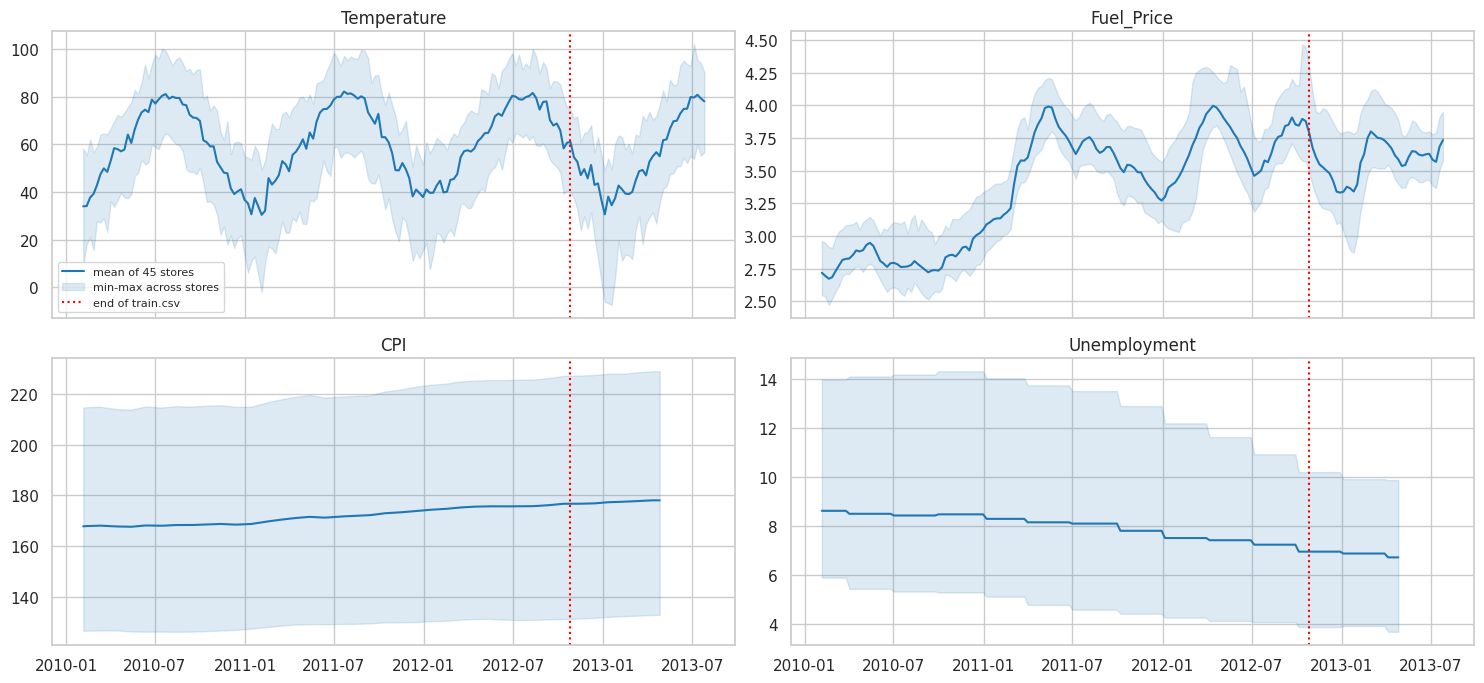

In [26]:
# the 4 continuous features over time: mean over the 45 stores + the min-max range across stores
end_of_train = train["Date"].max()
fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharex=True)

for ax, col in zip(axes.ravel(), ["Temperature", "Fuel_Price", "CPI", "Unemployment"]):
    by_week = features.groupby("Date")[col].agg(["mean", "min", "max"])     # 3 numbers per week
    ax.plot(by_week.index, by_week["mean"], color="tab:blue", label="mean of 45 stores")
    ax.fill_between(by_week.index, by_week["min"], by_week["max"], color="tab:blue", alpha=0.15, label="min-max across stores")
    ax.axvline(end_of_train, color="red", linestyle=":", label="end of train.csv")
    ax.set_title(col)
axes[0, 0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

In [27]:
# MarkDowns: number of negative values (a "markdown" is a price reduction, a negative one is strange)
markdown_cols = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]
print("negative MarkDown values:", (features[markdown_cols] < 0).sum().to_dict())

# IsHoliday: is it identical in train.csv and features.csv?
check = train.merge(features[["Store", "Date", "IsHoliday"]], on=["Store", "Date"], how="left", suffixes=("_train", "_features"))
print("IsHoliday identical in both files:", (check["IsHoliday_train"] == check["IsHoliday_features"]).all())

negative MarkDown values: {'MarkDown1': 4, 'MarkDown2': 25, 'MarkDown3': 13, 'MarkDown4': 0, 'MarkDown5': 2}
IsHoliday identical in both files: True


**What I see**

- **8,190 rows = 45 stores × 182 weeks** (2010-02-05 → 2013-07-26): the file covers the train period **and** the 39 weeks of `test.csv`.
- **Temperature and Fuel_Price are complete.** Temperature is strongly seasonal (≈ 80°F in summer, ≈ 35°F in winter, with big differences between regions); fuel price rises in 2011 and then oscillates.
- **MarkDown1–5 only start on 2011-11-11** (black block on the left of the heatmap) and are still partly missing after that (MarkDown2: 64% missing overall). 44 values are negative, which is strange for a "discount amount".
- **CPI and Unemployment are missing only in the last 13 weeks** (2013-05-03 → 2013-07-26), for every store (the black block on the right), i.e. inside the `test.csv` period. Both move very slowly (CPI slowly up, unemployment slowly down, in quarterly steps).
- `IsHoliday` is **identical** in `train.csv` and `features.csv`.

**Why it matters:** these columns are **not known 39 weeks in advance** (next table), and the most informative one, temperature, is mostly *the season itself*, which the calendar already describes. So the statistical models use the calendar instead (Part F).

### Which features could a forecasting model really use? (teammate's Note 5)

The test period is **39 weeks into the future**. A feature can only be used if we would **know its value 39 weeks in advance**. Otherwise the model looks better than it is, because it uses information from the future. This is called **data leakage**.

| Feature | Known 39 weeks ahead? | Usable? |
|---|---|---|
| `IsHoliday`, dates, week of year, Easter, … | yes, it's the calendar | ✅ |
| `Temperature`, `Fuel_Price`, `CPI`, `Unemployment` | no (the file gives them, but in real life you'd have to forecast them) | ❌ for honest forecasting |
| `MarkDown1–5` | no (promotions are not planned 39 weeks ahead), and missing before Nov 2011 | ❌ (only as past values, for ML) |
| `Type`, `Size` (stores.csv) | yes, but constant per store | no effect inside one series |

**Consequence for our statistical models:** ARIMA and SARIMA only use the past of the series itself. SARIMAX can add *exogenous* variables, but only **calendar variables** (holiday and season dummies), which are known in advance. That's exactly what Part F builds.

## A.4 `test.csv` — the weeks Kaggle wants us to forecast

**Question:** which series and which weeks have to be forecast, and do we know their history?

In [28]:
test = pd.read_csv(DATA_DIR + "test.csv")
test["Date"] = pd.to_datetime(test["Date"])
test.head()

,Store,Dept,Date,IsHoliday
0,1,1,2012-11-02,False
1,1,1,2012-11-09,False
2,1,1,2012-11-16,False
3,1,1,2012-11-23,True
4,1,1,2012-11-30,False


In [29]:
test.tail()

,Store,Dept,Date,IsHoliday
115059,45,98,2013-06-28,False
115060,45,98,2013-07-05,False
115061,45,98,2013-07-12,False
115062,45,98,2013-07-19,False
115063,45,98,2013-07-26,False


In [30]:
print("shape:", test.shape)
test.info()

shape: (115064, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115064 entries, 0 to 115063
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   Store      115064 non-null  int64         
 1   Dept       115064 non-null  int64         
 2   Date       115064 non-null  datetime64[ns]
 3   IsHoliday  115064 non-null  bool          
dtypes: bool(1), datetime64[ns](1), int64(2)
memory usage: 2.7 MB


In [31]:
print("first date:", test["Date"].min().date(), "| last date:", test["Date"].max().date(),
      "| weeks:", test["Date"].nunique())
print("holiday weeks in test.csv:", [d.date() for d in test[test["IsHoliday"]]["Date"].unique()])
print("columns:", list(test.columns), "-> no Weekly_Sales: this is what has to be predicted")

first date: 2012-11-02 | last date: 2013-07-26 | weeks: 39
holiday weeks in test.csv: [datetime.date(2012, 11, 23), datetime.date(2012, 12, 28), datetime.date(2013, 2, 8)]
columns: ['Store', 'Dept', 'Date', 'IsHoliday'] -> no Weekly_Sales: this is what has to be predicted


In [32]:
# which (Store, Dept) pairs are in train, in test, or in both? (teammate's cell)
train_pairs = set(map(tuple, train[["Store", "Dept"]].drop_duplicates().to_numpy()))
test_pairs  = set(map(tuple, test[["Store", "Dept"]].drop_duplicates().to_numpy()))

print("train pairs:", len(train_pairs))
print("test pairs :", len(test_pairs))
print("union      :", len(train_pairs | test_pairs))
print("test only  :", sorted(test_pairs - train_pairs))
print("train only :", len(train_pairs - test_pairs))

train pairs: 3331
test pairs : 3169
union      : 3342
test only  : [(np.int64(5), np.int64(99)), (np.int64(9), np.int64(99)), (np.int64(10), np.int64(99)), (np.int64(18), np.int64(43)), (np.int64(24), np.int64(43)), (np.int64(25), np.int64(99)), (np.int64(34), np.int64(39)), (np.int64(36), np.int64(30)), (np.int64(37), np.int64(29)), (np.int64(42), np.int64(30)), (np.int64(45), np.int64(39))]
train only : 173


> **Code explained — sets of pairs**
> `train[["Store", "Dept"]].drop_duplicates()` keeps each pair once. `map(tuple, ...)` turns each row into a tuple like `(1, 1)`, and `set(...)` stores them as a mathematical set. Then `-`, `|` mean "in A but not in B" and "in A or B". It's a quick way to compare two lists of keys.

**What I see**

- **115,064 rows, 39 weeks** (2012-11-02 → 2013-07-26), 3,169 series, **no `Weekly_Sales` column**: this is what Kaggle wants us to forecast.
- It contains 3 holiday weeks (weight 5): **Thanksgiving 2012-11-23, Christmas 2012-12-28, Super Bowl 2013-02-08**. So the real competition score depends a lot on the end-of-year season, which is **not** in our holdout (Part G.7).
- **11 pairs exist only in `test.csv`**, with no history at all (mostly small departments like 99, 39, 43, 30, 29). No time-series model can forecast them: they need a fallback (e.g. 0 or the department's average).
- **173 pairs exist only in `train.csv`**: departments that stopped. We don't need to forecast them.
- All **135 of our series (depts 1–3) are in `test.csv`** (5,265 rows = 135 × 39), so Part 4 of the modelling notebook can produce real competition forecasts for them.

## A.5 `sampleSubmission.csv` — the answer format

The teammate didn't need it, but it shows **how a final forecast is handed in**.

In [33]:
sample_submission = pd.read_csv(DATA_DIR + "sampleSubmission.csv")
sample_submission.head()

,Id,Weekly_Sales
0,1_1_2012-11-02,0
1,1_1_2012-11-09,0
2,1_1_2012-11-16,0
3,1_1_2012-11-23,0
4,1_1_2012-11-30,0


In [34]:
sample_submission.tail()

,Id,Weekly_Sales
115059,45_98_2013-06-28,0
115060,45_98_2013-07-05,0
115061,45_98_2013-07-12,0
115062,45_98_2013-07-19,0
115063,45_98_2013-07-26,0


In [35]:
print("shape:", sample_submission.shape, "| same number of rows as test.csv:", len(sample_submission) == len(test))

# the Id is simply "Store_Dept_Date" -> rebuild it from test.csv and compare
rebuilt_id = test["Store"].astype(str) + "_" + test["Dept"].astype(str) + "_" + test["Date"].dt.strftime("%Y-%m-%d")
print("Id = Store_Dept_Date, in the same order as test.csv:", (rebuilt_id.values == sample_submission["Id"].values).all())

shape: (115064, 2) | same number of rows as test.csv: True


Id = Store_Dept_Date, in the same order as test.csv: True


**What I see:** one row per (store, department, week) of `test.csv`, with an `Id` built as `Store_Dept_Date` and a `Weekly_Sales` column to fill (all 0 in the template). Kaggle scores the filled file with WMAE. Our holdout evaluation (Part G.7) imitates exactly that, on weeks where we know the answer.

## A.6 How the files fit together

```
stores.csv  (Store)  ──┐
                       ├── Store ──── train.csv / test.csv (Store, Dept, Date)
features.csv (Store, Date) ── Store + Date ──┘
sampleSubmission.csv (Id = Store_Dept_Date) ── one row per test.csv row
```

| Join | Key | Check |
|---|---|---|
| `train` ↔ `stores` | `Store` | every store of train is in stores.csv |
| `train` ↔ `features` | `Store` + `Date` | every (store, week) of train is in features.csv |
| `test` ↔ `features` | `Store` + `Date` | features.csv also covers the 39 test weeks |

In [36]:
print("all train stores in stores.csv         :", set(train["Store"]) <= set(stores["Store"]))
train_store_weeks = set(map(tuple, train[["Store", "Date"]].drop_duplicates().to_numpy()))
feature_store_weeks = set(map(tuple, features[["Store", "Date"]].to_numpy()))
test_store_weeks = set(map(tuple, test[["Store", "Date"]].drop_duplicates().to_numpy()))
print("all train (Store, Date) in features.csv:", train_store_weeks <= feature_store_weeks)
print("all test  (Store, Date) in features.csv:", test_store_weeks <= feature_store_weeks)

all train stores in stores.csv         : True


all train (Store, Date) in features.csv: True
all test  (Store, Date) in features.csv: True


In [37]:
# one merged table for Part B: every train row + the type and size of its store
train_full = train.merge(stores, on="Store", how="left")
print(train_full.shape)
train_full.head(3)

(421570, 7)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size
0,1,1,2010-02-05,24924.50,False,A,151315
1,1,1,2010-02-12,46039.49,True,A,151315
2,1,1,2010-02-19,41595.55,False,A,151315


# Part B — The whole dataset as time series

Before zooming into departments 1–3, I look at Walmart as a whole: total sales, stores, departments, holidays. This gives the context for the report and shows which patterns are general and which are specific to our departments.

## B.1 Total weekly sales of all stores and departments

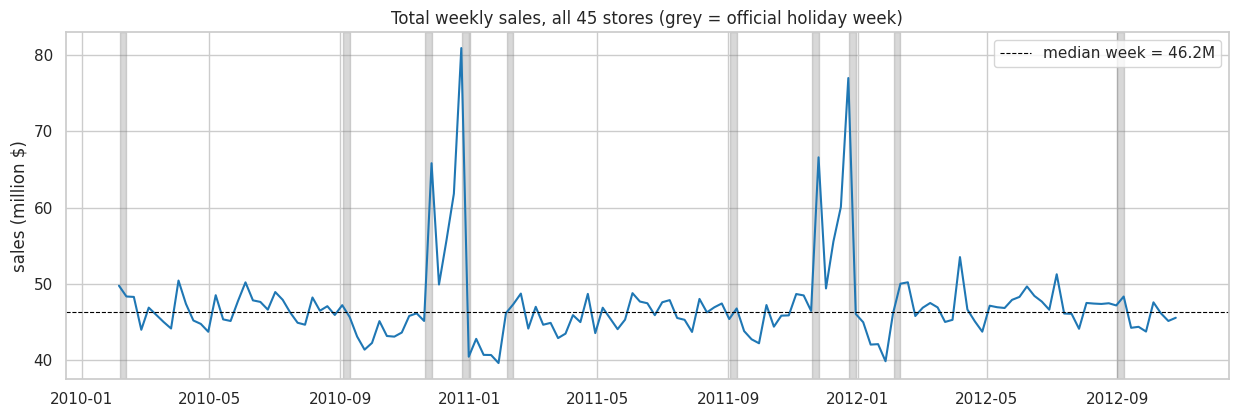

In [38]:
# add up all 421,570 rows week by week -> one number per week, in millions of $
total_weekly = train.groupby("Date")["Weekly_Sales"].sum() / 1e6
holiday_dates = train.loc[train["IsHoliday"], "Date"].unique()

plt.figure(figsize=(15, 4.5))
plt.plot(total_weekly.index, total_weekly.values, color="tab:blue", linewidth=1.5)
for d in holiday_dates:                                   # grey band = official holiday week
    plt.axvspan(d - pd.Timedelta(days=6), d, color="grey", alpha=0.3)
plt.axhline(total_weekly.median(), color="black", linestyle="--", linewidth=0.8, label=f"median week = {total_weekly.median():.1f}M")
plt.title("Total weekly sales, all 45 stores (grey = official holiday week)")
plt.ylabel("sales (million $)")
plt.legend()
plt.show()

In [39]:
# the 10 biggest weeks, with their holiday flag
top_weeks = total_weekly.sort_values(ascending=False).head(10).round(1).to_frame("sales ($M)")
top_weeks["ratio to median week"] = (top_weeks["sales ($M)"] / total_weekly.median()).round(2)
top_weeks["IsHoliday"] = top_weeks.index.isin(holiday_dates)
top_weeks["week (Sat - Fri)"] = [f"{(d - pd.Timedelta(days=6)).strftime('%d %b')} - {d.strftime('%d %b %Y')}" for d in top_weeks.index]
top_weeks

,sales ($M),ratio to median week,IsHoliday,week (Sat - Fri)
Date,,,,
2010-12-24,80.9,1.75,False,18 Dec - 24 Dec 2010
2011-12-23,77.0,1.67,False,17 Dec - 23 Dec 2011
2011-11-25,66.6,1.44,True,19 Nov - 25 Nov 2011
2010-11-26,65.8,1.42,True,20 Nov - 26 Nov 2010
2010-12-17,61.8,1.34,False,11 Dec - 17 Dec 2010
2011-12-16,60.1,1.30,False,10 Dec - 16 Dec 2011
2010-12-10,55.7,1.20,False,04 Dec - 10 Dec 2010
2011-12-09,55.6,1.20,False,03 Dec - 09 Dec 2011
2012-04-06,53.5,1.16,False,31 Mar - 06 Apr 2012


**What I see**

- Total sales are **flat** around a median of 46.2M per week, with **two huge spikes every year**:
  - the **week before Christmas**: 80.9M (2010) and 77.0M (2011), **1.75×** a normal week,
  - **Thanksgiving week** (Black Friday is inside it): 65.8M and 66.6M, **1.43×**.
- The top-10 weeks are all late November / December, except **2012-04-06 (the Easter 2012 week)** and **2012-07-06 (Independence Day)**.
- Of the 4 official holidays, only Thanksgiving is a big week. Super Bowl and Labor Day are normal weeks (×1.0–1.1), and the flagged Christmas week is **below** normal (×0.87 in 2010).

**Why it matters:** the metric's weight of 5 on holiday weeks reflects **business importance**, not size. And the real peak (the week before Christmas) **isn't flagged at all**. We'll come back to this in Part F.

## B.2 Does the year repeat itself? Year-over-year overlay

I place the three years on top of each other, using the **ISO week number** (1–52) as the x axis. If the lines overlap, the year repeats itself.

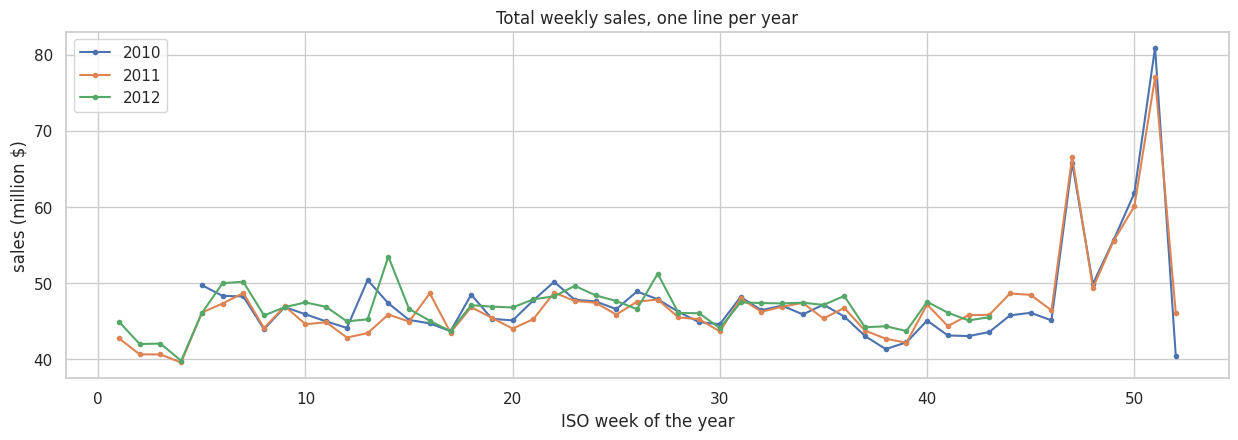

average weekly sales, ISO weeks 6-43 only ($M): {2010: 45.99, 2011: 45.79, 2012: 46.98}


In [40]:
total_df = total_weekly.to_frame("sales")
total_df["year"] = total_df.index.year
total_df["week_of_year"] = total_df.index.isocalendar().week.astype(int)     # ISO week number 1-52

plt.figure(figsize=(15, 4.5))
for year, part in total_df.groupby("year"):
    plt.plot(part["week_of_year"], part["sales"], marker="o", markersize=3, label=str(year))
plt.xlabel("ISO week of the year")
plt.ylabel("sales (million $)")
plt.title("Total weekly sales, one line per year")
plt.legend()
plt.show()

# yearly average, same weeks only (Feb-Oct, present in all 3 years) -> fair comparison
same_weeks = total_df[(total_df["week_of_year"] >= 6) & (total_df["week_of_year"] <= 43)]
print("average weekly sales, ISO weeks 6-43 only ($M):", same_weeks.groupby("year")["sales"].mean().round(2).to_dict())

**What I see**

- The three years lie **on top of each other** for most of the year: strong **yearly seasonality**, with almost no trend (same weeks Feb–Oct: 46.0M, 45.8M, 47.0M on average).
- **Easter moves even in the total of all departments:** the April bump is at ISO week 13 in 2010, 16 in 2011 and 14 in 2012.
- Week 27 of 2012 (July 4th) is visible as well.

**Why it matters:** "same week last year" is a good first guess for Walmart overall, **except for holidays that move**. That's the whole story of the seasonal models in a nutshell.

## B.3 Stores: size, type and sales

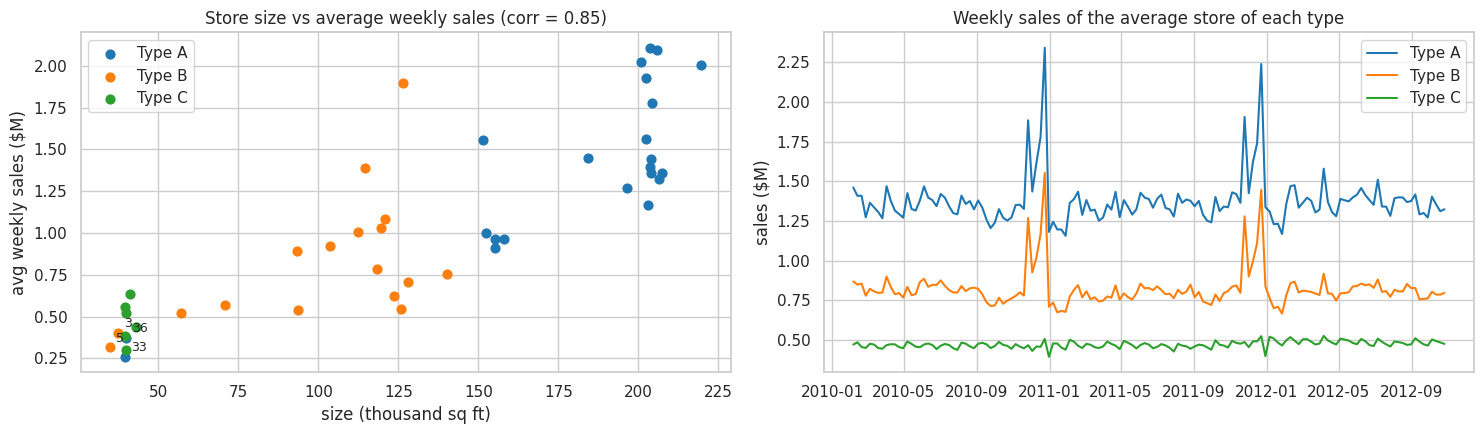

In [41]:
# average weekly sales of each store (total of the store / number of weeks)
store_avg = (train.groupby("Store")["Weekly_Sales"].sum() / train["Date"].nunique() / 1e6).rename("avg weekly sales ($M)")
store_info = stores.set_index("Store").join(store_avg)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for t, c in type_colors.items():
    part = store_info[store_info["Type"] == t]
    axes[0].scatter(part["Size"] / 1000, part["avg weekly sales ($M)"], color=c, label=f"Type {t}", s=40)
for s in [3, 5, 33, 36]:                                           # label a few interesting stores
    axes[0].annotate(str(s), (store_info.loc[s, "Size"] / 1000, store_info.loc[s, "avg weekly sales ($M)"]),
                     xytext=(4, 4), textcoords="offset points", fontsize=9)
corr = store_info["Size"].corr(store_info["avg weekly sales ($M)"])
axes[0].set_title(f"Store size vs average weekly sales (corr = {corr:.2f})")
axes[0].set_xlabel("size (thousand sq ft)")
axes[0].set_ylabel("avg weekly sales ($M)")
axes[0].legend()

# average store of each type, over time
weekly_by_type = train_full.groupby(["Date", "Type"])["Weekly_Sales"].sum().unstack() / 1e6      # rows = weeks, columns = A/B/C
weekly_by_type = weekly_by_type / stores["Type"].value_counts()                                   # divide by number of stores -> "average store"
for t, c in type_colors.items():
    axes[1].plot(weekly_by_type.index, weekly_by_type[t], color=c, label=f"Type {t}")
axes[1].set_title("Weekly sales of the average store of each type")
axes[1].set_ylabel("sales ($M)")
axes[1].legend()
plt.tight_layout()
plt.show()

> **Code explained — `groupby([...]).sum().unstack()`**
> Grouping by two columns gives one number per (week, type). `.unstack()` moves the second key (`Type`) into columns: one row per week, one column per type. That's the "wide" shape a line plot needs.

**What I see**

- **Bigger stores sell more** (correlation 0.85 between size and average weekly sales). Stores 33 and 36 (type A, small) behave like the small stores they are.
- The average **type A** store sells ≈ 1.35M per week, **type B** ≈ 0.8M, **type C** ≈ 0.47M.
- The holiday spikes are strong in A and B stores but **almost absent in type C stores**, whose line stays flat (even dipping at Christmas). Small stores don't seem to get the holiday rush.

**Why it matters:** different stores have different scales and partly different shapes. That's why comparisons below use **scaled** sales (teammate's mean scaling) or **relative** errors.

## B.4 Departments: how concentrated are sales, and which stores have which department?

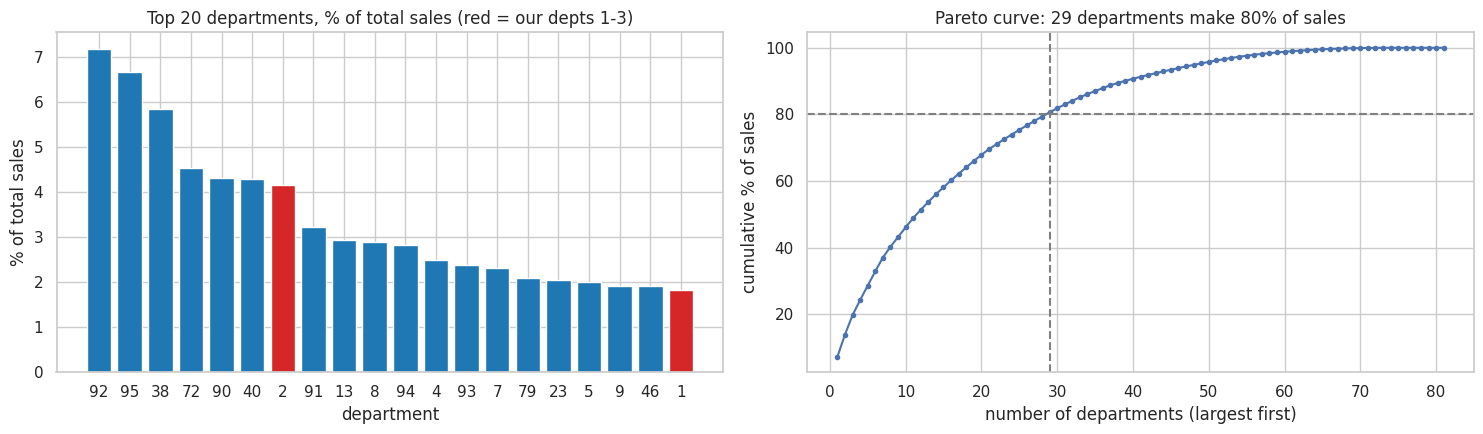

share of depts 1-3: {1: 1.84, 2: 4.17, 3: 1.13} -> total 7.1 %
rank of depts 1-3 (1 = biggest): {1: 20, 2: 7, 3: 31}


In [42]:
dept_total = train.groupby("Dept")["Weekly_Sales"].sum().sort_values(ascending=False)
dept_share = dept_total / dept_total.sum() * 100                   # % of all sales
cumulative_share = dept_share.cumsum()                             # running total -> Pareto curve

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
top20 = dept_share.head(20)
axes[0].bar([str(d) for d in top20.index], top20.values,
            color=["tab:red" if d in DEPTS else "tab:blue" for d in top20.index])
axes[0].set_title("Top 20 departments, % of total sales (red = our depts 1-3)")
axes[0].set_xlabel("department")
axes[0].set_ylabel("% of total sales")

axes[1].plot(range(1, len(cumulative_share) + 1), cumulative_share.values, marker="o", markersize=3)
axes[1].axhline(80, color="grey", linestyle="--")
n80 = (cumulative_share < 80).sum() + 1
axes[1].axvline(n80, color="grey", linestyle="--")
axes[1].set_title(f"Pareto curve: {n80} departments make 80% of sales")
axes[1].set_xlabel("number of departments (largest first)")
axes[1].set_ylabel("cumulative % of sales")
plt.tight_layout()
plt.show()

print("share of depts 1-3:", dept_share.loc[DEPTS].round(2).to_dict(), "-> total", round(dept_share.loc[DEPTS].sum(), 1), "%")
print("rank of depts 1-3 (1 = biggest):", {d: int(np.where(dept_share.index == d)[0][0]) + 1 for d in DEPTS})

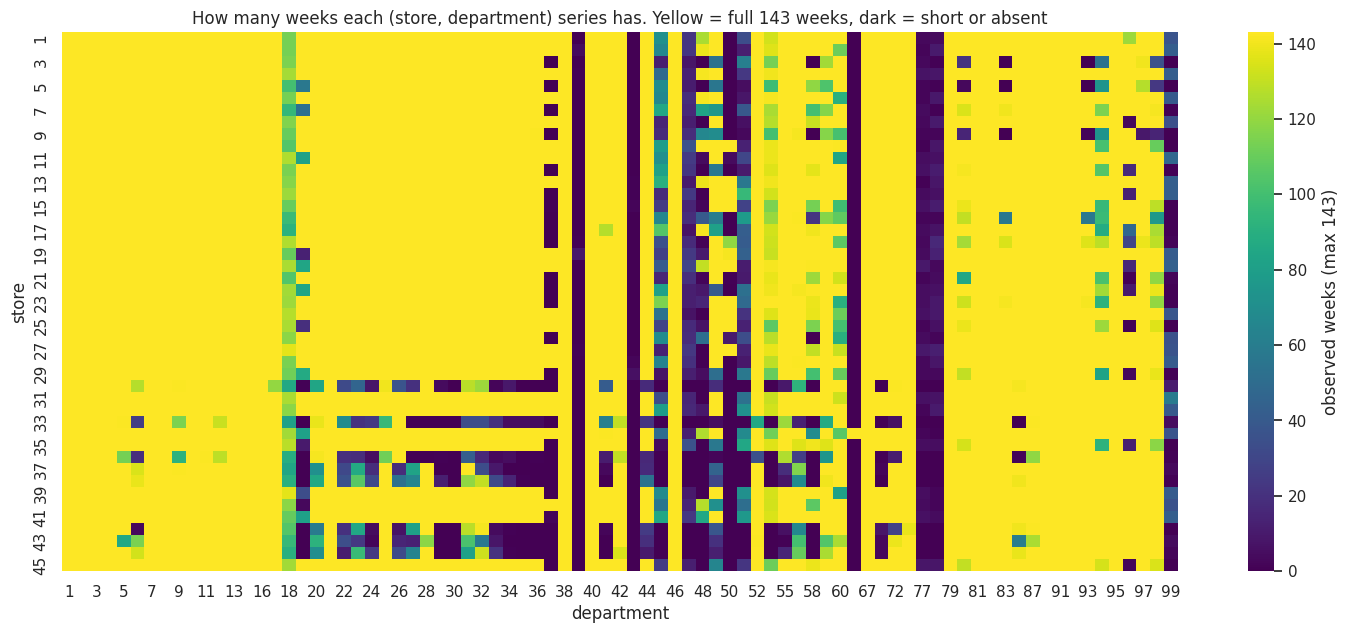

complete series (143 weeks): 2660 of 3331 existing series


In [43]:
# presence map: for each store (row) and department (column), how many weeks are observed (0 to 143)
weeks_observed = train.groupby(["Store", "Dept"]).size().unstack(fill_value=0)    # missing pair -> 0 weeks

plt.figure(figsize=(18, 7))
sns.heatmap(weeks_observed, cmap="viridis", cbar_kws={"label": "observed weeks (max 143)"})
plt.title("How many weeks each (store, department) series has. Yellow = full 143 weeks, dark = short or absent")
plt.xlabel("department")
plt.ylabel("store")
plt.show()

print("complete series (143 weeks):", int((weeks_observed == 143).sum().sum()), "of", int((weeks_observed > 0).sum().sum()), "existing series")

**What I see**

- **Sales are concentrated:** the top department (92) alone makes 7.2% of sales, and **29 of the 81 departments make 80%** of sales.
- Our departments: **Dept 2 is the 7th biggest (4.2%)**, Dept 1 the 20th (1.8%), Dept 3 the 31st (1.1%). Together **7.1%** of sales.
- **Presence map:** yellow = complete series. Some departments are nearly empty columns (39, 43, 65, 77, 78…), and the smaller stores (bottom rows, around stores 30–44) miss many departments. **2,660 of the 3,331 series are complete**.
- **Departments 1, 2 and 3 are fully yellow**: every store has them, every week.

## B.5 Holiday weeks vs normal weeks

The metric gives holiday weeks a weight of 5, so it's worth knowing how special they are. For each official holiday week I compare total sales with the **median week** of the whole file.

In [44]:
holiday_table = total_weekly[total_weekly.index.isin(holiday_dates)].round(1).to_frame("sales ($M)")
month_to_name = {2: "Super Bowl", 9: "Labor Day", 11: "Thanksgiving", 12: "Christmas"}
holiday_table["holiday"] = holiday_table.index.month.map(month_to_name)
holiday_table["ratio to median week"] = (holiday_table["sales ($M)"] / total_weekly.median()).round(2)
holiday_table

,sales ($M),holiday,ratio to median week
Date,,,
2010-02-12,48.3,Super Bowl,1.04
2010-09-10,45.6,Labor Day,0.99
2010-11-26,65.8,Thanksgiving,1.42
2010-12-31,40.4,Christmas,0.87
2011-02-11,47.3,Super Bowl,1.02
2011-09-09,46.8,Labor Day,1.01
2011-11-25,66.6,Thanksgiving,1.44
2011-12-30,46.0,Christmas,0.99
2012-02-10,50.0,Super Bowl,1.08


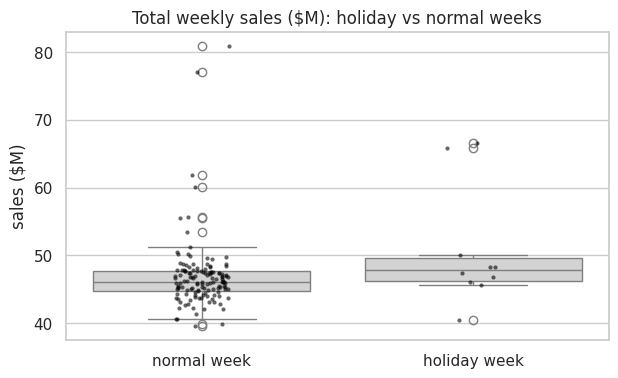

In [45]:
# total weekly sales: holiday weeks vs other weeks
compare = total_weekly.to_frame("sales")
compare["week type"] = np.where(compare.index.isin(holiday_dates), "holiday week", "normal week")

plt.figure(figsize=(7, 4))
sns.boxplot(data=compare, x="week type", y="sales", color="lightgrey")
sns.stripplot(data=compare, x="week type", y="sales", color="black", size=3, alpha=0.6)
plt.title("Total weekly sales ($M): holiday vs normal weeks")
plt.ylabel("sales ($M)")
plt.xlabel("")
plt.show()

**What I see**

| Holiday | Ratio to a median week (2010 / 2011 / 2012) |
|---|---|
| Thanksgiving | 1.42 / 1.44 / — |
| Super Bowl | 1.04 / 1.02 / 1.08 |
| Labor Day | 0.99 / 1.01 / 1.04 |
| Christmas (flagged week) | 0.87 / 0.99 / — |

The boxplot confirms it: holiday weeks are only slightly above normal weeks on average, and the **biggest weeks of the year are "normal" weeks** (the outliers on the left: the weeks before Christmas).

**Why it matters:** `IsHoliday` as given is a weak description of the special weeks. It's the right **weight** for the metric (we keep it for WMAE), but to **model** the holidays we need better calendar variables (Part F).

## B.6 Negative sales: where do they come from?

negative rows: 1285 (0.30% of rows)
total value of negative rows: $ -88162 | most negative value: $ -4989


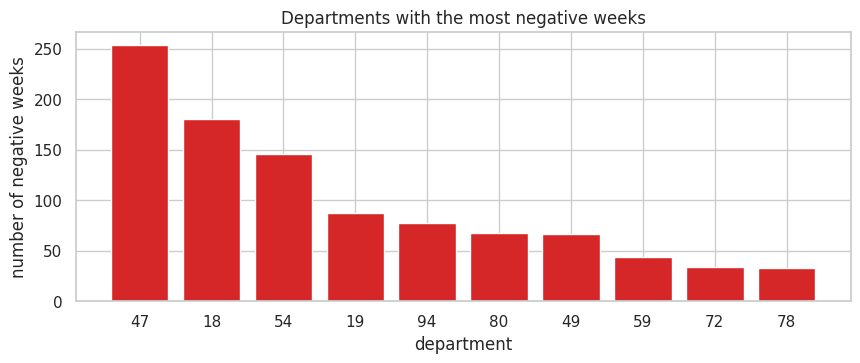

negative rows in depts 1-3: 0


In [46]:
negatives = train[train["Weekly_Sales"] < 0]
print("negative rows:", len(negatives), f"({len(negatives) / len(train):.2%} of rows)")
print("total value of negative rows: $", round(negatives["Weekly_Sales"].sum()), "| most negative value: $", round(negatives["Weekly_Sales"].min()))

neg_by_dept = negatives.groupby("Dept").size().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 3.5))
plt.bar([str(d) for d in neg_by_dept.index], neg_by_dept.values, color="tab:red")
plt.title("Departments with the most negative weeks")
plt.xlabel("department")
plt.ylabel("number of negative weeks")
plt.show()

print("negative rows in depts 1-3:", int(negatives["Dept"].isin(DEPTS).sum()))

**What I see:** 1,285 negative weeks worth −88k in total, which is tiny compared with the 6.74bn of total sales. They're concentrated in a few departments (47, 18, 54, 19…), probably departments with many returns or very small sales. **None of them are in departments 1–3.**

**Why it matters:** for the whole dataset, the teammate's clipping (C.3) is a simple and safe choice. For our 135 series it changes nothing.

## B.7 Do the external features move with sales?

Only for context (they can't be used honestly, see A.3). To avoid comparing big stores with small stores, I first **scale** each store's weekly sales by its own average (1.0 = a normal week for that store), then compute the correlation with each feature.

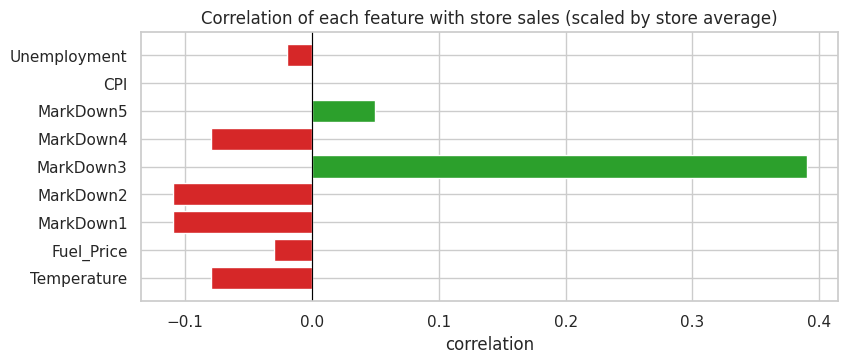

In [47]:
# total sales per store and week, scaled by the store's own average
store_week = train.groupby(["Store", "Date"])["Weekly_Sales"].sum().reset_index()
store_week["sales_scaled"] = store_week["Weekly_Sales"] / store_week.groupby("Store")["Weekly_Sales"].transform("mean")
store_week = store_week.merge(features, on=["Store", "Date"], how="left")

corr_with_sales = store_week[["sales_scaled"] + feature_cols].corr()["sales_scaled"].drop("sales_scaled").round(2)

plt.figure(figsize=(9, 3.5))
plt.barh(corr_with_sales.index, corr_with_sales.values, color=["tab:green" if v > 0 else "tab:red" for v in corr_with_sales])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation of each feature with store sales (scaled by store average)")
plt.xlabel("correlation")
plt.show()

> **Code explained — `groupby(...).transform("mean")`**
> `groupby("Store")["Weekly_Sales"].mean()` would give **one number per store** (45 numbers). `.transform("mean")` gives the same store average but **repeated on every row** of that store, so it has the same length as the table and I can divide row by row.

**What I see**

- Temperature (−0.08), Fuel_Price (−0.03), CPI (≈ 0) and Unemployment (−0.02) are **barely related** to weekly sales.
- **MarkDown3** stands out (+0.39), but markdowns only exist from Nov 2011 and the large MarkDown3 values sit in the **Thanksgiving / Christmas weeks**. Both are high **because of the season**: it's a coincidence of timing, not proof that markdowns cause sales.

**Why it matters:** even setting aside data leakage, these features add little beyond the calendar. This supports building the statistical models on **the series' own past + calendar variables** only.

## B.8 The teammate's example series (Dept 1, 5 and 10, first 10 stores)

I keep the teammate's plots, written as one small function so the same code draws any department. One fix: his loop reused the name `stores` for the list of store numbers, which **overwrote the `stores` DataFrame**. Here the list is called `first_stores`.

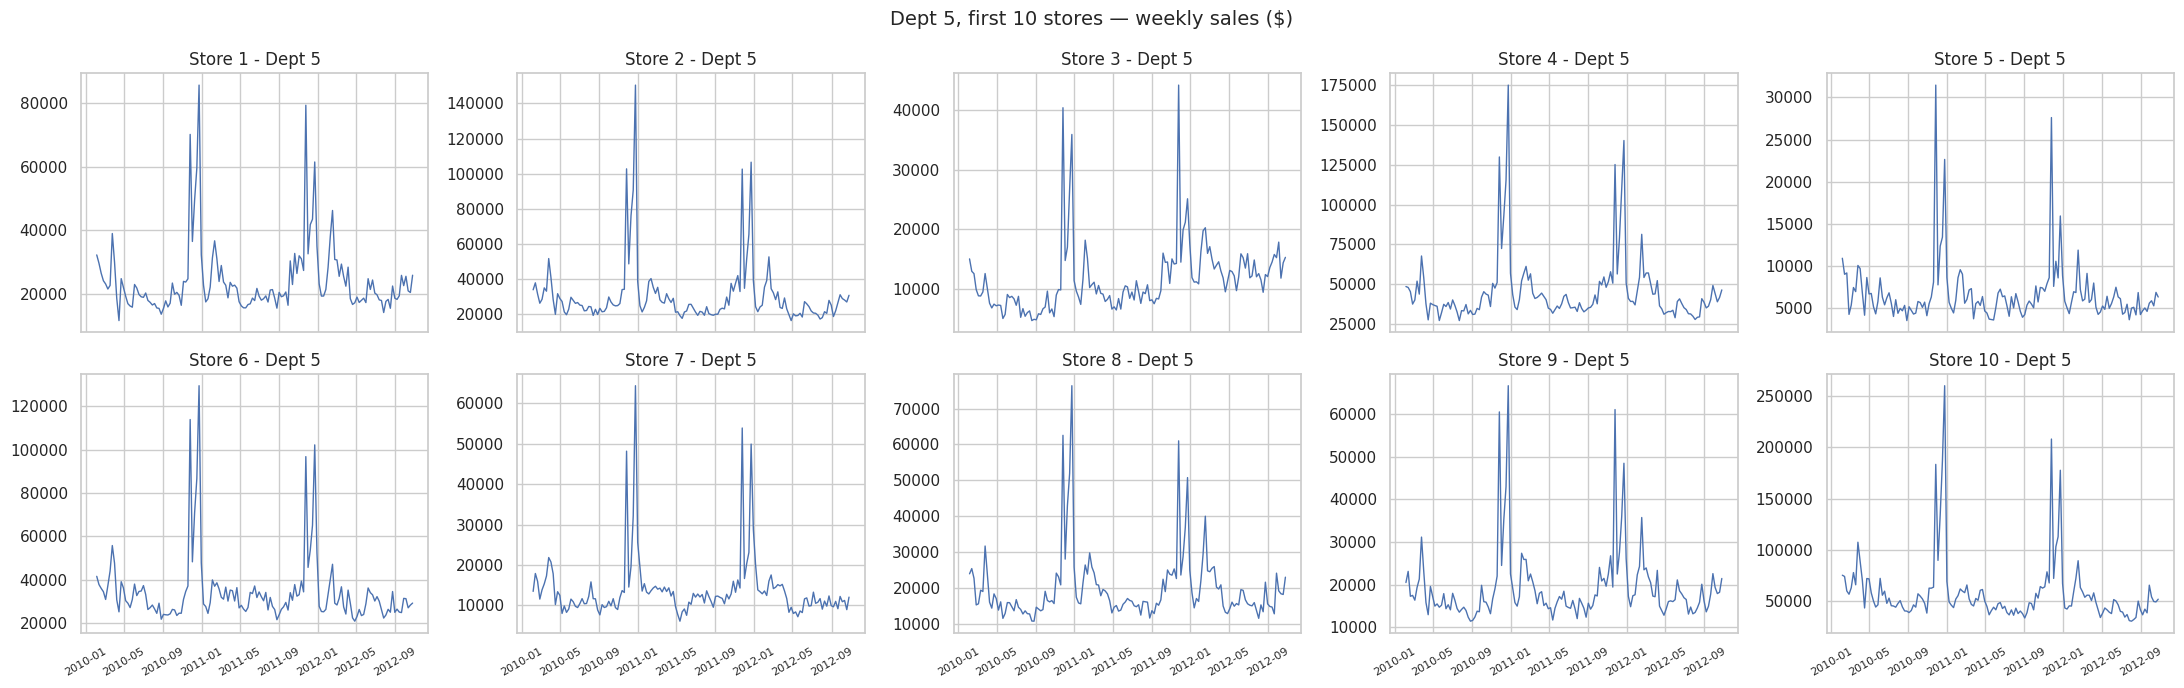

In [48]:
def plot_first_stores(dept, n=10, scaled=False):
    # one small plot per store, for the first n stores that have this department (teammate's code, as a function)
    d = train[train["Dept"] == dept]
    first_stores = sorted(d["Store"].unique())[:n]            # NOT called "stores", to keep the stores DataFrame intact

    fig, axes = plt.subplots(2, 5, figsize=(22, 7), sharex=True, sharey=scaled)
    for ax, store in zip(axes.ravel(), first_stores):
        s = d[d["Store"] == store].sort_values("Date")
        y = s["Weekly_Sales"]
        if scaled:
            # teammate's mean scaling: divide by the mean of the last 52 weeks before the split
            hist = s[s["Date"] <= pd.Timestamp("2012-01-27")]
            y = y / hist["Weekly_Sales"].tail(52).mean()
            ax.axhline(1, color="gray", linestyle="--", linewidth=0.8)
            ax.axvline(pd.Timestamp("2012-01-27"), color="red", linestyle=":", linewidth=0.8)
        ax.plot(s["Date"], y, linewidth=1)
        ax.set_title(f"Store {store} - Dept {dept}")
        ax.tick_params(axis="x", labelsize=8, rotation=30)
    title = f"Dept {dept}, first {n} stores" + (" — mean-scaled (1.0 = last-52-week average)" if scaled else " — weekly sales ($)")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

plot_first_stores(5)

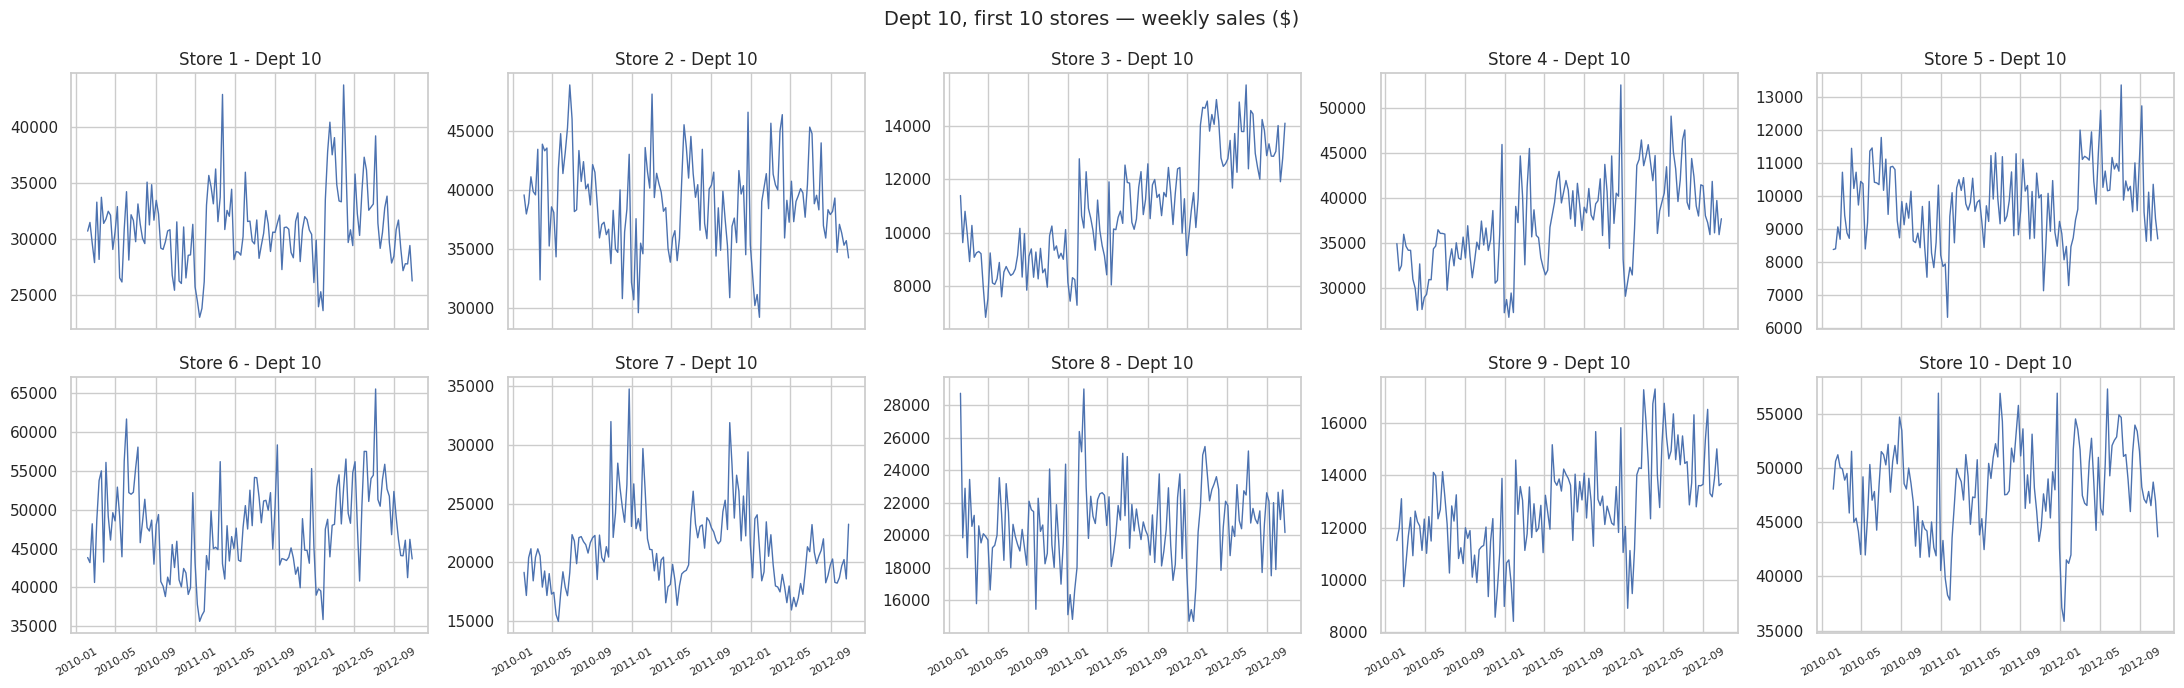

In [49]:
plot_first_stores(10)

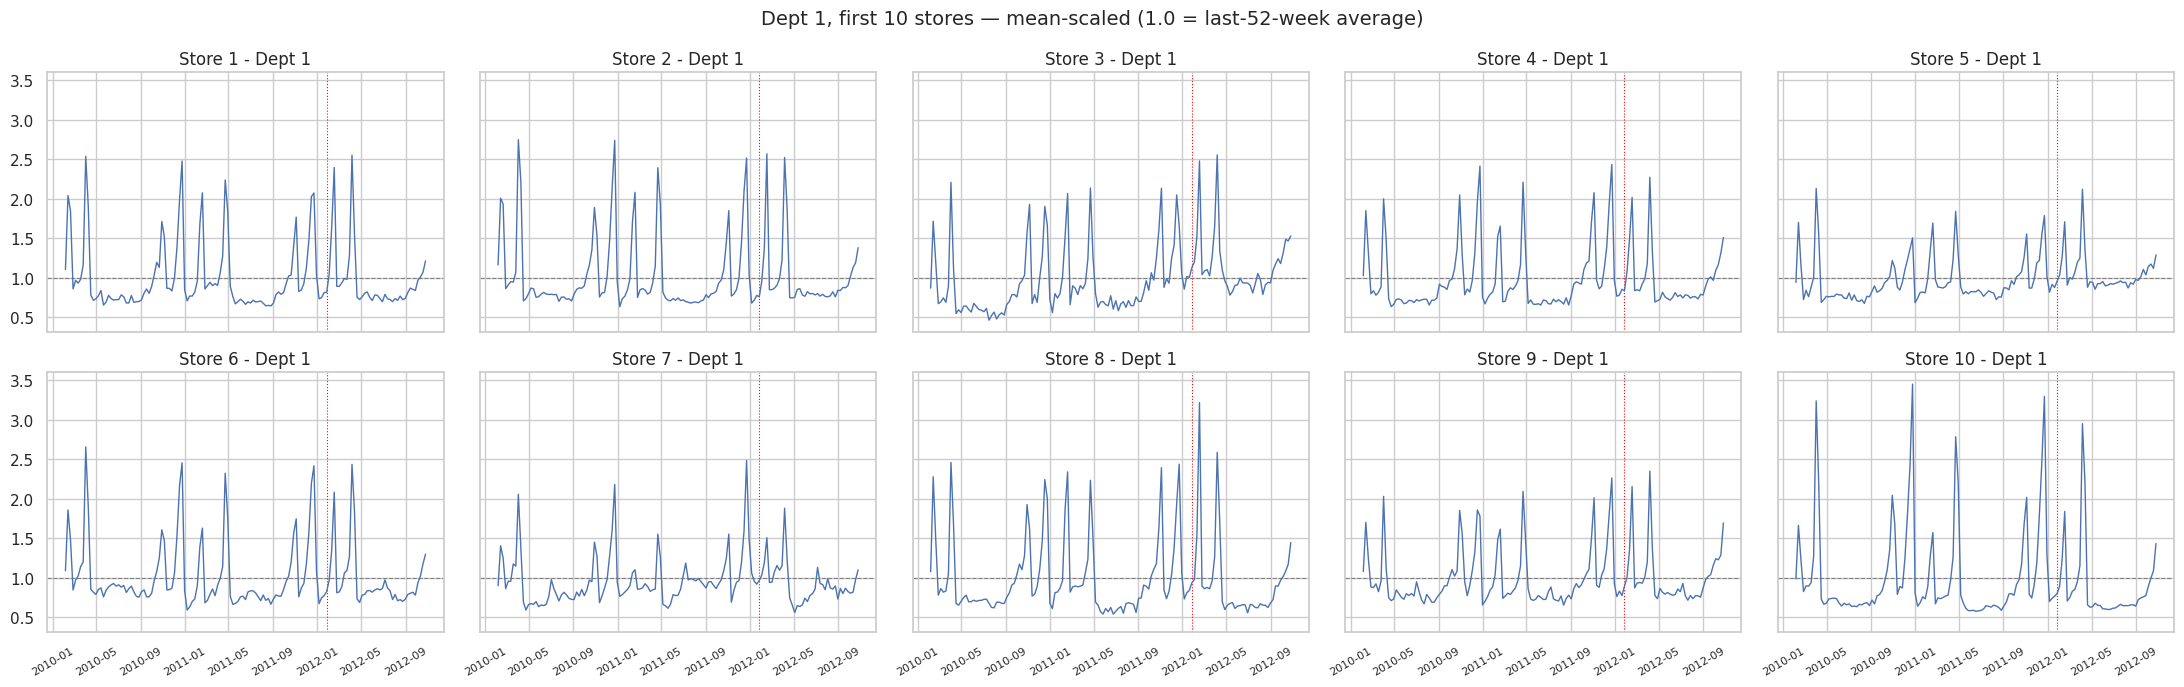

In [50]:
plot_first_stores(1, scaled=True)

**What I see**

- **Dept 5:** two big spikes per year, **Thanksgiving (Black Friday)** and **Christmas** (up to 5× a normal week), flat otherwise. A typical "holiday" department.
- **Dept 10:** no clear yearly pattern, lots of noise, and level shifts in some stores. Not every department is seasonal.
- **Dept 1, mean-scaled:** the 10 stores have **almost the same shape** once scaled.

**Why it matters:** this is the teammate's argument for Note 6 (different departments need different models → forecast combination) and Note 7 (similar shapes across stores → pooling, useful for the ML models). For the statistical models it means Store 1 is a good **example** of what the other stores look like (checked in Part E).

# Part C — Data processing (teammate's pipeline, explained)

The raw `train.csv` only contains the weeks that exist. A time-series model needs a **regular time axis**: one row per week, even if the value is missing. The teammate's pipeline builds that in 5 steps:

| Step | What | Why |
|---|---|---|
| C.1 | complete weekly panel | every series × every week, missing weeks become visible (`NaN`) |
| C.2 | holiday flag | one 0/1 column per week, used by the metric |
| C.3 | clip negatives | negative sales → 0, original kept |
| C.4 | gap types | describe *why* a week is missing |
| C.5 | short series | flag series with less than one year of history |

The code below is the teammate's, with more comments.

## C.1 Complete weekly panel

In [51]:
# 1. Full weekly calendar (Fridays), train period only: 2010-02-05 -> 2012-10-26
dates = pd.date_range(train["Date"].min(), train["Date"].max(), freq="W-FRI")   # every Friday between the two dates
calendar = pd.DataFrame({"Date": dates})
print("calendar:", calendar.shape, "->", len(dates), "weeks")

# 2. Every store-department pair that appears in train
pairs = (
    train[["Store", "Dept"]]
    .drop_duplicates()
    .sort_values(["Store", "Dept"])
    .reset_index(drop=True)
)
print("pairs   :", pairs.shape, "->", len(pairs), "series")

# 3. Cross them: every pair x every week
panel = pairs.merge(calendar, how="cross")
print("panel after cross join:", panel.shape, "=", len(pairs), "x", len(dates))

# 4. Attach observed sales; weeks with no row in train stay NaN
panel = panel.merge(
    train[["Store", "Dept", "Date", "Weekly_Sales"]],
    on=["Store", "Dept", "Date"],
    how="left",
)

# 5. Mark the split (train 104 weeks, test last 39 weeks)
split_date = pd.Timestamp("2012-01-27")
panel["split"] = (panel["Date"] > split_date).map({False: "train", True: "test"})

panel = panel.sort_values(["Store", "Dept", "Date"]).reset_index(drop=True)
panel.head()

calendar: (143, 1) -> 143 weeks
pairs   : (3331, 2) -> 3331 series
panel after cross join: (476333, 3) = 3331 x 143


,Store,Dept,Date,Weekly_Sales,split
0,1,1,2010-02-05,24924.50,train
1,1,1,2010-02-12,46039.49,train
2,1,1,2010-02-19,41595.55,train
3,1,1,2010-02-26,19403.54,train
4,1,1,2010-03-05,21827.90,train


> **Code explained**
> - `pd.date_range(start, end, freq="W-FRI")`: generates every **Friday** between two dates, the same "week ending" convention as the data.
> - `merge(how="cross")`: a **Cartesian product**. Every row of `pairs` is combined with every row of `calendar` (3,331 × 143 = 476,333 rows). Think of an **attendance sheet**: the full class list × every lesson, before knowing who came.
> - `merge(how="left")`: keep **all** rows of the panel and copy the sales when a matching row exists in `train`. When there's no match, the cell stays `NaN` (= the student was absent).
> - `(panel["Date"] > split_date).map({False: "train", True: "test"})`: True/False → readable labels.

In [52]:
print("weeks per split:", panel.drop_duplicates("Date")["split"].value_counts().to_dict())
print("missing sales in the panel:", int(panel["Weekly_Sales"].isna().sum()))

weeks per split: {'train': 104, 'test': 39}
missing sales in the panel: 54763


## C.2 Holiday flag (one value per date)

In [53]:
holiday = (
    features[["Date", "IsHoliday"]]
    .drop_duplicates()
    .rename(columns={"IsHoliday": "is_holiday"})
)
holiday["is_holiday"] = holiday["is_holiday"].astype(int)       # True/False -> 1/0

# one row per date, otherwise the merge would duplicate panel rows
assert holiday["Date"].is_unique, "IsHoliday differs between stores for some dates"

panel = panel.merge(holiday, on="Date", how="left")
print(panel.shape)
panel.head(3)

(476333, 6)


,Store,Dept,Date,Weekly_Sales,split,is_holiday
0,1,1,2010-02-05,24924.50,train,0
1,1,1,2010-02-12,46039.49,train,1
2,1,1,2010-02-19,41595.55,train,0


> **Code explained — the `assert`**
> `features.csv` has 45 rows per date (one per store). After `drop_duplicates()` there should be **one** row per date, because the holiday flag is the same for every store. If two stores disagreed, a date would appear twice and the next `merge` would **duplicate** panel rows silently. `assert` stops the notebook with an error in that case: a cheap safety check.

## C.3 Clipping negative sales

In [54]:
# keep the original column for evaluation, clip into a new column
panel["was_negative"] = (panel["Weekly_Sales"] < 0).astype(int)
panel["sales_clean"] = panel["Weekly_Sales"].clip(lower=0)   # NaN stays NaN

# report
n_neg = panel["was_negative"].sum()
print(f"{n_neg} negative rows clipped ({n_neg / panel['Weekly_Sales'].notna().sum():.2%} of observed values)")
assert (panel["sales_clean"].dropna() >= 0).all()

1285 negative rows clipped (0.30% of observed values)


## C.4 Missing data: three kinds of gaps

In [55]:
print("Number of missing Values in the train split:", panel[panel["split"]=="train"]["Weekly_Sales"].isna().sum())

Number of missing Values in the train split: 40442


| Gap type | Meaning | Typical reason |
|---|---|---|
| **Leading gap** | weeks before the series starts | the department opened later |
| **Interior gap** | a missing week between two observed weeks | probably no sales that week, so no row was written |
| **Trailing gap** | weeks after the last observation, up to the split date | the department closed (or stopped selling) |

In [56]:
# classify missing values using the training part only (up to the split date)
is_train = panel["split"] == "train"
obs = panel["Weekly_Sales"].notna() & is_train
g = panel.groupby(["Store", "Dept"])

# first and last observed training week of each series, repeated on every row of that series
first_obs = panel["Date"].where(obs).groupby([panel["Store"], panel["Dept"]]).transform("min")
last_obs  = panel["Date"].where(obs).groupby([panel["Store"], panel["Dept"]]).transform("max")

missing = panel["Weekly_Sales"].isna() & is_train

panel["gap_type"] = np.select(
    [
        ~is_train,                                   # test weeks: not classified
        ~missing,                                    # observed value
        first_obs.isna() | (panel["Date"] < first_obs),   # before the first observation (or never observed)
        panel["Date"] > last_obs,                    # after the last observation, up to the split date
    ],
    ["test period", "No imputation", "Leading gap", "Trailing gap"],
    default="Interior gap",                          # missing between two observed weeks
)
print(panel["gap_type"].value_counts())

gap_type
No imputation    305982
test period      129909
Interior gap      19092
Leading gap       13805
Trailing gap       7545
Name: count, dtype: int64


> **Code explained**
> - `panel["Date"].where(obs)`: keeps the date where `obs` is True and puts `NaN` elsewhere. So the `min` / `max` below only look at **observed training** weeks.
> - `.groupby([...]).transform("min")`: the first observed week of the series, written on **every row** of that series.
> - `np.select([cond1, cond2, ...], [label1, label2, ...], default=...)`: like a chain of *if / elif / else*. Each row gets the label of the **first** condition that is True. The order matters: "test period" is checked first, then "observed", and so on.

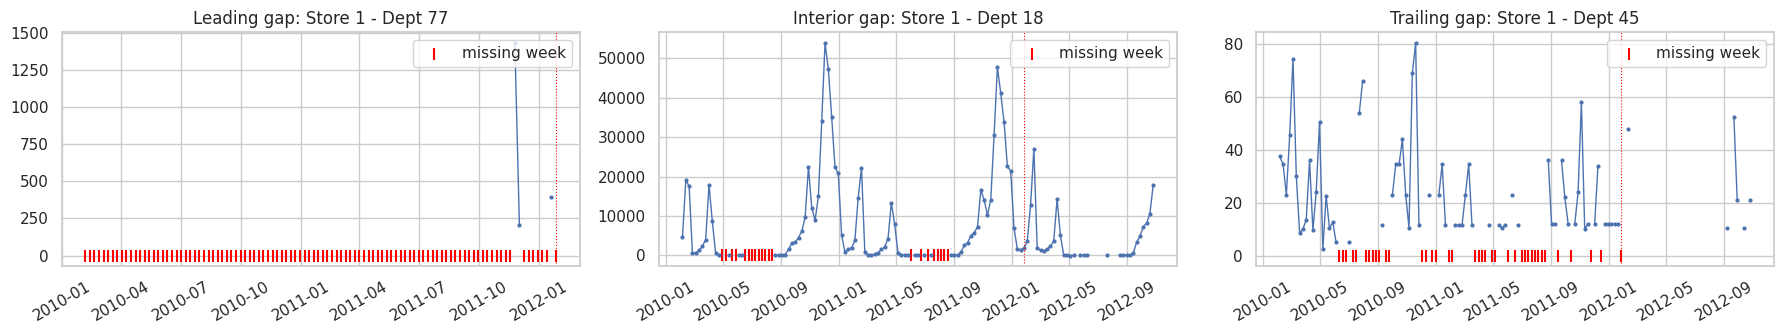

In [57]:
# picture: one example series for each gap type (the missing weeks are drawn as red marks at the bottom)
examples = {}
for gap in ["Leading gap", "Interior gap", "Trailing gap"]:
    first_series = panel.loc[panel["gap_type"] == gap, ["Store", "Dept"]].iloc[0]
    examples[gap] = (int(first_series["Store"]), int(first_series["Dept"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 3.5))
for ax, (gap, (store, dept)) in zip(axes, examples.items()):
    s = panel[(panel["Store"] == store) & (panel["Dept"] == dept)]
    ax.plot(s["Date"], s["Weekly_Sales"], marker="o", markersize=2, linewidth=1)
    miss = s[s["Weekly_Sales"].isna() & (s["split"] == "train")]
    ax.scatter(miss["Date"], np.zeros(len(miss)), color="red", marker="|", s=80, label="missing week")
    ax.axvline(split_date, color="red", linestyle=":", linewidth=0.8)
    ax.set_title(f"{gap}: Store {store} - Dept {dept}")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## C.5 Short series (less than one year of history)

In [58]:
# number of observed weeks per series in the training part
train_obs = panel[(panel["split"] == "train") & panel["Weekly_Sales"].notna()]
n_obs = train_obs.groupby(["Store", "Dept"]).size().rename("n_obs")

panel = panel.merge(n_obs, on=["Store", "Dept"], how="left")
panel["n_obs"] = panel["n_obs"].fillna(0).astype(int)      # series with no training data
panel["short_series"] = (panel["n_obs"] < 52).astype(int)

# summary at series level
series = panel.drop_duplicates(["Store", "Dept"])
print(len(series), "series;", series["short_series"].sum(), "have fewer than 52 observations")

3331 series; 389 have fewer than 52 observations


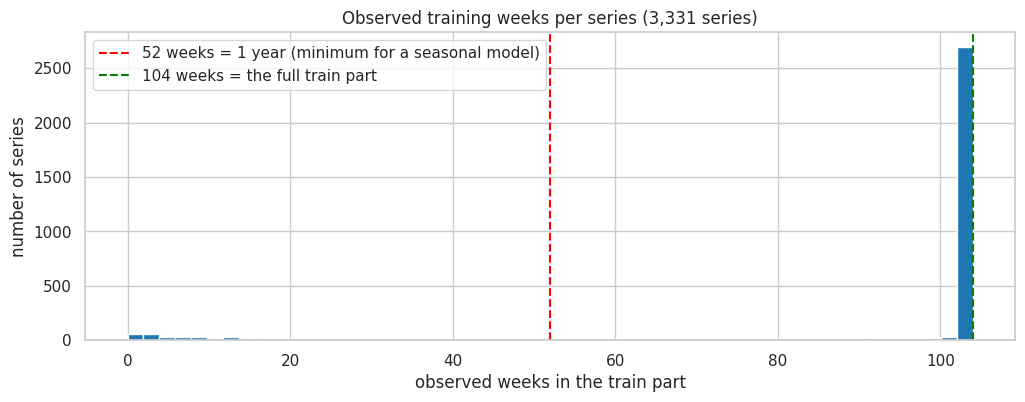

series with all 104 training weeks: 2678


In [59]:
plt.figure(figsize=(12, 4))
plt.hist(series["n_obs"], bins=53, color="tab:blue")
plt.axvline(52, color="red", linestyle="--", label="52 weeks = 1 year (minimum for a seasonal model)")
plt.axvline(104, color="green", linestyle="--", label="104 weeks = the full train part")
plt.title("Observed training weeks per series (3,331 series)")
plt.xlabel("observed weeks in the train part")
plt.ylabel("number of series")
plt.legend()
plt.show()

print("series with all 104 training weeks:", int((series["n_obs"] == 104).sum()))

In [60]:
# summary of the whole pipeline in one table
pipeline_summary = pd.DataFrame({
    "value": [len(panel), panel.groupby(["Store", "Dept"]).ngroups, int(panel["Weekly_Sales"].isna().sum()),
              int(panel["was_negative"].sum()), int(series["short_series"].sum()), int((series["n_obs"] == 104).sum())],
}, index=["panel rows (series x weeks)", "series", "missing weeks (train + test)", "negative weeks clipped",
          "short series (< 52 train weeks)", "series with all 104 train weeks"])
pipeline_summary

,value
panel rows (series x weeks),476333
series,3331
missing weeks (train + test),54763
negative weeks clipped,1285
short series (< 52 train weeks),389
series with all 104 train weeks,2678


**What I see**

- The complete panel has **476,333 rows = 3,331 series × 143 weeks**, and **54,763 of them are missing** (40,442 in the train part).
- The **interior gaps** are the most common (19,092). The example Store 1 – Dept 18 shows why: it's a seasonal department that sells almost nothing for months, so those "missing" weeks are very probably **weeks with zero sales**, not lost data.
- **Leading gaps** (13,805): departments that opened later (Store 1 – Dept 77 only appears at the end of 2011). **Trailing gaps** (7,545): departments that stopped (Store 1 – Dept 45).
- **389 series have fewer than 52 training weeks**, and **2,678 series have all 104**.

**Why it matters:** a statistical model needs a **complete, regular** series with at least one full year. That's exactly the screen applied in Part D. The teammate classified the gaps but didn't fill them, which isn't needed for departments 1–3.

# Part D — Why departments 1–3?

The teammate wrote that departments 1–3 can be used because they have no missing values. Here I check how special they are by screening **every** department with the same criterion. A department is "clean" for a statistical model if it is:

1. present in **all 45 stores**,
2. observed in **all 143 weeks** in every store (no gaps),
3. **never negative** (so a log transformation is possible).

In [61]:
# one line per department, computed from the panel
dept_screen = panel.groupby("Dept").agg(
    stores=("Store", "nunique"),
    missing_weeks=("Weekly_Sales", lambda x: int(x.isna().sum())),
    negative_weeks=("was_negative", "sum"),
)
dept_screen["share of sales %"] = dept_share.round(2)
dept_screen["clean"] = (dept_screen["stores"] == 45) & (dept_screen["missing_weeks"] == 0) & (dept_screen["negative_weeks"] == 0)

clean_depts = dept_screen.index[dept_screen["clean"]].tolist()
print("clean departments:", clean_depts)
print("number:", len(clean_depts), "| share of total sales:", round(dept_screen.loc[clean_depts, "share of sales %"].sum(), 1), "%")
dept_screen.head(12)

clean departments: [1, 2, 3, 4, 7, 8, 10, 13, 14, 21, 38, 40, 46, 67, 79, 81, 82, 90, 91, 92, 95]
number: 21 | share of total sales: 60.6 %


,stores,missing_weeks,negative_weeks,share of sales %,clean
Dept,,,,,
1,45,0,0,1.84,True
2,45,0,0,4.17,True
3,45,0,0,1.13,True
4,45,0,0,2.48,True
5,45,88,1,2.01,False
6,45,449,18,0.42,False
7,45,0,0,2.31,True
8,45,0,0,2.88,True
9,45,81,4,1.91,False


> **Code explained — named aggregation `agg(new_name=(column, function))`**
> Each argument creates one output column: `stores=("Store", "nunique")` means "count the distinct stores in each department and call it `stores`". A `lambda` is a small one-line function, used here to count missing values.

**What I see**

- **21 departments are "clean"** (in all 45 stores, all 143 weeks, never negative): 1, 2, 3, 4, 7, 8, 10, 13, 14, 21, 38, 40, 46, 67, 79, 81, 82, 90, 91, 92, 95. Together they make **60.6% of sales**.
- **Departments 1–3 are simply the first three of them**: Dept 4 is just as clean.

**The rationale for departments 1–3, in one paragraph (for the report):** Box–Jenkins modelling is done **series by series** and needs complete, strictly positive series with at least one full seasonal cycle. Departments 1–3 meet these conditions in all 45 stores (135 series). As Part E shows, they also cover **three different seasonal profiles**: several holiday peaks including moving ones (Dept 1), a stable profile (Dept 2) and one strong fixed seasonal peak (Dept 3). They represent 7.1% of total sales, so the results are not claimed to hold for every department.

### The subset: teammate's code (cell 76), then a check against his saved file

In [62]:
cols = ["Store", "Dept", "Date", "Weekly_Sales", "split", "is_holiday"]

subset = (
    panel.loc[panel["Dept"].between(1, 3), cols]
         .sort_values(["Dept", "Store", "Date"])
         .reset_index(drop=True)
)

# is it identical to the file saved by the teammate's notebook?
saved = pd.read_csv(DATA_DIR + "depts_1_to_3.csv", parse_dates=["Date"])
print("same shape :", subset.shape == saved.shape, subset.shape)
print("same keys  :", (subset[["Store", "Dept", "Date", "split", "is_holiday"]].values == saved[["Store", "Dept", "Date", "split", "is_holiday"]].values).all())
print("same sales :", np.allclose(subset["Weekly_Sales"], saved["Weekly_Sales"]))

same shape : True (19305, 6)
same keys  : True
same sales : True


# Part E — Deep dive into departments 1–3

From here on everything is about our **135 series** (3 departments × 45 stores).

## E.1 First look at the subset

In [63]:
subset.head()

,Store,Dept,Date,Weekly_Sales,split,is_holiday
0,1,1,2010-02-05,24924.50,train,0
1,1,1,2010-02-12,46039.49,train,1
2,1,1,2010-02-19,41595.55,train,0
3,1,1,2010-02-26,19403.54,train,0
4,1,1,2010-03-05,21827.90,train,0


In [64]:
subset.tail()

,Store,Dept,Date,Weekly_Sales,split,is_holiday
19300,45,3,2012-09-28,7657.71,test,0
19301,45,3,2012-10-05,7731.70,test,0
19302,45,3,2012-10-12,6880.10,test,0
19303,45,3,2012-10-19,6352.19,test,0
19304,45,3,2012-10-26,6726.03,test,0


In [65]:
subset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19305 entries, 0 to 19304
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         19305 non-null  int64         
 1   Dept          19305 non-null  int64         
 2   Date          19305 non-null  datetime64[ns]
 3   Weekly_Sales  19305 non-null  float64       
 4   split         19305 non-null  object        
 5   is_holiday    19305 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 905.1+ KB


In [66]:
# statistics of the weekly sales, per department (all stores, train + holdout)
subset.groupby("Dept")["Weekly_Sales"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
Dept,,,,,,,,
1,6435.0,19213.0,15102.0,711.0,10423.0,15315.0,23136.0,172226.0
2,6435.0,43607.0,25177.0,5453.0,22648.0,41413.0,60195.0,151090.0
3,6435.0,11794.0,12791.0,2.0,5338.0,9261.0,13406.0,131564.0


In [67]:
# quick health check of the 135 series
health = pd.DataFrame({
    "value": [subset.groupby(["Store", "Dept"]).ngroups,
              f"{subset.groupby(['Store', 'Dept']).size().min()} - {subset.groupby(['Store', 'Dept']).size().max()}",
              int(subset["Weekly_Sales"].isna().sum()), int((subset["Weekly_Sales"] < 0).sum()), int((subset["Weekly_Sales"] == 0).sum())],
    "why it matters for ARIMA": ["one model per series", "regular time axis, no holes",
                                 "no imputation needed", "log transformation possible", "log transformation possible"],
}, index=["series", "weeks per series", "missing values", "negative values", "zero values"])
health

,value,why it matters for ARIMA
series,135,one model per series
weeks per series,143 - 143,"regular time axis, no holes"
missing values,0,no imputation needed
negative values,0,log transformation possible
zero values,0,log transformation possible


## E.2 The three departments in total (all 45 stores added up)

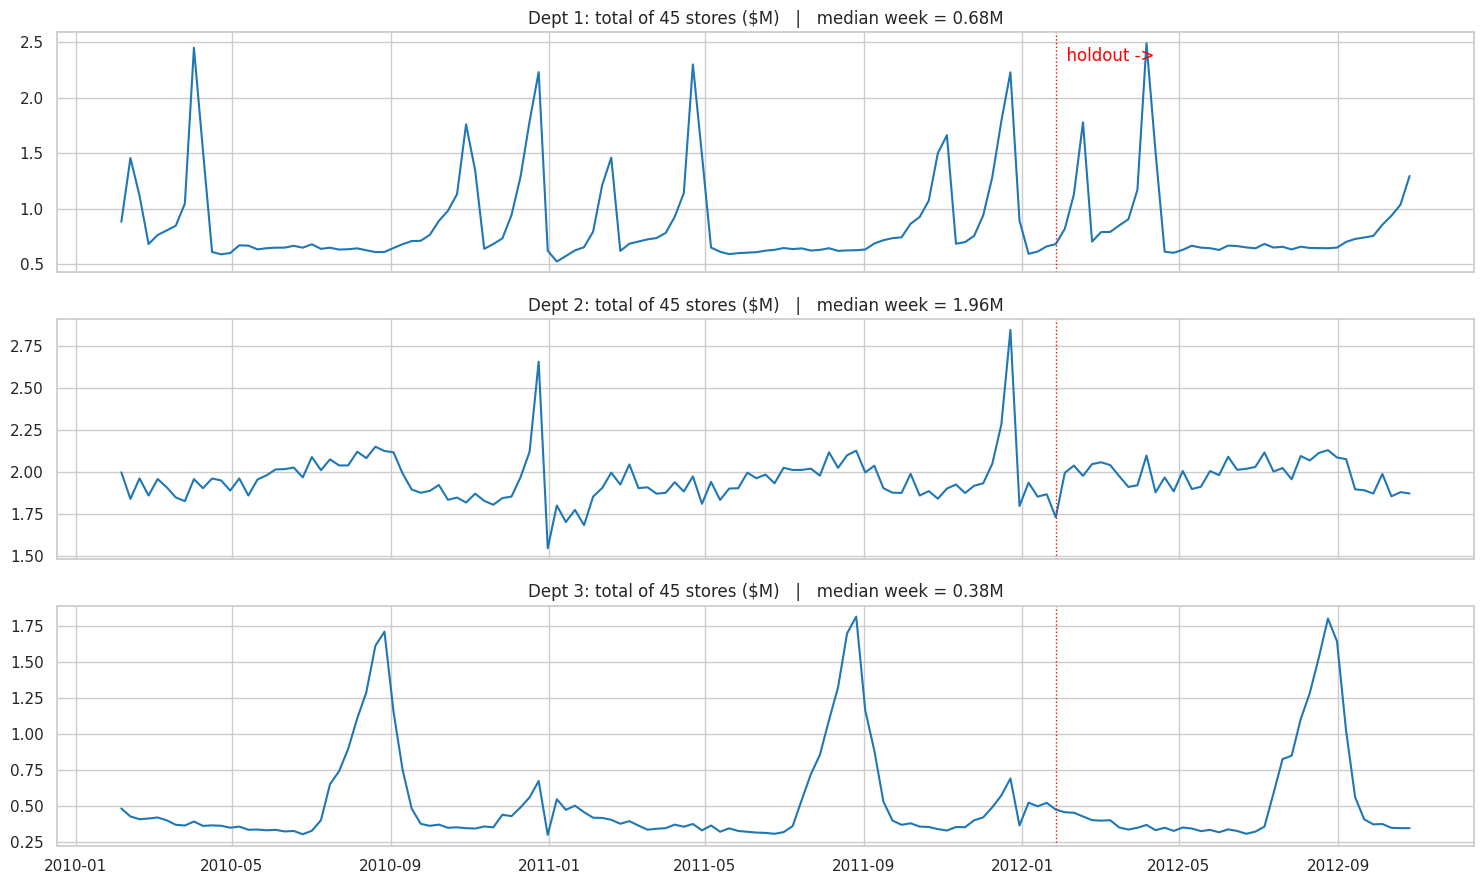

In [68]:
dept_weekly = subset.groupby(["Date", "Dept"])["Weekly_Sales"].sum().unstack() / 1e6      # rows = weeks, columns = depts

fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
for ax, dept in zip(axes, DEPTS):
    ax.plot(dept_weekly.index, dept_weekly[dept], color="tab:blue")
    ax.axvline(split_date, color="red", linestyle=":", linewidth=1)
    ax.set_title(f"Dept {dept}: total of 45 stores ($M)   |   median week = {dept_weekly[dept].median():.2f}M")
axes[0].text(split_date, axes[0].get_ylim()[1] * 0.9, "  holdout ->", color="red")
plt.tight_layout()
plt.show()

**What I see**

- **Dept 1:** four peaks every year: February (Super Bowl + Valentine's), **Easter** (April), **Halloween** (end of October) and **Christmas**. Flat in between. The holdout contains the February and the Easter 2012 peaks.
- **Dept 2:** the biggest department (≈ 2M per week for 45 stores), stable, with a **Christmas peak followed by a dip**, and a small bump in August.
- **Dept 3:** one huge **back-to-school** peak every August (×4–5), a small Christmas bump, flat otherwise.
- None of the three shows a clear trend.

## E.3 Do all 45 stores share the same shape? (teammate's mean scaling)

Stores differ a lot in size, so raw lines can't be compared. With the teammate's **mean scaling** (divide each series by the mean of its last 52 training weeks), 1.0 means "a normal week for this store" and all stores sit on the same scale.

Below: **every** store as a thin grey line, the median store in bold.

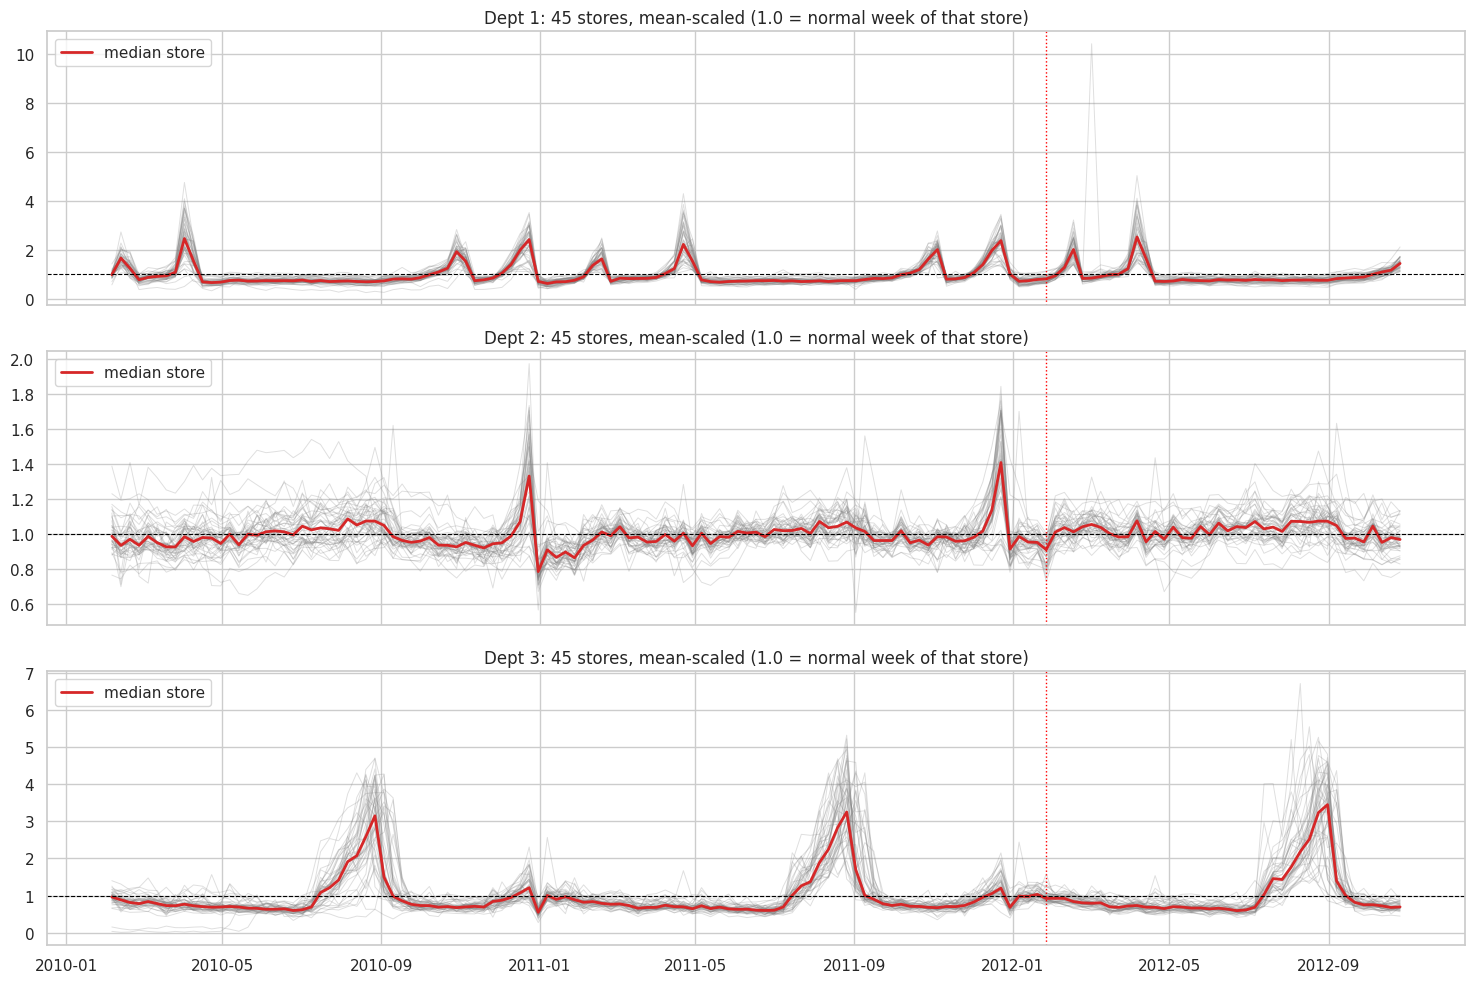

In [69]:
# scale = mean of the last 52 weeks of the train part, for each series (teammate's definition)
last_year = subset[(subset["split"] == "train") & (subset["Date"] > split_date - pd.Timedelta(weeks=52))]
scale = last_year.groupby(["Store", "Dept"])["Weekly_Sales"].mean().rename("scale")
subset_scaled = subset.merge(scale, on=["Store", "Dept"])
subset_scaled["sales_scaled"] = subset_scaled["Weekly_Sales"] / subset_scaled["scale"]

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
for ax, dept in zip(axes, DEPTS):
    wide = subset_scaled[subset_scaled["Dept"] == dept].pivot(index="Date", columns="Store", values="sales_scaled")
    ax.plot(wide.index, wide.values, color="grey", alpha=0.25, linewidth=0.7)     # 45 thin lines at once
    ax.plot(wide.index, wide.median(axis=1), color="tab:red", linewidth=2, label="median store")
    ax.axhline(1, color="black", linestyle="--", linewidth=0.8)
    ax.axvline(split_date, color="red", linestyle=":", linewidth=1)
    ax.set_title(f"Dept {dept}: 45 stores, mean-scaled (1.0 = normal week of that store)")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

> **Code explained — `pivot(index="Date", columns="Store", values="sales_scaled")`**
> Turns the long table (one row per store × week) into a wide one: one row per week, one column per store. `ax.plot(x, wide.values)` then draws all 45 columns in one call.

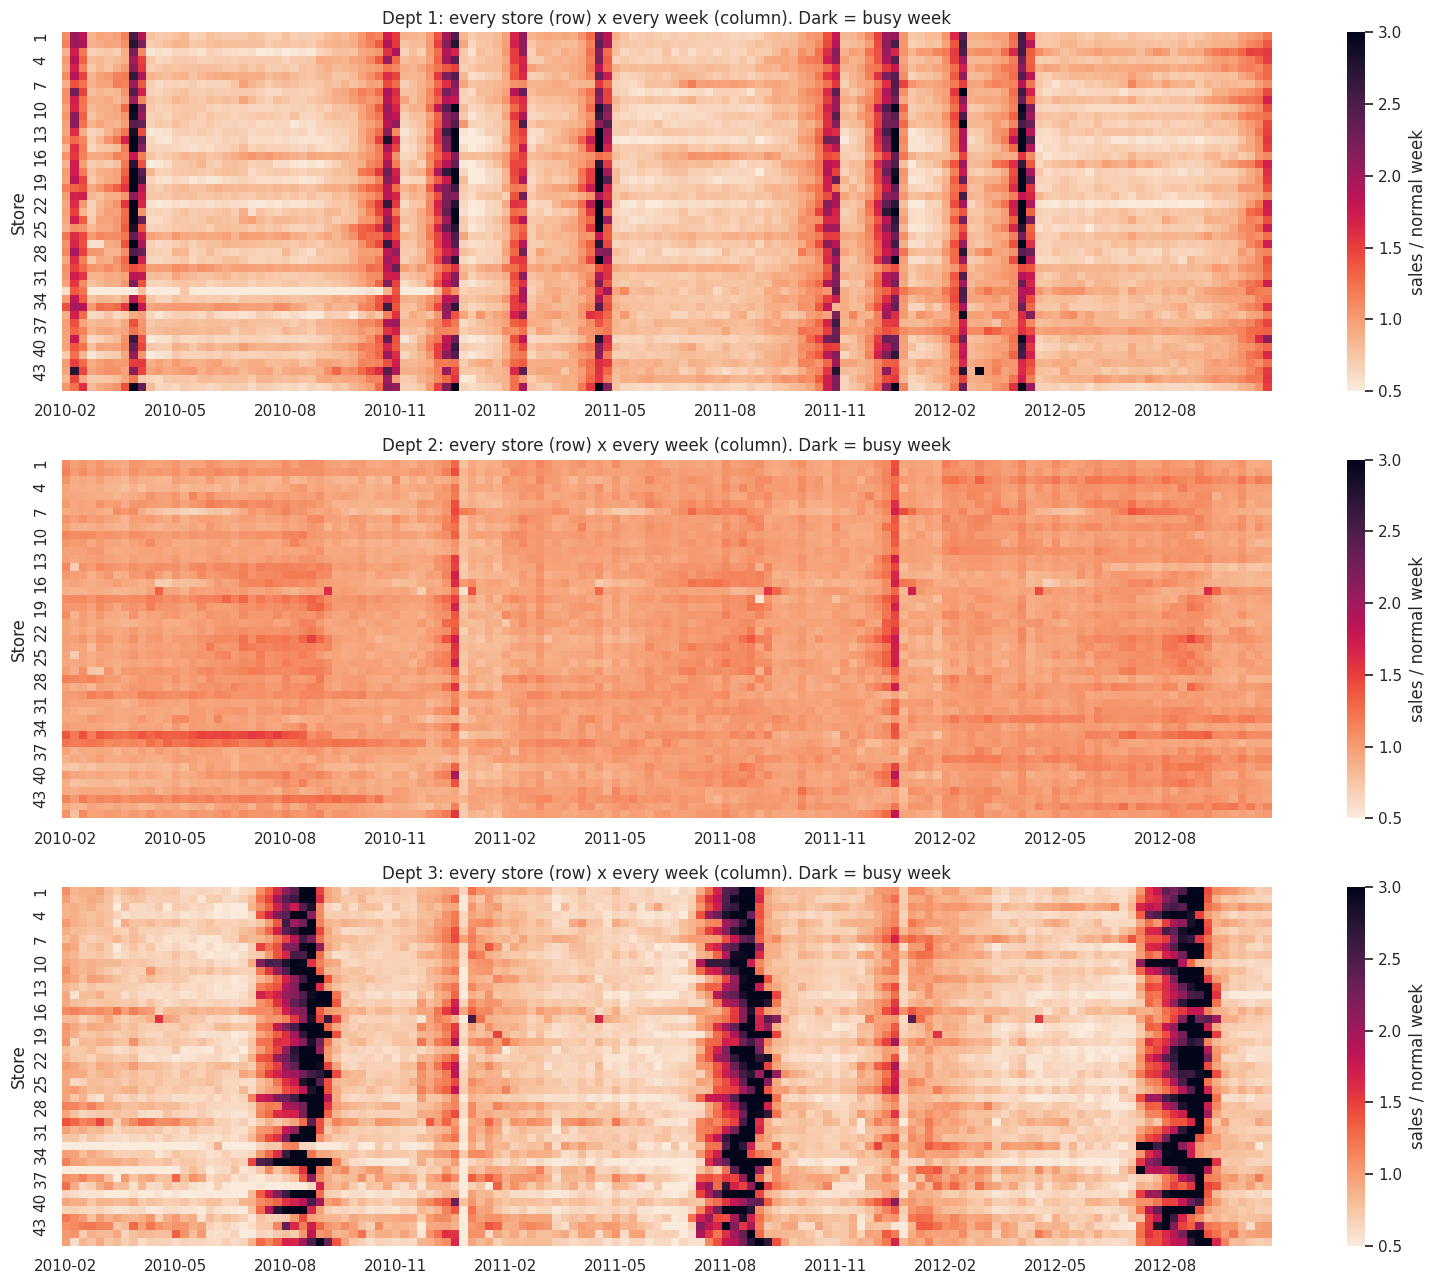

In [70]:
# the same information as a heatmap: rows = stores, columns = weeks, colour = scaled sales
fig, axes = plt.subplots(3, 1, figsize=(16, 13))
for ax, dept in zip(axes, DEPTS):
    wide = subset_scaled[subset_scaled["Dept"] == dept].pivot(index="Store", columns="Date", values="sales_scaled")
    sns.heatmap(wide, cmap="rocket_r", vmin=0.5, vmax=3, ax=ax, cbar_kws={"label": "sales / normal week"})
    tick_pos = range(0, wide.shape[1], 13)
    ax.set_xticks([p + 0.5 for p in tick_pos])
    ax.set_xticklabels([wide.columns[p].strftime("%Y-%m") for p in tick_pos], rotation=0)
    ax.set_xlabel("")
    ax.set_title(f"Dept {dept}: every store (row) x every week (column). Dark = busy week")
plt.tight_layout()
plt.show()

**What I see**

- **Dept 1:** a tight bundle. Every store has the same four holiday peaks, in the same weeks (vertical dark stripes in the heatmap).
- **Dept 3:** every store has the back-to-school peak, but **not in the same week**: the peak week goes from early August to mid-September (in 2011: 24 stores peak on 26 Aug, 8 on 19 Aug, 7 on 2 Sep…), probably because school starts on different dates in different regions.
- **Dept 2:** a looser bundle. The Christmas spike is shared, the rest is more store-specific noise.
- **One outlier:** Store 43 – Dept 1 on 2012-03-02 sells **10.4×** its normal level (the black cell in March 2012 and the grey spike in the line plot), in a week with no holiday. It's a one-off event no model can forecast, and it sits in the **holdout**.

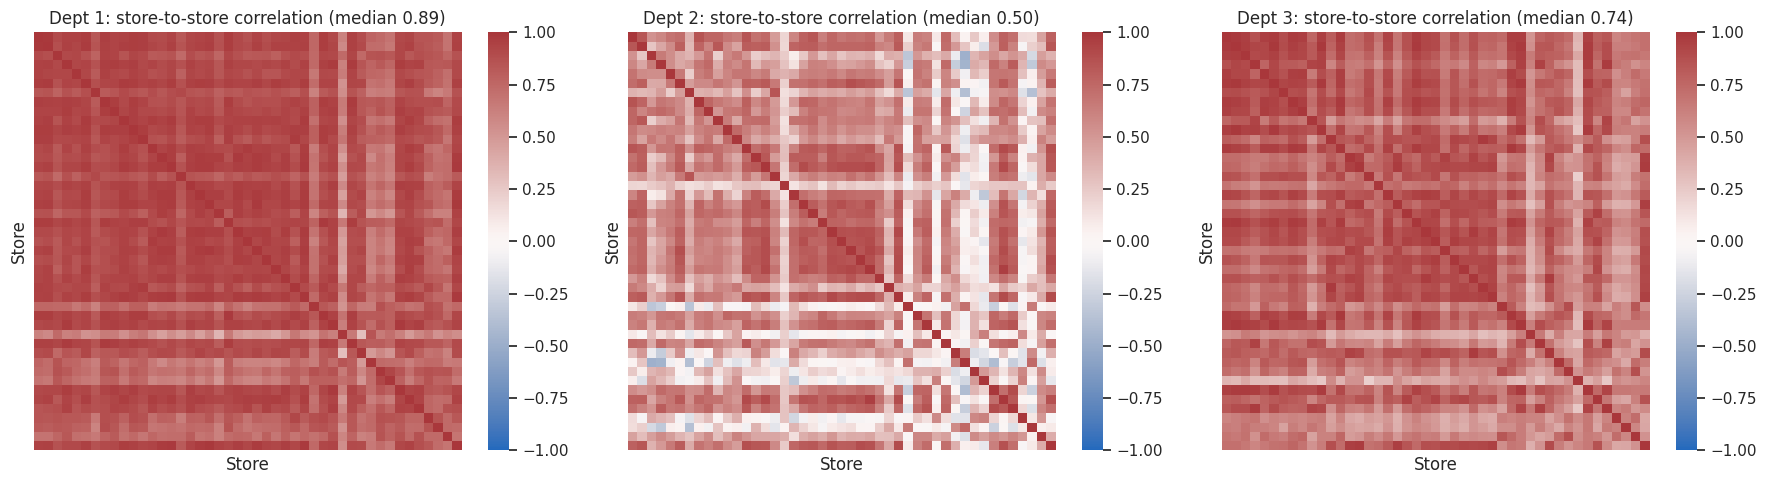

median correlation between two stores: {'Dept 1': np.float64(0.89), 'Dept 2': np.float64(0.5), 'Dept 3': np.float64(0.74)}


In [71]:
# how similar are the stores? correlation between the scaled series of every pair of stores (train part only)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
median_corr = {}
for ax, dept in zip(axes, DEPTS):
    wide = subset_scaled[(subset_scaled["Dept"] == dept) & (subset_scaled["split"] == "train")].pivot(index="Date", columns="Store", values="sales_scaled")
    corr_matrix = wide.corr()                                           # 45 x 45 table of correlations
    upper = corr_matrix.values[np.triu_indices(45, k=1)]                # each pair once (above the diagonal)
    median_corr[f"Dept {dept}"] = round(np.median(upper), 2)
    sns.heatmap(corr_matrix, cmap="vlag", vmin=-1, vmax=1, ax=ax, xticklabels=False, yticklabels=False)
    ax.set_title(f"Dept {dept}: store-to-store correlation (median {np.median(upper):.2f})")
plt.tight_layout()
plt.show()
print("median correlation between two stores:", median_corr)

**What I see:** the median correlation between two stores is **0.89 in Dept 1**, 0.74 in Dept 3, but only **0.50 in Dept 2**. In Dept 1 almost all the movement comes from the calendar, which every store shares. In Dept 2, most weekly movements are specific to each store.

**Why it matters:** where the calendar dominates (Dept 1, Dept 3), modelling the calendar well is the key. Where it doesn't (Dept 2), there's less to gain beyond "a normal week", and that will show up in the forecast results. For the ML teammates, this also says **pooling** works best for Depts 1 and 3.

## E.4 Scale and variability of the 135 series

In [72]:
def describe_series(s):
    # one line of numbers about one series, train part only
    y = s.loc[s["split"] == "train"].set_index("Date")["Weekly_Sales"]
    return {
        "mean": round(y.mean()),
        "median": round(y.median()),
        "std": round(y.std()),
        "CV (std/mean)": round(y.std() / y.mean(), 2),
        "min": round(y.min()),
        "max": round(y.max()),
        "max / median": round(y.max() / y.median(), 2),
        "peak week": y.idxmax().date(),
    }

rows = []
for (store, dept), s in subset.groupby(["Store", "Dept"]):
    r = describe_series(s)
    r.update({"Store": store, "Dept": dept})
    rows.append(r)
all_series_table = pd.DataFrame(rows)

print("Store 1:")
print(all_series_table[all_series_table["Store"] == FOCUS_STORE].set_index("Dept").drop(columns="Store"))

Store 1:
       mean  median    std  CV (std/mean)    min    max  max / median   peak week
Dept                                                                             
1     22770   18755  10057           0.44  14537  57258          3.05  2010-04-02
2     45799   45148   3613           0.08  35820  65615          1.45  2011-12-23
3     12750   10273   8201           0.64   6166  51159          4.98  2010-08-27


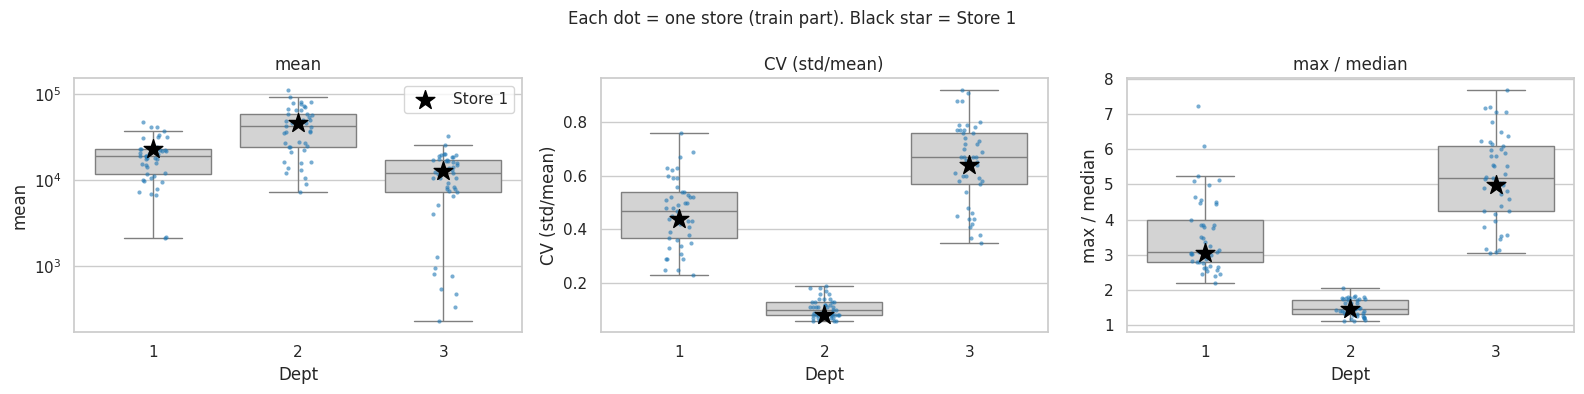

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["mean", "CV (std/mean)", "max / median"]):
    sns.boxplot(data=all_series_table, x="Dept", y=col, color="lightgrey", ax=ax, showfliers=False)
    sns.stripplot(data=all_series_table, x="Dept", y=col, color="tab:blue", size=3, alpha=0.6, ax=ax)
    store1 = all_series_table[all_series_table["Store"] == FOCUS_STORE]
    ax.scatter(range(len(DEPTS)), store1[col], color="black", marker="*", s=200, zorder=5, label="Store 1")
    if col == "mean":
        ax.set_yscale("log")
    ax.set_title(col)
axes[0].legend()
fig.suptitle("Each dot = one store (train part). Black star = Store 1", fontsize=12)
plt.tight_layout()
plt.show()

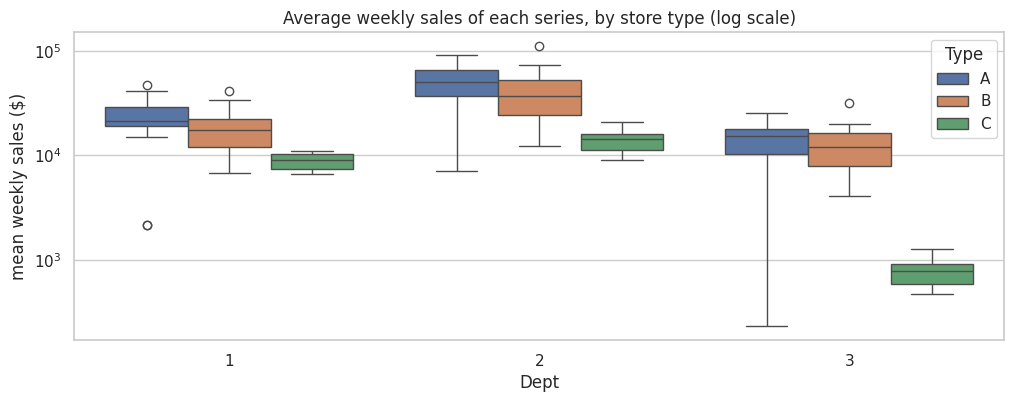

In [74]:
# does the store type matter inside our departments? average weekly sales per series, by store type
type_check = all_series_table.merge(stores, on="Store")
plt.figure(figsize=(12, 4))
sns.boxplot(data=type_check, x="Dept", y="mean", hue="Type", hue_order=["A", "B", "C"])
plt.yscale("log")
plt.title("Average weekly sales of each series, by store type (log scale)")
plt.ylabel("mean weekly sales ($)")
plt.show()

**What I see**

- **Store 1 (black star) sits in the middle** of every distribution: average level, variability (CV) and peak size. It's a **representative** store for the step-by-step study, as the teammate proposed.
- **Dept 2** is the biggest and the most stable (CV 0.06–0.19, peaks ≈ 1.5× the median).
- **Dept 3** is the most volatile (CV up to 0.92, peaks up to 7.7× the median).
- **A few Dept 3 series are tiny** (< 1.3k per week): they're the 8 smallest stores (the type C stores and stores 33 / 36). The back-to-school department barely exists in small stores. On such small numbers, % errors will be large.
- Store type ranks the sales the same way in all 3 departments: **A > B > C**.

# Part F — Calendar and holidays

## F.1 What exactly is "one week"?

`Date` is always a **Friday**, and a row dated Friday 2010-12-31 contains the sales from **Saturday 25 December to Friday 31 December**. So `Date` is the **last day** of the week. This small detail explains several holiday surprises below.

In [75]:
# full calendar of all weeks we will ever need: train part + holdout + forecast set (test.csv)
week_calendar = pd.DataFrame({"Date": pd.date_range("2010-02-05", "2013-07-26", freq="W-FRI")})
week_calendar["week_start"] = week_calendar["Date"] - pd.Timedelta(days=6)        # the Saturday that opens the week
week_calendar["year"] = week_calendar["Date"].dt.year
week_calendar["week_of_year"] = week_calendar["Date"].dt.isocalendar().week.astype(int)
week_calendar["t"] = np.arange(len(week_calendar))       # week counter 0, 1, 2, ... (used for Fourier terms later)

# official holiday flag (features.csv covers all 182 weeks)
week_calendar = week_calendar.merge(holiday, on="Date", how="left")
week_calendar["holiday_name"] = np.where(week_calendar["is_holiday"] == 1,
                                         week_calendar["Date"].dt.month.map(month_to_name), "")

# role of each week
week_calendar["role"] = np.select(
    [week_calendar["Date"] <= split_date, week_calendar["Date"] <= train["Date"].max()],
    ["train part", "holdout part"], default="forecast set")

print(week_calendar.shape)
week_calendar.loc[week_calendar["is_holiday"] == 1, ["week_start", "Date", "holiday_name", "role"]]

(182, 8)


,week_start,Date,holiday_name,role
1,2010-02-06,2010-02-12,Super Bowl,train part
31,2010-09-04,2010-09-10,Labor Day,train part
42,2010-11-20,2010-11-26,Thanksgiving,train part
47,2010-12-25,2010-12-31,Christmas,train part
53,2011-02-05,2011-02-11,Super Bowl,train part
83,2011-09-03,2011-09-09,Labor Day,train part
94,2011-11-19,2011-11-25,Thanksgiving,train part
99,2011-12-24,2011-12-30,Christmas,train part
105,2012-02-04,2012-02-10,Super Bowl,holdout part
135,2012-09-01,2012-09-07,Labor Day,holdout part


## F.2 The Christmas flag is on the wrong week

The teammate noticed that the flagged Christmas week is not the shopping peak (his Note 5, `christmas_peak`). Here are the numbers for our 3 departments (all stores added up):

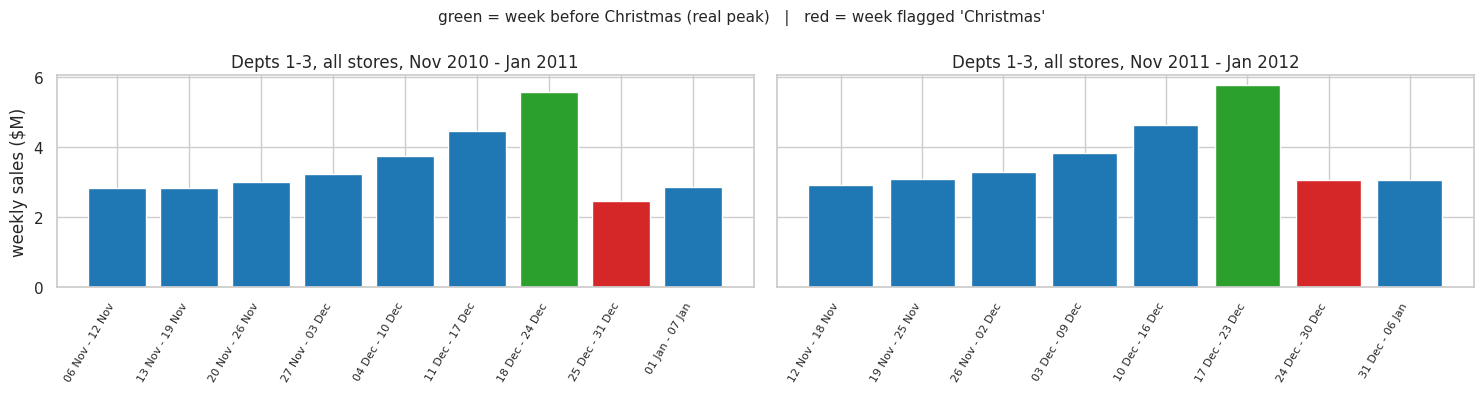

,year,week,sales ($M),official flag,week before Christmas
0,2010,06 Nov - 12 Nov,2.83,,
1,2010,13 Nov - 19 Nov,2.84,,
2,2010,20 Nov - 26 Nov,3.02,Thanksgiving,
3,2010,27 Nov - 03 Dec,3.23,,
4,2010,04 Dec - 10 Dec,3.75,,
5,2010,11 Dec - 17 Dec,4.47,,
6,2010,18 Dec - 24 Dec,5.57,,yes
7,2010,25 Dec - 31 Dec,2.47,Christmas,
8,2010,01 Jan - 07 Jan,2.87,,
9,2011,12 Nov - 18 Nov,2.93,,


In [76]:
total_123 = subset.groupby("Date")["Weekly_Sales"].sum()

rows = []
for year in [2010, 2011]:
    window = total_123[(total_123.index >= f"{year}-11-12") & (total_123.index <= f"{year + 1}-01-07")]
    for day, value in window.items():
        rows.append({"year": year,
                     "week": f"{(day - pd.Timedelta(days=6)).strftime('%d %b')} - {day.strftime('%d %b')}",
                     "sales ($M)": round(value / 1e6, 2),
                     "official flag": week_calendar.set_index("Date").loc[day, "holiday_name"],
                     # the week just before Christmas: its Friday falls between 18 and 24 December
                     "week before Christmas": "yes" if (day.month == 12 and 18 <= day.day <= 24) else ""})
christmas_window = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, year in zip(axes, [2010, 2011]):
    w = christmas_window[christmas_window["year"] == year]
    colors = []
    for flag, before in zip(w["official flag"], w["week before Christmas"]):
        if flag == "Christmas":
            colors.append("tab:red")            # week flagged "Christmas" in the data
        elif before == "yes":
            colors.append("tab:green")          # real shopping peak
        else:
            colors.append("tab:blue")
    ax.bar(range(len(w)), w["sales ($M)"], color=colors)
    ax.set_xticks(range(len(w)))
    ax.set_xticklabels(w["week"], rotation=60, ha="right", fontsize=8)
    ax.set_title(f"Depts 1-3, all stores, Nov {year} - Jan {year + 1}")
axes[0].set_ylabel("weekly sales ($M)")
fig.suptitle("green = week before Christmas (real peak)   |   red = week flagged 'Christmas'", fontsize=11)
plt.tight_layout()
plt.show()
christmas_window

**What I see:** in both years the highest week is **18–24 December** (green): 5.6M and 5.8M for our 3 departments. The week flagged "Christmas" (red, 25–31 December) is one of the **lowest** of the winter (2.5M and 3.1M).

**Why:** the flagged week **starts on Christmas Day**, so it only contains the days after Christmas, when the shopping is over. The flag is right as a calendar fact, but it points at the wrong week for *sales*. This is the reason for the teammate's `christmas_peak` idea.

## F.3 The pre-holiday shopping weeks of Dept 1

Dept 1 has several sharp peaks per year. To see which holiday each peak belongs to, I list the **biggest weeks of the train part** for the median store (mean-scaled), with the holidays of that week and the week after:

In [77]:
d1_median = subset_scaled[(subset_scaled["Dept"] == 1) & (subset_scaled["split"] == "train")].groupby("Date")["sales_scaled"].median()
peaks = d1_median.sort_values(ascending=False).head(14).sort_index().round(2).to_frame("median store, scaled")
peaks["week (Sat - Fri)"] = [f"{(d - pd.Timedelta(days=6)).strftime('%a %d %b')} - {d.strftime('%a %d %b %Y')}" for d in peaks.index]

# which holidays fall inside the week, or in the 7 days after it?
holiday_days = {"Valentine's Day": [f"{y}-02-14" for y in (2010, 2011, 2012)],
                "Easter Sunday": [str(easter(y)) for y in (2010, 2011, 2012)],
                "Halloween": [f"{y}-10-31" for y in (2010, 2011)],
                "Christmas Day": [f"{y}-12-25" for y in (2010, 2011)]}
def nearby_holiday(week_end):
    found = []
    for name, days in holiday_days.items():
        for day in pd.to_datetime(days):
            gap = (day - week_end).days            # days from the end of the week to the holiday
            if -6 <= gap <= 0:
                found.append(f"{name} (inside the week)")
            elif 0 < gap <= 7:
                found.append(f"{name} ({gap} day(s) after)")
    return ", ".join(found)
peaks["holiday"] = [nearby_holiday(d) for d in peaks.index]
peaks

,"median store, scaled",week (Sat - Fri),holiday
Date,,,
2010-02-12,1.66,Sat 06 Feb - Fri 12 Feb 2010,Valentine's Day (2 day(s) after)
2010-04-02,2.46,Sat 27 Mar - Fri 02 Apr 2010,Easter Sunday (2 day(s) after)
2010-04-09,1.55,Sat 03 Apr - Fri 09 Apr 2010,Easter Sunday (inside the week)
2010-10-29,1.93,Sat 23 Oct - Fri 29 Oct 2010,Halloween (2 day(s) after)
2010-11-05,1.53,Sat 30 Oct - Fri 05 Nov 2010,Halloween (inside the week)
2010-12-17,1.99,Sat 11 Dec - Fri 17 Dec 2010,
2010-12-24,2.42,Sat 18 Dec - Fri 24 Dec 2010,Christmas Day (1 day(s) after)
2011-02-18,1.63,Sat 12 Feb - Fri 18 Feb 2011,Valentine's Day (inside the week)
2011-04-22,2.22,Sat 16 Apr - Fri 22 Apr 2011,Easter Sunday (2 day(s) after)


**What I see:** the 14 biggest weeks of Dept 1 (median store) are **all pre-holiday weeks**:

| Holiday | Peak weeks | Where the holiday falls |
|---|---|---|
| Valentine's Day | 2010-02-12, 2011-02-18 | 2 days after the 2010 week (Valentine's was a Sunday), inside the 2011 week (a Monday) |
| Easter | 2010-04-02, 2011-04-22 | **2 days after** the week (Easter Sunday). The week containing Easter is also high |
| Halloween | 2010-10-29, 2011-11-04 | 2 days after (2010, a Sunday), inside (2011, a Monday) |
| Christmas | 2010-12-17/24, 2011-12-16/23 | the two weeks just before |

**The pattern:** the peak is always the Saturday–Friday week containing **the last days before the holiday**. People buy candy and gifts *before* the day. One simple rule describes all of them: **the week that contains the day two days before the holiday**. When the holiday falls on a Sunday or Monday, that day is in the *previous* week. That's why the peak week can jump from one year to the next.

## F.4 Does each special week fall in the same week every year?

A seasonal model with `s = 52` predicts a week from **the same week 52 weeks earlier**. 52 weeks = 364 days, so the calendar slides by one day per year. Most events still land in the "same" week, but a **moving** event jumps.

**Check:** for each event, take the week (Friday) that contains it, and count the weeks between consecutive years. **52 = aligned, anything else = misaligned.**

In [78]:
def week_ending(day):
    # the Friday that closes the Saturday-Friday week containing `day`
    day = pd.Timestamp(day)
    return day + pd.Timedelta(days=(4 - day.weekday()) % 7)      # weekday(): Monday = 0 ... Friday = 4

events = {
    "Super Bowl (official)":   ["2010-02-07", "2011-02-06", "2012-02-05"],
    "Valentine's Day":         ["2010-02-14", "2011-02-14", "2012-02-14"],
    "Easter Sunday":           [easter(2010), easter(2011), easter(2012)],
    "Labor Day (official)":    ["2010-09-06", "2011-09-05", "2012-09-03"],
    "Halloween":               ["2010-10-31", "2011-10-31", "2012-10-31"],
    "Thanksgiving (official)": ["2010-11-25", "2011-11-24", "2012-11-22"],
    "Christmas (official)":    ["2010-12-25", "2011-12-25", "2012-12-25"],
}

rows = []
for name, days in events.items():
    previous_week = None
    for day in days:
        week = week_ending(day)
        gap = (week - previous_week).days // 7 if previous_week is not None else None
        rows.append({"event": name, "event date": pd.Timestamp(day).date(), "weekday": pd.Timestamp(day).day_name(),
                     "week (Date)": week.date(), "weeks since last year": gap,
                     "role": week_calendar.loc[week_calendar["Date"] == week, "role"].iloc[0]})
        previous_week = week
event_alignment = pd.DataFrame(rows)
event_alignment

,event,event date,weekday,week (Date),weeks since last year,role
0,Super Bowl (official),2010-02-07,Sunday,2010-02-12,NaN,train part
1,Super Bowl (official),2011-02-06,Sunday,2011-02-11,52.0,train part
2,Super Bowl (official),2012-02-05,Sunday,2012-02-10,52.0,holdout part
3,Valentine's Day,2010-02-14,Sunday,2010-02-19,NaN,train part
4,Valentine's Day,2011-02-14,Monday,2011-02-18,52.0,train part
5,Valentine's Day,2012-02-14,Tuesday,2012-02-17,52.0,holdout part
6,Easter Sunday,2010-04-04,Sunday,2010-04-09,NaN,train part
7,Easter Sunday,2011-04-24,Sunday,2011-04-29,55.0,train part
8,Easter Sunday,2012-04-08,Sunday,2012-04-13,50.0,holdout part
9,Labor Day (official),2010-09-06,Monday,2010-09-10,NaN,train part


### F.5 New calendar columns (all known in advance)

| Column | 1 when… | Evidence |
|---|---|---|
| `superbowl`, `labor_day`, `thanksgiving`, `christmas` | the official holiday week (the teammate's `is_holiday`, split by holiday) | official flags |
| `christmas_peak` | the week ending between 18 and 24 December (teammate's rule) | F.2 (teammate's Note 5) |
| `easter_week` | the week containing **Good Friday** (Easter Sunday − 2 days) | F.3 (teammate's Note 5 question) |
| `valentine_week` | the week containing **12 February** (Valentine's Day − 2 days) | F.3 |
| `halloween_week` | the week containing **29 October** (Halloween − 2 days) | F.3 |

**One rule for all pre-holiday weeks.** Table F.3 shows that the peak is always the Saturday–Friday week containing **the day two days before the holiday**, because people shop on the days just before the holiday, not on the holiday itself. For Christmas, the teammate's rule (week ending 18–24 December) gives the same weeks in 2010 and 2011.

Then I check which of these **shopping weeks** are aligned with lag 52, the same way as above.

In [79]:
# split the official flag into 4 columns
week_calendar["superbowl"] = (week_calendar["holiday_name"] == "Super Bowl").astype(int)
week_calendar["labor_day"] = (week_calendar["holiday_name"] == "Labor Day").astype(int)
week_calendar["thanksgiving"] = (week_calendar["holiday_name"] == "Thanksgiving").astype(int)
week_calendar["christmas"] = (week_calendar["holiday_name"] == "Christmas").astype(int)

# pre-holiday shopping weeks = the Sat-Fri week that contains the day TWO DAYS BEFORE the holiday (rule found in F.3)
week_calendar["christmas_peak"] = ((week_calendar["Date"].dt.month == 12) &
                                   (week_calendar["Date"].dt.day.between(18, 24))).astype(int)
good_fridays = [pd.Timestamp(easter(y)) - pd.Timedelta(days=2) for y in range(2010, 2014)]
week_calendar["easter_week"] = week_calendar["Date"].isin(good_fridays).astype(int)
week_calendar["valentine_week"] = week_calendar["Date"].isin([week_ending(f"{y}-02-12") for y in range(2010, 2014)]).astype(int)
week_calendar["halloween_week"] = week_calendar["Date"].isin([week_ending(f"{y}-10-29") for y in range(2010, 2013)]).astype(int)

new_flags = ["superbowl", "valentine_week", "easter_week", "labor_day", "halloween_week",
             "thanksgiving", "christmas_peak", "christmas"]

# alignment of each flag: weeks between its occurrences
rows = []
for flag in new_flags:
    flag_dates = week_calendar.loc[week_calendar[flag] == 1, "Date"]
    gaps = (flag_dates.diff().dt.days // 7).dropna().astype(int).tolist()
    rows.append({"flag": flag, "flagged weeks": ", ".join(d.strftime("%Y-%m-%d") for d in flag_dates),
                 "weeks between occurrences": ", ".join(map(str, gaps)),
                 "aligned with lag 52?": "yes" if set(gaps) == {52} else "NO"})
flag_alignment = pd.DataFrame(rows).set_index("flag")
flag_alignment

,flagged weeks,weeks between occurrences,aligned with lag 52?
flag,,,
superbowl,"2010-02-12, 2011-02-11, 2012-02-10, 2013-02-08","52, 52, 52",yes
valentine_week,"2010-02-12, 2011-02-18, 2012-02-17, 2013-02-15","53, 52, 52",NO
easter_week,"2010-04-02, 2011-04-22, 2012-04-06, 2013-03-29","55, 50, 51",NO
labor_day,"2010-09-10, 2011-09-09, 2012-09-07","52, 52",yes
halloween_week,"2010-10-29, 2011-11-04, 2012-11-02","53, 52",NO
thanksgiving,"2010-11-26, 2011-11-25, 2012-11-23","52, 52",yes
christmas_peak,"2010-12-24, 2011-12-23, 2012-12-21","52, 52",yes
christmas,"2010-12-31, 2011-12-30, 2012-12-28","52, 52",yes


**What I see**

- In the first table (the week containing each **event**), only **Easter Sunday** moves (+55, +50 weeks).
- In the second table (the **shopping weeks** we actually flag), **three flags move**: `easter_week` (55, 50, 51), and also **`valentine_week` and `halloween_week` between 2010 and 2011 (53 weeks)**. In 2010 both holidays fell on a Sunday, so their shopping peak was in the *earlier* week.
- All official holiday weeks and `christmas_peak` are aligned (always 52).

**Why it matters (this is subtle, and important for the report):** an event can stay in "the same week" while its **shopping week moves**. A seasonal model that copies "the same week last year" (lag 52) will copy these three peaks to the **wrong week** whenever they move: Easter almost every year, Valentine's and Halloween between 2010 and 2011. In our **holdout** the one that matters is **Easter 2012** (2012-04-06 vs 2011-04-22). In the **forecast set**, Easter 2013 (2013-03-29) moves again.

### F.6 How big is each flagged week? (train part only)

For each department: the average sales of the flagged weeks divided by the series median (1.00 = a normal week), averaged over the 45 stores. Using only the **train part** keeps the holdout untouched.

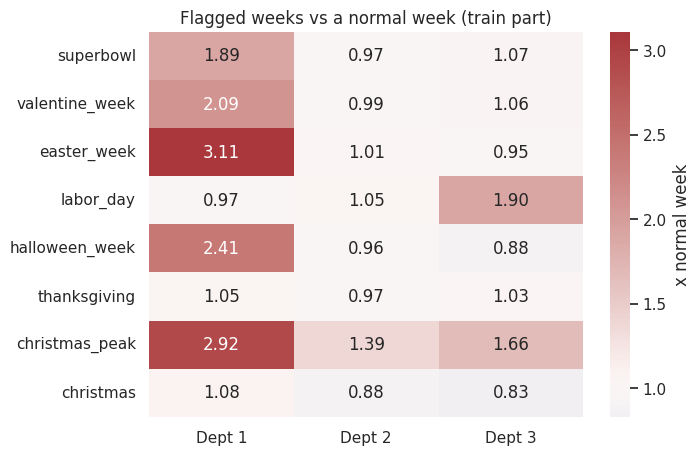

In [80]:
subset_flags = subset.merge(week_calendar[["Date"] + new_flags], on="Date", how="left")
train_part = subset_flags[subset_flags["split"] == "train"].copy()
train_part["ratio_to_median"] = train_part["Weekly_Sales"] / train_part.groupby(["Store", "Dept"])["Weekly_Sales"].transform("median")

flag_effect = pd.DataFrame({flag: train_part[train_part[flag] == 1].groupby("Dept")["ratio_to_median"].mean()
                            for flag in new_flags}).T.round(2)
flag_effect.columns = [f"Dept {d}" for d in flag_effect.columns]

plt.figure(figsize=(7, 5))
sns.heatmap(flag_effect, annot=True, fmt=".2f", cmap="vlag", center=1, cbar_kws={"label": "x normal week"})
plt.title("Flagged weeks vs a normal week (train part)")
plt.show()

**What I see** (1.00 = a normal week of the same series, train part)

| Flag | Dept 1 | Dept 2 | Dept 3 | Reading |
|---|---|---|---|---|
| `easter_week` | **3.11** | 1.01 | 0.95 | huge, Dept 1 only |
| `christmas_peak` | **2.92** | **1.39** | **1.66** | the real Christmas effect, all departments |
| `halloween_week` | **2.41** | 0.96 | 0.88 | Dept 1 only |
| `valentine_week` | **2.09** | 0.99 | 1.06 | Dept 1 only |
| `superbowl` | **1.89** | 0.97 | 1.07 | Dept 1: the week **before** Valentine's week, already busy |
| `labor_day` | 0.97 | 1.05 | **1.90** | Dept 3: the end of the **back-to-school** peak |
| `thanksgiving` | 1.05 | 0.97 | 1.03 | no effect for our 3 departments (unlike Dept 5) |
| `christmas` (official) | 1.08 | 0.88 | 0.83 | weak or even **below** normal |

**Why it matters:** Dept 1 is driven by **five** special weeks, Dept 2 by Christmas only, Dept 3 by the back-to-school season (which is a smooth season, not a single special week). The calendar columns built here capture exactly these weeks, and since they're known in advance, they're allowed in SARIMAX.

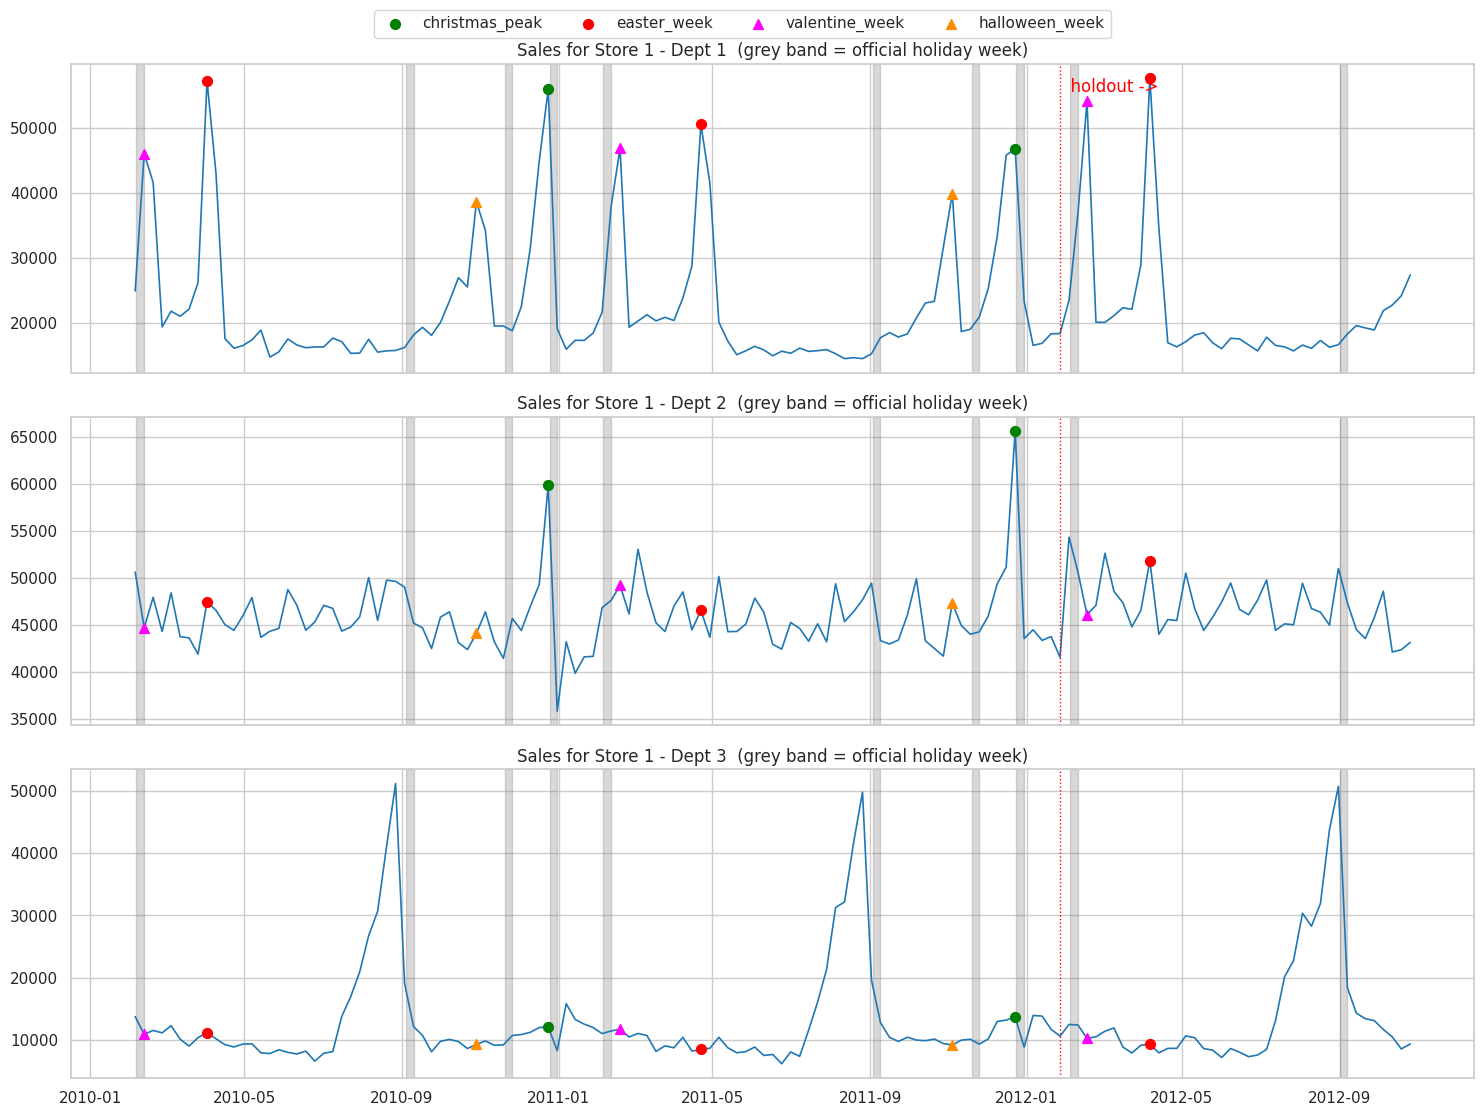

In [81]:
# Store 1, the 3 series, with all the special weeks marked
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
marker_style = {"christmas_peak": ("green", "o"), "easter_week": ("red", "o"),
                "valentine_week": ("magenta", "^"), "halloween_week": ("darkorange", "^")}

for ax, dept in zip(axes, DEPTS):
    s = subset_flags[(subset_flags["Store"] == FOCUS_STORE) & (subset_flags["Dept"] == dept)].sort_values("Date")
    ax.plot(s["Date"], s["Weekly_Sales"], linewidth=1.2, color="tab:blue")
    for d in s.loc[s["is_holiday"] == 1, "Date"]:                    # grey band = official holiday week
        ax.axvspan(d - pd.Timedelta(days=6), d, color="grey", alpha=0.3)
    for flag, (color, marker) in marker_style.items():
        f = s[s[flag] == 1]
        ax.scatter(f["Date"], f["Weekly_Sales"], color=color, marker=marker, s=50, zorder=3, label=flag)
    ax.axvline(split_date, color="red", linestyle=":", linewidth=1)
    ax.set_title(f"Sales for Store {FOCUS_STORE} - Dept {dept}  (grey band = official holiday week)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.02))      # legend above the plots, so it hides no peak
axes[0].text(split_date, axes[0].get_ylim()[1] * 0.93, "  holdout ->", color="red")
plt.tight_layout()
plt.show()

**What I see**

- **Dept 1:** every peak carries a flag: Valentine's / Super Bowl (magenta / grey), Easter (red), Halloween (orange), Christmas (green). In the holdout, the Valentine's (54k) and **Easter (57.6k)** peaks are the two weeks where a forecast can go very wrong.
- **Dept 2:** the green Christmas peak, then the dip in the official Christmas week. Easter and Valentine's mean nothing here.
- **Dept 3:** the back-to-school wave isn't a single week but a **6-week season**, so no dummy describes it well. A seasonal model (lag 52 or Fourier terms) will.

# Part G — Statistical prerequisites for ARIMA / SARIMA / SARIMAX

An ARIMA-type model needs answers to a few questions **before** fitting. This part answers them on the train part only.

| # | Question | Model setting it decides |
|---|---|---|
| G.1 | Does the year repeat itself? | seasonal period `s = 52` |
| G.2 | Is there a trend? | differencing `d` |
| G.3 | Do the wiggles grow with the level? | transformation (log or not) |
| G.4 | Is the series stationary? | confirms `d` (and `D`) |
| G.5 | How long is the short-term memory? | first candidates for `p`, `q` |
| G.6 | How much data does a seasonal model really have? | `P`, `Q`, `D` |
| G.7 | What's the bar to beat? | metric (WMAE) and baselines |

## G.1 Seasonality: year 1 on top of year 2

The train part is exactly 2 years. If I shift year 2 back by 52 weeks and draw it on top of year 1, a strong yearly seasonality shows as two overlapping lines.

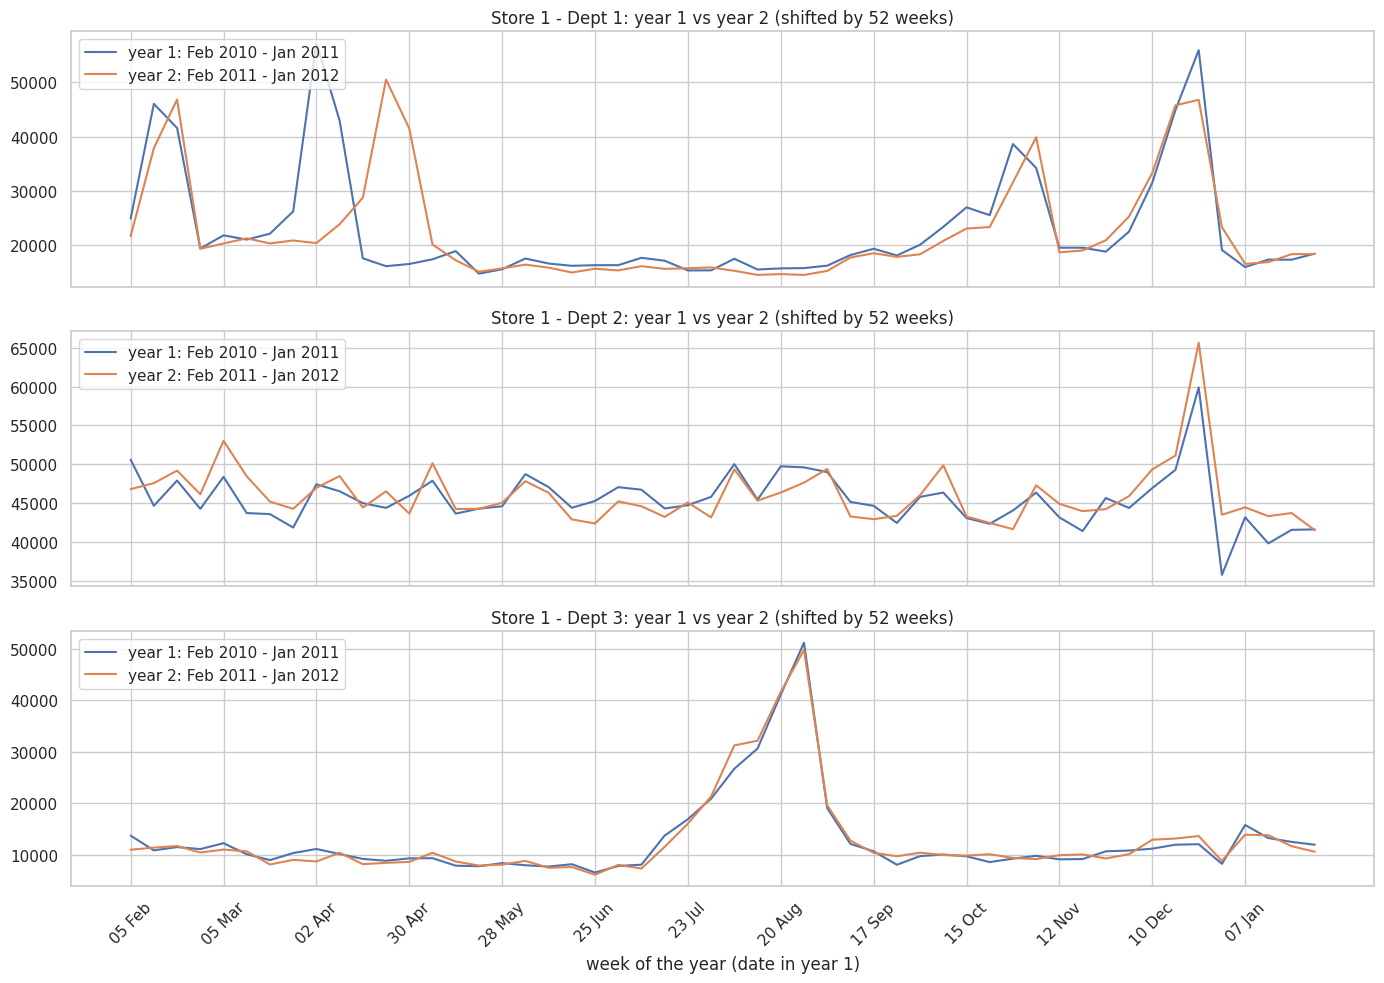

In [82]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, dept in zip(axes, DEPTS):
    s = subset[(subset["Store"] == FOCUS_STORE) & (subset["Dept"] == dept) & (subset["split"] == "train")].sort_values("Date")
    y = s["Weekly_Sales"].values
    ax.plot(range(1, 53), y[:52], label="year 1: Feb 2010 - Jan 2011", linewidth=1.5)
    ax.plot(range(1, 53), y[52:104], label="year 2: Feb 2011 - Jan 2012", linewidth=1.5)
    ax.set_title(f"Store {FOCUS_STORE} - Dept {dept}: year 1 vs year 2 (shifted by 52 weeks)")
    ax.legend(loc="upper left")
week_labels = s["Date"].iloc[:52].dt.strftime("%d %b").values
axes[-1].set_xticks(range(1, 53, 4))
axes[-1].set_xticklabels(week_labels[::4], rotation=45)
axes[-1].set_xlabel("week of the year (date in year 1)")
plt.tight_layout()
plt.show()

### Measuring it: correlation of the 52 pairs vs ACF(52)

The usual tool is the **autocorrelation at lag 52**, ACF(52). But with 104 weeks it has a trap: the ACF formula divides by the length of the **whole** series, while only **52 pairs** exist at lag 52. So ACF(52) comes out roughly **half** of the real correlation. The fair number is the plain Pearson correlation of the 52 pairs (this week, same week last year).

In [83]:
def lag52_numbers(y):
    y = np.asarray(y, dtype=float)
    pairs_r = np.corrcoef(y[52:], y[:-52])[0, 1]       # correlation of the 52 (this week, same week last year) pairs
    acf_52 = acf(y, nlags=52)[52]                      # what plot_acf would show at lag 52
    return pairs_r, acf_52

rows = []
for (store, dept), s in subset[subset["split"] == "train"].groupby(["Store", "Dept"]):
    r, a = lag52_numbers(s.sort_values("Date")["Weekly_Sales"])
    rows.append({"Store": store, "Dept": dept, "pairs correlation": r, "ACF(52)": a})
lag52_table = pd.DataFrame(rows)

print("Store 1:")
print(lag52_table[lag52_table["Store"] == FOCUS_STORE].set_index("Dept").drop(columns="Store").round(2))
print("\nAll 45 stores (median, min, max):")
lag52_table.groupby("Dept")[["pairs correlation", "ACF(52)"]].agg(["median", "min", "max"]).round(2)

Store 1:
      pairs correlation  ACF(52)
Dept                            
1                  0.61     0.31
2                  0.79     0.39
3                  0.99     0.49

All 45 stores (median, min, max):


pairs correlation             ACF(52)            
                median   min   max  median   min   max
Dept                                                  
1                 0.59  0.35  0.82    0.29  0.05  0.40
2                 0.78  0.23  0.94    0.36 -0.11  0.46
3                 0.96  0.33  1.00    0.48  0.04  0.50

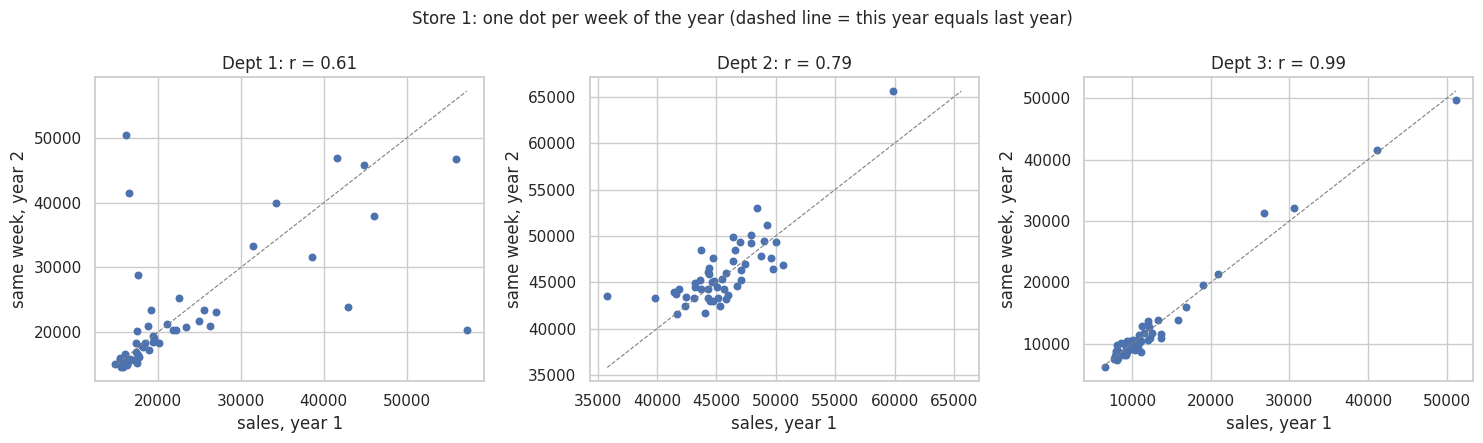

In [84]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, dept in zip(axes, DEPTS):
    y = subset[(subset["Store"] == FOCUS_STORE) & (subset["Dept"] == dept) & (subset["split"] == "train")].sort_values("Date")["Weekly_Sales"].values
    ax.scatter(y[:52], y[52:], s=22)
    lims = [y.min(), y.max()]
    ax.plot(lims, lims, color="grey", linestyle="--", linewidth=0.8)      # points on this line = exact repeat
    r, _ = lag52_numbers(y)
    ax.set_title(f"Dept {dept}: r = {r:.2f}")
    ax.set_xlabel("sales, year 1")
    ax.set_ylabel("same week, year 2")
fig.suptitle(f"Store {FOCUS_STORE}: one dot per week of the year (dashed line = this year equals last year)", fontsize=12)
plt.tight_layout()
plt.show()

**What I see**

| | Dept 1 | Dept 2 | Dept 3 |
|---|---|---|---|
| Store 1, pairs correlation | 0.61 | 0.79 | **0.99** |
| Store 1, ACF(52) | 0.31 | 0.39 | 0.49 |
| 45 stores, median pairs correlation | 0.59 | 0.78 | 0.96 |

- **Dept 3:** year 2 is almost a photocopy of year 1 (r = 0.99).
- **Dept 2:** the years follow each other closely, with week-to-week noise.
- **Dept 1:** most weeks match, but the **Easter peak is in two different places** (early April vs late April). These are the two dots far from the dashed line, and they pull the correlation down.
- The **ACF(52) is about half** of the pairs correlation: exactly the trap explained above.

**Why it matters:** the yearly seasonality is **strong** in all 3 departments, so `s = 52`. And for the report: never judge seasonality at lag 52 from the ACF alone when the series has only 2 seasons.

## G.2 Trend: is the level moving?

With exactly 2 years, the cleanest check is **average of year 2 vs average of year 1**. Both years contain the same calendar weeks, so seasonality cancels out.

In [85]:
rows = []
for (store, dept), s in subset[subset["split"] == "train"].groupby(["Store", "Dept"]):
    y = s.sort_values("Date")["Weekly_Sales"].values
    rows.append({"Store": store, "Dept": dept, "year 1 mean": y[:52].mean(), "year 2 mean": y[52:].mean()})
trend_table = pd.DataFrame(rows)
trend_table["growth %"] = (trend_table["year 2 mean"] / trend_table["year 1 mean"] - 1) * 100

print("Store 1:")
print(trend_table[trend_table["Store"] == FOCUS_STORE].set_index("Dept").drop(columns="Store").round(1))

bins = [-np.inf, -10, -5, 5, 10, np.inf]              # inf so that every series falls in a bin
labels = ["< -10%", "-10% to -5%", "-5% to +5%", "+5% to +10%", "> +10%"]
trend_table["growth class"] = pd.cut(trend_table["growth %"], bins=bins, labels=labels)
growth_classes = pd.crosstab(trend_table["Dept"], trend_table["growth class"])
growth_classes["total"] = growth_classes.sum(axis=1)
growth_classes

Store 1:
      year 1 mean  year 2 mean  growth %
Dept                                    
1         22990.3      22550.2      -1.9
2         45516.2      46081.9       1.2
3         12759.4      12739.8      -0.2


growth class,< -10%,-10% to -5%,-5% to +5%,+5% to +10%,> +10%,total
Dept,,,,,,
1,2,6,23,7,7,45
2,2,3,25,12,3,45
3,2,4,26,5,8,45


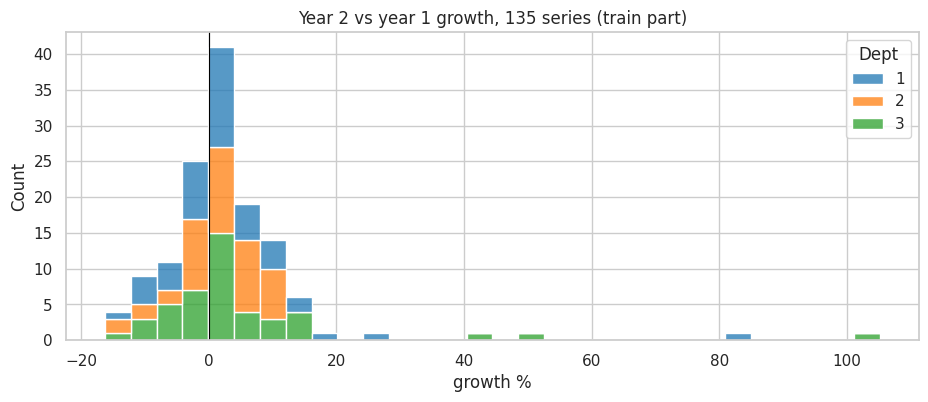

       min  25%  50%  75%    max
Dept                            
1    -16.3 -2.3  1.9  6.9   82.3
2    -16.1 -1.4  1.8  6.3   12.0
3    -16.0 -1.5  1.0  5.4  105.1


In [86]:
plt.figure(figsize=(11, 4))
sns.histplot(data=trend_table, x="growth %", hue="Dept", bins=30, multiple="stack", palette="tab10")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Year 2 vs year 1 growth, 135 series (train part)")
plt.show()
print(trend_table.groupby("Dept")["growth %"].describe()[["min", "25%", "50%", "75%", "max"]].round(1))

**What I see**

- **Store 1:** −1.9%, +1.2%, −0.2%. **No trend.**
- **All 135 series:** median growth **+1% to +2%**. 74 series (55%) move by less than ±5%.
- A minority moves a lot: **18 series grow by more than 10%** (one small Dept 3 store more than doubles), and 6 shrink by more than 10%.

**Why it matters:** for most series, **no differencing** ($d = 0$) is reasonable: the level is stable, and the yearly pattern goes into the seasonal part. A **drift** (constant yearly growth) is worth offering to the models as an option.

## G.3 Variance: do the wiggles grow with the level?

ARIMA assumes the size of the random ups and downs stays constant. In sales data they're usually **proportional** to the level (a store twice as big has swings twice as big). Then the **log** makes them constant.

Two checks: (1) across stores, does the std grow like the mean? (2) the Box-Cox λ of each series (λ = 1: no transformation, 0.5: square root, 0: log).

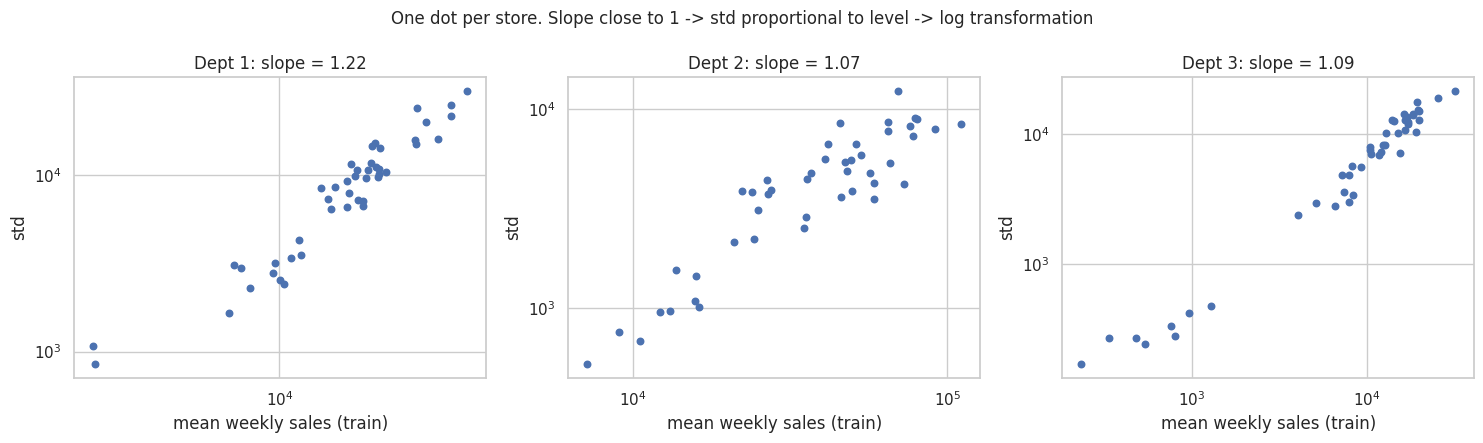

Box-Cox lambda, Store 1: {1: -2.11, 2: -2.26, 3: -1.58}
       min   25%   50%   75%   max
Dept                              
1    -2.85 -2.11 -1.78 -1.49  0.01
2    -5.17 -2.07 -1.45  0.03  4.37
3    -2.28 -1.83 -1.60 -1.41  0.50


In [87]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, dept in zip(axes, DEPTS):
    t = all_series_table[all_series_table["Dept"] == dept]
    ax.scatter(t["mean"], t["std"], s=22)
    ax.set_xscale("log")
    ax.set_yscale("log")
    slope = np.polyfit(np.log(t["mean"]), np.log(t["std"]), 1)[0]       # slope of a straight line in log-log
    ax.set_title(f"Dept {dept}: slope = {slope:.2f}")
    ax.set_xlabel("mean weekly sales (train)")
    ax.set_ylabel("std")
fig.suptitle("One dot per store. Slope close to 1 -> std proportional to level -> log transformation", fontsize=12)
plt.tight_layout()
plt.show()

rows = []
for (store, dept), s in subset[subset["split"] == "train"].groupby(["Store", "Dept"]):
    _, lam = stats.boxcox(s["Weekly_Sales"].values)          # Box-Cox picks the best lambda for this series
    rows.append({"Store": store, "Dept": dept, "lambda": lam})
boxcox_table = pd.DataFrame(rows)
print("Box-Cox lambda, Store 1:", boxcox_table[boxcox_table["Store"] == FOCUS_STORE].set_index("Dept")["lambda"].round(2).to_dict())
print(boxcox_table.groupby("Dept")["lambda"].describe()[["min", "25%", "50%", "75%", "max"]].round(2))

**What I see**

- **Std vs mean across stores:** a straight line with slope **1.22 / 1.07 / 1.09** on the log-log scale. Slope ≈ 1 means "a store twice as big has swings twice as big": the variability is **proportional** to the level.
- **Box-Cox λ:** medians around **−1.5 to −1.8**. A negative λ means an even *stronger* compression than the log: Box-Cox is trying to squash the holiday spikes.

**Decision: model `log(Weekly_Sales)`.** Both checks point the same way (a compression is needed). The log is the standard choice, it's **interpretable** (a change of 0.10 in log ≈ +10% sales), and it's possible because all our sales are > 0. A λ near −2 has no simple meaning and isn't a stable estimate with 104 points dominated by a few spikes. The spikes themselves will be handled by the calendar dummies, not by an extreme transformation.

## G.4 Stationarity tests

**Plain English:** a series is *stationary* if, after hiding the dates, you couldn't tell an old piece from a recent piece: same average level, same size of wiggles, same rhythm. ARMA models estimate **one** set of coefficients for the whole history, so they need this.

| Test | H₀ (assumed until proven wrong) | p < 0.05 means |
|---|---|---|
| **ADF** (Augmented Dickey–Fuller) | NOT stationary (unit root) | → stationary |
| **KPSS** | stationary | → NOT stationary |

Using both is safer, because they ask the question in opposite directions. Warning: with 104 weeks and big holiday spikes, both tests have **little power**, so they support the decision rather than make it.

In [88]:
def stationarity_tests(y):
    y = pd.Series(y).dropna()
    adf_p = adfuller(y, autolag="AIC")[1]
    with warnings.catch_warnings():            # KPSS warns when its p-value is outside [0.01, 0.10]
        warnings.simplefilter("ignore")
        kpss_p = kpss(y, regression="c", nlags="auto")[1]
    adf_says = "stationary" if adf_p < 0.05 else "not stationary"
    kpss_says = "stationary" if kpss_p > 0.05 else "not stationary"
    if adf_says == kpss_says == "stationary":
        verdict = "stationary"
    elif adf_says == kpss_says:
        verdict = "not stationary"
    else:
        verdict = "disagree"
    return {"ADF p": round(adf_p, 3), "KPSS p": round(kpss_p, 3), "verdict": verdict}

rows = []
for (store, dept), s in subset[subset["split"] == "train"].groupby(["Store", "Dept"]):
    r = stationarity_tests(np.log(s.sort_values("Date")["Weekly_Sales"]))
    r.update({"Store": store, "Dept": dept})
    rows.append(r)
stationarity_table = pd.DataFrame(rows)

print("Store 1 (log sales, train part):")
print(stationarity_table[stationarity_table["Store"] == FOCUS_STORE].set_index("Dept").drop(columns="Store"))
verdict_counts = pd.crosstab(stationarity_table["Dept"], stationarity_table["verdict"])
verdict_counts["total"] = verdict_counts.sum(axis=1)
verdict_counts

Store 1 (log sales, train part):
      ADF p  KPSS p     verdict
Dept                           
1     0.000     0.1  stationary
2     0.000     0.1  stationary
3     0.001     0.1  stationary


verdict,disagree,not stationary,stationary,total
Dept,,,,
1,10,2,33,45
2,14,6,25,45
3,1,1,43,45


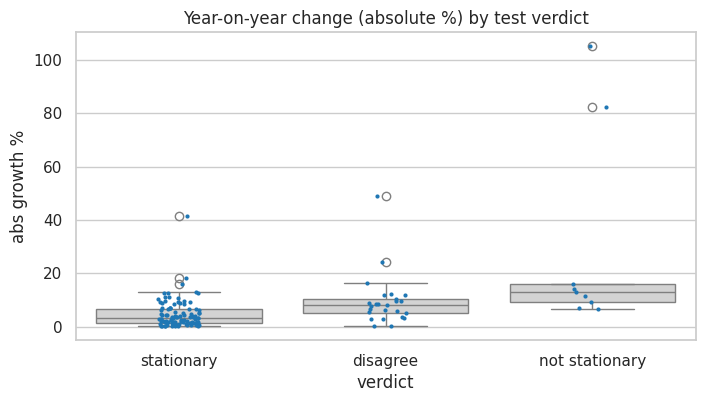

verdict
disagree           8.0
not stationary    13.1
stationary         3.1
Name: abs growth %, dtype: float64


In [89]:
# do the series the tests call "not stationary" have a bigger trend? (link with G.2)
link = stationarity_table.merge(trend_table[["Store", "Dept", "growth %"]], on=["Store", "Dept"])
link["abs growth %"] = link["growth %"].abs()
plt.figure(figsize=(8, 4))
sns.boxplot(data=link, x="verdict", y="abs growth %", order=["stationary", "disagree", "not stationary"], color="lightgrey")
sns.stripplot(data=link, x="verdict", y="abs growth %", order=["stationary", "disagree", "not stationary"], color="tab:blue", size=3)
plt.title("Year-on-year change (absolute %) by test verdict")
plt.show()
print(link.groupby("verdict")["abs growth %"].median().round(1))

**What I see**

- **Store 1:** all 3 series are **stationary** by both tests (ADF p ≤ 0.001, KPSS p ≥ 0.10).
- **All 135 series:** **101 stationary**, 25 where the two tests disagree, 9 not stationary. Dept 3 is the clearest (43 / 45).
- **Link with the trend:** the "stationary" series change by only **3%** year on year (median), the "disagree" ones 8%, the "not stationary" ones **13%**. The tests are picking out exactly the series with a real trend (G.2).

**Why it matters:** default **$d = 0$**, with an optional drift. This is different from many textbook examples, where $d = 1$ is almost automatic. Over 2 years, most of our series simply don't drift.

## G.5 ACF and PACF of Store 1

- **ACF**: "how similar is this week to the week *k* weeks ago?"
- **PACF**: same question, **after removing** what the weeks in between already explain.
- Blue band: the 95% "could be zero" zone.

Reading rules (Box–Jenkins): ACF decays slowly + PACF cuts off after lag *p* → **AR(p)**; ACF cuts off after lag *q* + PACF decays → **MA(q)**. With 104 points `plot_pacf` can only go up to lag 51, so lag 52 is only visible in the ACF (and, as G.1 showed, it's about half its real size there).

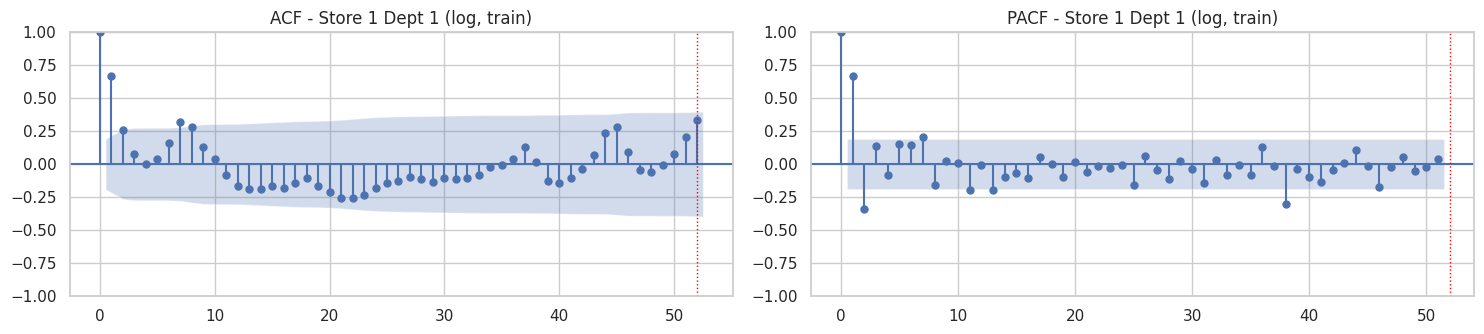

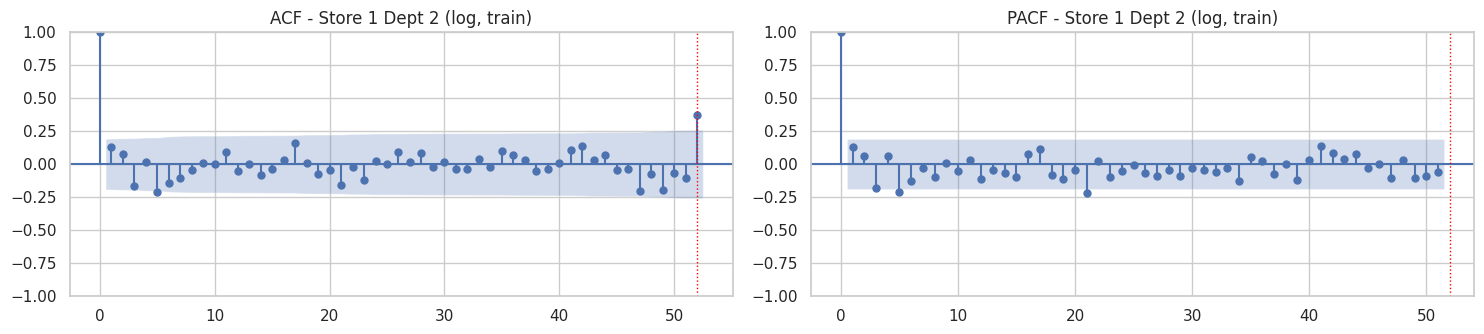

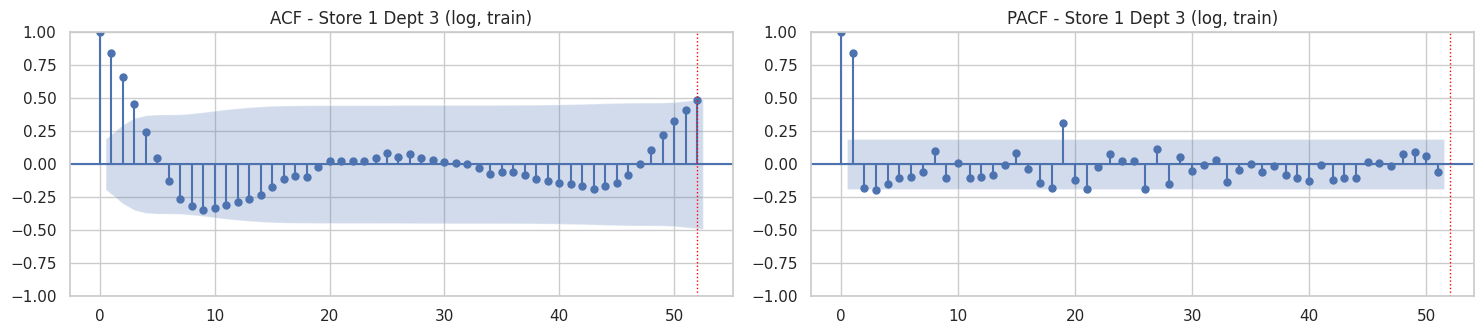

In [90]:
for dept in DEPTS:
    y = subset[(subset["Store"] == FOCUS_STORE) & (subset["Dept"] == dept) & (subset["split"] == "train")].sort_values("Date")["Weekly_Sales"]
    fig, axes = plt.subplots(1, 2, figsize=(15, 3.5))
    plot_acf(np.log(y.values), lags=52, ax=axes[0], title=f"ACF - Store {FOCUS_STORE} Dept {dept} (log, train)")
    plot_pacf(np.log(y.values), lags=51, ax=axes[1], method="ywm", title=f"PACF - Store {FOCUS_STORE} Dept {dept} (log, train)")
    for ax in axes:
        ax.axvline(52, color="red", linestyle=":", linewidth=1)
    plt.tight_layout()
    plt.show()

In [91]:
key_lags = [1, 2, 3, 4, 8, 13, 26, 52]
acf_rows = {}
for dept in DEPTS:
    y = subset[(subset["Store"] == FOCUS_STORE) & (subset["Dept"] == dept) & (subset["split"] == "train")].sort_values("Date")["Weekly_Sales"]
    a = acf(np.log(y.values), nlags=52)
    acf_rows[f"Dept {dept}"] = [round(a[k], 2) for k in key_lags]
print("ACF of log(sales), Store 1, train part. 95% band ~ +/-", round(1.96 / np.sqrt(104), 2))
pd.DataFrame(acf_rows, index=[f"lag {k}" for k in key_lags]).T

ACF of log(sales), Store 1, train part. 95% band ~ +/- 0.19


,lag 1,lag 2,lag 3,lag 4,lag 8,lag 13,lag 26,lag 52
Dept 1,0.67,0.26,0.08,0.00,0.28,-0.19,-0.13,0.34
Dept 2,0.13,0.08,-0.16,0.02,-0.05,0.00,0.09,0.37
Dept 3,0.84,0.66,0.45,0.24,-0.32,-0.27,0.06,0.49


**What I see** (log scale, train part, Store 1, 95% band ≈ ±0.19)

- **Dept 1:** ACF(1) = 0.67, then a quick drop; the PACF cuts off after lag 2 → **AR(1)–AR(2)**. Busy weeks come in pairs (a peak lasts about 2 weeks). The bumps at lags 7–8 are the gaps between holidays (e.g. Valentine's → Easter), not a real 8-week cycle.
- **Dept 2:** ACF(1) = 0.13, almost nothing outside the band → **almost no short-term memory**.
- **Dept 3:** a slow decay 0.84 → 0.66 → 0.45 → 0.24 → **AR(1)–AR(2)**, caused by the 6-week back-to-school ramp.
- **Lag 52:** 0.34 / 0.37 / 0.49, at the edge of the band, but remember G.1: the real yearly correlation is about twice that.

**Why it matters:** these are the **first candidates for $p$ and $q$**. The models will try $p, q \in \{0, 1, 2\}$ and let AICc decide.

## G.6 The data budget of a seasonal model

**Seasonal differencing** (`D = 1`, `s = 52`) means modelling *this week − same week last year*. With 104 weeks, only **52** such differences exist.

In [92]:
budget = pd.DataFrame({
    "the model works on": ["log(sales)", "this week - last week", "this week - same week last year", "both differences"],
    "points left (out of 104)": [104, 103, 52, 51],
}, index=["no differencing", "d = 1", "D = 1, s = 52", "d = 1 and D = 1"])
budget

,the model works on,points left (out of 104)
no differencing,log(sales),104
d = 1,this week - last week,103
"D = 1, s = 52",this week - same week last year,52
d = 1 and D = 1,both differences,51


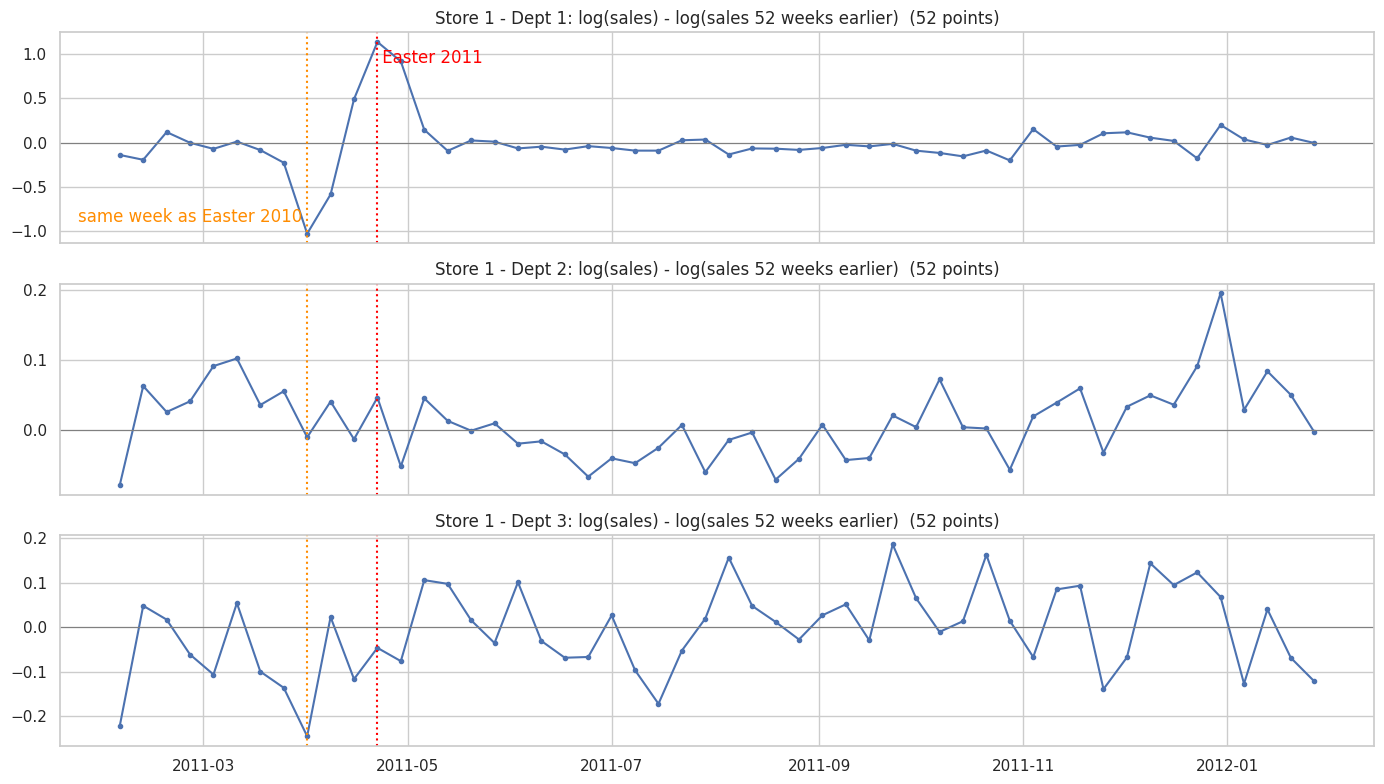

In [93]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, dept in zip(axes, DEPTS):
    s = subset[(subset["Store"] == FOCUS_STORE) & (subset["Dept"] == dept) & (subset["split"] == "train")].sort_values("Date")
    y_log = pd.Series(np.log(s["Weekly_Sales"].values), index=s["Date"].values)
    seasonal_diff = (y_log - y_log.shift(52)).dropna()          # this week - same week last year (log scale ~ % change)
    ax.plot(seasonal_diff.index, seasonal_diff.values, marker="o", markersize=3)
    ax.axhline(0, color="grey", linewidth=0.8)
    # red = Easter week 2011 (compared with a normal week of 2010)
    # orange = the week 52 weeks after Easter 2010 (a normal 2011 week compared with the 2010 Easter peak)
    ax.axvline(pd.Timestamp("2011-04-22"), color="red", linestyle=":", linewidth=1.5)
    ax.axvline(pd.Timestamp("2010-04-02") + pd.Timedelta(weeks=52), color="darkorange", linestyle=":", linewidth=1.5)
    ax.set_title(f"Store {FOCUS_STORE} - Dept {dept}: log(sales) - log(sales 52 weeks earlier)  ({len(seasonal_diff)} points)")
axes[0].text(pd.Timestamp("2011-04-22"), 0.9, " Easter 2011", color="red")
axes[0].text(pd.Timestamp("2011-04-01"), -0.9, "same week as Easter 2010 ", color="darkorange", ha="right")
plt.tight_layout()
plt.show()

**What I see**

- After seasonal differencing only **52 points** remain, each one "this year vs last year".
- **Dept 1:** calm, except for **two huge swings around Easter 2011**: about −1.0 at the orange line (a normal week of 2011 compared with the **Easter 2010 peak**) and +1.1 at the red line (the **Easter 2011 peak** compared with a normal week of 2010), i.e. roughly ÷3 then ×3. **One moving holiday creates two fake spikes** in the seasonal difference.
- **Dept 2 / Dept 3:** small changes around 0 (about ±5% and ±10% per year).

**Why it matters:** with only 52 points, the seasonal AR / MA terms of a SARIMA can't be estimated (the modelling notebook explains why exactly). The moving holidays must be **corrected explicitly** (SARIMAX with dummies), otherwise the model learns the fake spikes as normal behaviour.

## G.7 The metric and the bar to beat

**WMAE** (teammate's metric, from the competition):

$$WMAE = \frac{\sum_i w_i\,|y_i - \hat y_i|}{\sum_i w_i}, \qquad w_i = 5 \text{ for holiday weeks } (\texttt{is\_holiday}=1), \text{ else } 1$$

In words: the average error in dollars, where an error in a holiday week counts 5 times.

Three simple **baselines**, forecasting the 39 holdout weeks from the end of the train part:

| Baseline | Forecast | Idea |
|---|---|---|
| naive | the last train week, repeated | "nothing changes" |
| mean | the average of the train part | "a normal week" |
| seasonal naive | the same week one year earlier | "this year = last year" |

In [94]:
def wmae(y_true, y_pred, is_holiday):
    w = np.where(np.asarray(is_holiday) == 1, 5, 1)
    return np.sum(w * np.abs(np.asarray(y_true) - np.asarray(y_pred))) / np.sum(w)

rows = []
for (store, dept), s in subset.groupby(["Store", "Dept"]):
    s = s.sort_values("Date")
    y_train = s.loc[s["split"] == "train", "Weekly_Sales"].values
    y_hold = s.loc[s["split"] == "test", "Weekly_Sales"].values
    h_hold = s.loc[s["split"] == "test", "is_holiday"].values
    horizon = len(y_hold)
    rows.append({"Store": store, "Dept": dept,
                 "naive": wmae(y_hold, np.repeat(y_train[-1], horizon), h_hold),
                 "mean": wmae(y_hold, np.repeat(y_train.mean(), horizon), h_hold),
                 "seasonal naive": wmae(y_hold, y_train[-52:][:horizon], h_hold)})
baseline_table = pd.DataFrame(rows)

print("holdout weeks with weight 5:", [d.date() for d in subset.loc[(subset["split"] == "test") & (subset["is_holiday"] == 1), "Date"].unique()])
print("\nStore 1 (WMAE in $):")
print(baseline_table[baseline_table["Store"] == FOCUS_STORE].set_index("Dept").drop(columns="Store").round(0))
print("\nMean WMAE over the 45 stores ($):")
print(baseline_table.groupby("Dept")[["naive", "mean", "seasonal naive"]].mean().round(0))
best = baseline_table[["naive", "mean", "seasonal naive"]].idxmin(axis=1)
pd.crosstab(baseline_table["Dept"], best).rename_axis(columns="best baseline")

holdout weeks with weight 5: [datetime.date(2012, 2, 10), datetime.date(2012, 9, 7)]

Store 1 (WMAE in $):
       naive    mean  seasonal naive
Dept                                
1     5748.0  6847.0          3486.0
2     5703.0  2390.0          1990.0
3     5457.0  5546.0          2607.0

Mean WMAE over the 45 stores ($):
       naive    mean  seasonal naive
Dept                                
1     5099.0  5775.0          3907.0
2     6264.0  3238.0          2643.0
3     5889.0  6246.0          1991.0


best baseline,mean,naive,seasonal naive
Dept,,,
1,3,4,38
2,12,3,30
3,0,1,44


**What I see**

- **Store 1, seasonal naive WMAE:** 3,486 (Dept 1), 1,990 (Dept 2), 2,607 (Dept 3), 35–55% lower than the naive forecast.
- **All stores:** seasonal naive is the best baseline for **112 of 135 series** (Dept 1: 38, Dept 2: 30, Dept 3: 44). The plain mean wins 12 times in Dept 2, which fits its weak seasonality and lack of short-term memory.
- In the holdout only **2 weeks have weight 5** (Super Bowl 2012-02-10 and Labor Day 2012-09-07). The Easter week, where seasonal naive makes its biggest mistake in Dept 1, has weight 1.

**Why it matters:** **seasonal naive is the bar** every statistical model must beat. A model that can't beat "same week last year" adds nothing.

# Part H — Summary and export

## What the EDA tells us

| # | Area | Finding |
|---|---|---|
| 1 | Files | `train` (421,570 rows, 3,331 series, 143 weeks, no missing), `features` (8,190 rows, markdowns only from Nov 2011, CPI / unemployment missing at the end), `test` (39 weeks, 11 cold-start pairs), `stores` (45 stores; type ≈ size class) |
| 2 | Whole dataset | flat level, strong yearly seasonality; the biggest weeks are **the week before Christmas** and **Thanksgiving**; three of the four official holidays are ordinary weeks |
| 3 | Departments | very concentrated (29 departments = 80% of sales); 2,660 complete series; 21 "clean" departments |
| 4 | Data processing | teammate's panel: 54,763 missing weeks (mostly interior gaps ≈ zero sales), 1,285 negatives clipped, 389 short series |
| 5 | Depts 1–3 | 135 complete, positive series; three different profiles: multi-holiday (1), stable (2), back-to-school (3); Store 1 is representative |
| 6 | Calendar | `Date` = Friday ending a Saturday–Friday week; the flagged Christmas week is *after* Christmas; pre-holiday peaks = week containing the day 2 days before the holiday; **Easter, Valentine's and Halloween shopping weeks move** relative to lag 52 |

## Prerequisites for the statistical models → decisions

| Prerequisite | Finding | Decision |
|---|---|---|
| clean series | 135 × 143 weeks, no missing / negative / zero | use the teammate's subset as it is |
| roles | train part 104 w → holdout 39 w; `test.csv` without sales | fit on `split == "train"`, score with WMAE on `split == "test"`; `test.csv` for the final forecast |
| seasonality | strong yearly repeat (median pairs correlation 0.59 / 0.78 / 0.96) | yearly seasonal part, `s = 52` |
| trend | median growth +1–2%; a few trending series | $d = 0$, optional drift |
| variance | std ∝ level | model **log(sales)** |
| stationarity | 101 / 135 stationary; the rest trend | confirms $d = 0$ (+ drift) |
| short memory | Dept 1 & 3: AR(1)–AR(2); Dept 2: almost none | try $p, q \in \{0,1,2\}$ |
| data budget | 52 points after $D = 1$ | no seasonal AR / MA with $D = 1$ |
| moving holidays | Easter (+ Valentine's / Halloween in 2010→11) | calendar dummies, SARIMAX |
| benchmark | seasonal naive best baseline for 112 / 135 | every model must beat seasonal naive |

The cell below saves the two files the modelling notebook reads.

In [95]:
# 1) the calendar of all 182 weeks (train part + holdout + forecast set), needed to forecast test.csv later
calendar_cols = ["Date", "week_start", "year", "week_of_year", "t", "role", "is_holiday", "holiday_name"] + new_flags
week_calendar[calendar_cols].to_csv(DATA_DIR + "week_calendar.csv", index=False)

# 2) the teammate's subset + the calendar columns
stat_ready = subset.merge(week_calendar[["Date", "week_start", "year", "week_of_year", "t", "holiday_name"] + new_flags],
                          on="Date", how="left")
stat_ready = stat_ready.sort_values(["Dept", "Store", "Date"]).reset_index(drop=True)    # same order as depts_1_to_3.csv

# final checks
assert len(stat_ready) == len(subset)
assert (stat_ready[cols].values == subset[cols].values).all()       # the teammate's 6 columns are unchanged
assert (stat_ready["Weekly_Sales"] > 0).all()                         # log is possible everywhere

stat_ready.to_csv(DATA_DIR + "depts_1_to_3_stat.csv", index=False)
print("saved:", DATA_DIR + "week_calendar.csv", week_calendar[calendar_cols].shape)
print("saved:", DATA_DIR + "depts_1_to_3_stat.csv", stat_ready.shape)
stat_ready.head(3)

saved: Data/week_calendar.csv (182, 16)
saved: Data/depts_1_to_3_stat.csv (19305, 19)


,Store,Dept,Date,Weekly_Sales,split,is_holiday,week_start,year,week_of_year,t,holiday_name,superbowl,valentine_week,easter_week,labor_day,halloween_week,thanksgiving,christmas_peak,christmas
0,1,1,2010-02-05,24924.50,train,0,2010-01-30,2010,5,0,,0,0,0,0,0,0,0,0
1,1,1,2010-02-12,46039.49,train,1,2010-02-06,2010,6,1,Super Bowl,1,1,0,0,0,0,0,0
2,1,1,2010-02-19,41595.55,train,0,2010-02-13,2010,7,2,,0,0,0,0,0,0,0,0


### Columns of `depts_1_to_3_stat.csv`

| Column | Source | Meaning |
|---|---|---|
| `Store`, `Dept`, `Date`, `Weekly_Sales`, `split`, `is_holiday` | teammate, **unchanged** | same as `depts_1_to_3.csv` (`split == "test"` = holdout) |
| `week_start` | F.1 | the Saturday that opens the week (`week_start` → `Date`) |
| `year`, `week_of_year` | F.1 | calendar position (ISO week) |
| `t` | F.1 | week counter (0 = 2010-02-05), used to build Fourier terms |
| `holiday_name` | F.1 | official holiday name, empty otherwise |
| `superbowl`, `labor_day`, `thanksgiving`, `christmas` | F.5 | `is_holiday` split by holiday |
| `christmas_peak`, `easter_week`, `valentine_week`, `halloween_week` | F.5 | pre-holiday shopping weeks |

`week_calendar.csv` has the same calendar columns for **all 182 weeks**, including the 39 weeks of `test.csv`, so the models can also forecast the forecast set.

**Next notebook:** `FPA_Project_Statistical_Models.ipynb`: theory of ARIMA / SARIMA / SARIMAX, then the models on Store 1 and on all 135 series.